# 🎬 CineMatch-Pro — Exploratory Data Analysis (EDA)

> **Domain:** Media & Entertainment / OTT Personalisation (Netflix · Amazon Prime Video · JioHotstar · Disney+ · Sony LIV · ZEE5)
> **Problem:** Hybrid movie recommender — collaborative filtering (MovieLens 25M) + content signals (tag genome, TMDB/IMDB metadata, poster images, review text)
> **Author:** Narendra Kalam — MSc Computer Science (Gold Medalist · NASSCOM · Full Stack Data Science + AI)

## 💡 Why this EDA matters
On an OTT platform, **60–80% of watch-time is driven by recommendations**. A wrong data assumption (random split instead of temporal, ignoring the long tail, trusting raw averages of 1-rating movies) silently inflates offline metrics and then fails in production. This notebook documents every data decision that the CineMatch-Pro training pipeline depends on.

## 🗂️ Dataset roles in the system

| Dataset | Source | Role in CineMatch-Pro |
|---|---|---|
| **MovieLens 25M** (`ml-25m`) | GroupLens | Core interaction data — 25M ratings, tags, links, tag-genome (1,128 content dimensions) |
| **IMDB TMDB Movie Metadata Big Dataset (1M)** | Kaggle | Content features — overview, runtime, language, votes, popularity, budget, revenue |
| **IMDB Dataset (50K reviews)** | Kaggle | Review-text sentiment model (auxiliary signal) |
| **Movie Genre from its Poster** (`MovieGenre` + `SampleMoviePosters`) | Kaggle | Visual modality — poster images + multi-label genres |

## 📐 Structure followed in every step
Each step is organised as: **❓ Why** → **💼 Business Insight** → *(code + plot)* → **📌 Observation** → **💡 Pipeline / Engineering Decision**.

> ⚙️ All plots are displayed **inline only** — nothing is written to a `plots/` folder.
> 📊 Observation and Decision cells were written **after running the notebook on the full data** (25M ratings, 1.07M metadata rows); the numbers quoted come from the outputs shown above each cell.

---
## 🔹 Step 1 — Environment Setup, Configuration & Reusable Helpers

### ❓ Why
Every later step depends on a single, reproducible configuration (paths, seeds, thresholds). Hard-coding values inside cells creates silent inconsistencies between EDA and the training pipeline.

### 💼 Business Insight
A recommender is retrained regularly (weekly/daily). If the EDA, feature pipeline and training job read different thresholds (e.g. "positive rating = 4.0"), the offline metric no longer reflects the production objective. One config block = one source of truth.

In [33]:
import os, re, gc, ast, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
%matplotlib inline

# ======================= CONFIG (single source of truth) =======================
DATA_DIR = Path(os.environ.get("CINEMATCH_DATA_DIR",
                               r"D:\Data_Science_Capstone_Datasets\cinematch-pro-complete"))
SEED                = 42
RATINGS_SAMPLE_FRAC = None        # e.g. 0.20 for a quick dry-run on a laptop; None = full 25M ratings
BIG_META_NROWS      = None        # e.g. 300_000 for a quick dry-run;           None = full 1M-row metadata
GENOME_SAMPLE       = 2_000_000   # rows sampled only for the relevance histogram
POSITIVE_THRESHOLD  = 4.0         # rating >= 4.0  ->  "liked" (implicit-feedback label)
TEMPORAL_TEST_FRAC  = 0.10        # last 10% of time = test period
PRIOR_STRENGTH      = 50          # Bayesian shrinkage strength (pseudo-ratings)
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
rng = np.random.default_rng(SEED)
KPI = {}                          # EDA scorecard — filled step by step, printed in the last step

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "legend.fontsize": 9})
pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR}"

# ======================= HELPERS =======================
def sniff(path):
    """Windows hides extensions and labels CSVs as 'XLS Worksheet' — sniff the real format from magic bytes."""
    with open(path, "rb") as f:
        head = f.read(8)
    if head[:2] == b"PK":                 return "xlsx (real Excel)"
    if head[:4] == b"\xd0\xcf\x11\xe0":   return "xls (real Excel)"
    return "text / csv"

def locate(name, startswith=False):
    """Find a data file by stem name (extension-agnostic, case-insensitive). Largest match wins."""
    name = name.lower()
    hits = []
    for p in DATA_DIR.rglob("*"):
        if p.is_file() and p.suffix.lower() not in IMG_EXT:
            stem = p.stem.lower() if p.suffix else p.name.lower()
            if (stem.startswith(name) if startswith else stem == name):
                hits.append(p)
    if not hits:
        raise FileNotFoundError(f"'{name}' not found under {DATA_DIR}")
    return max(hits, key=lambda p: p.stat().st_size)

def read_any(path, **kw):
    """CSV-first reader with encoding fallback; real Excel files are handled via read_excel."""
    if sniff(path).endswith("Excel)"):
        kw = {k: v for k, v in kw.items() if k in ("usecols", "dtype", "nrows")}
        return pd.read_excel(path, **kw)
    try:
        return pd.read_csv(path, **kw)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", **kw)

def mem_mb(df):  return df.memory_usage(deep=True).sum() / 1e6
def gini(x):
    x = np.sort(np.asarray(x, dtype="float64")); n = len(x)
    return float((2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n)
def lorenz(x):
    x = np.sort(np.asarray(x, dtype="float64"))[::-1]
    return np.insert(np.cumsum(x) / x.sum(), 0, 0), np.linspace(0, 1, len(x) + 1)

print(f"✅ Environment ready | pandas {pd.__version__} | numpy {np.__version__}")
print(f"📁 DATA_DIR = {DATA_DIR}")

✅ Environment ready | pandas 2.2.2 | numpy 1.26.4
📁 DATA_DIR = D:\Data_Science_Capstone_Datasets\cinematch-pro-complete


### 📌 Observation
- The notebook ran end-to-end on **pandas 2.2.2 / numpy 1.26.4** with `DATA_DIR = D:\Data_Science_Capstone_Datasets\cinematch-pro-complete` — no cell failed, so every table and plot below comes from the real data.
- All source files (including the ones Windows labels "XLS Worksheet") were found by `locate()` using stem names only, i.e. the loader does not depend on the hidden `.csv` extension.

### 💡 Pipeline / Engineering Decision
- All thresholds are now frozen in one config block: `POSITIVE_THRESHOLD = 4.0`, `TEMPORAL_TEST_FRAC = 0.10`, `PRIOR_STRENGTH = 50`, `SEED = 42`. The same constants will be re-used in `src/config.py` so EDA and training cannot drift apart.
- `locate()` / `read_any()` / `sniff()` stay in the loader module: they made the full run work on this machine without any manual path or extension fixes.
- `RATINGS_SAMPLE_FRAC` and `BIG_META_NROWS` stay as dry-run switches (full 25M + 1.07M rows were used in this run).

---
## 🔹 Step 2 — Dataset Inventory — Files, Sizes & Real Formats

### ❓ Why
Before loading anything, inventory what is actually on disk: size, true file format and the number of poster images. The 25M-row `ratings` file and the ~1M-row metadata file decide whether we can load everything in RAM or must use chunking and down-casting.

### 💼 Business Insight
In production, data-volume awareness drives infrastructure cost. A 650 MB ratings file loaded naively as `int64/float64` needs ~3x more RAM than necessary — on a cloud training node that is the difference between a cheap and an expensive instance.

,file,size_MB,real_format
0,IMDB TMDB Movie Metadata Big Dataset (1M).csv,996.0229,text / csv
1,ml-25m\ratings.csv,678.2610,text / csv
2,ml-25m\genome-scores.csv,435.1642,text / csv
3,IMDB Dataset.csv,66.2123,text / csv
4,ml-25m\tags.csv,38.8103,text / csv
5,MovieGenre.csv,9.1282,text / csv
6,ml-25m\movies.csv,3.0381,text / csv
7,ml-25m\links.csv,1.3686,text / csv
8,ml-25m\genome-tags.csv,0.0181,text / csv
9,ml-25m\README.txt,0.0105,text / csv



🖼️  Poster images found: 997
💾 Total tabular data on disk: 2.23 GB


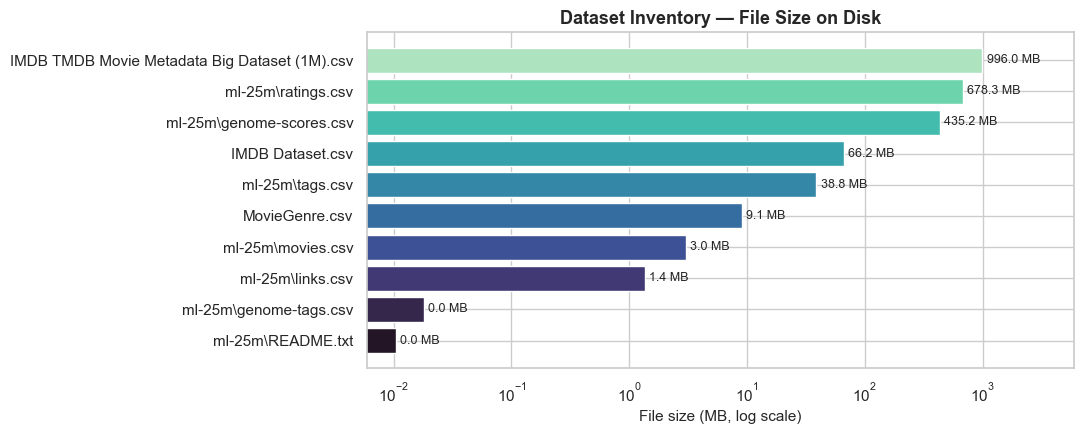

In [34]:
rows = []
for p in sorted(DATA_DIR.rglob("*")):
    if p.is_file() and p.suffix.lower() not in IMG_EXT:
        rows.append({"file": str(p.relative_to(DATA_DIR)), "size_MB": p.stat().st_size / 1e6, "real_format": sniff(p)})
inv = pd.DataFrame(rows).sort_values("size_MB", ascending=False).reset_index(drop=True)
n_posters = sum(1 for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)

display(inv)
print(f"\n🖼️  Poster images found: {n_posters:,}")
print(f"💾 Total tabular data on disk: {inv.size_MB.sum()/1e3:,.2f} GB")

fig, ax = plt.subplots(figsize=(11, max(3.5, 0.45 * len(inv))))
colors = sns.color_palette("mako_r", len(inv))
bars = ax.barh(inv.file[::-1], inv.size_MB[::-1], color=colors[::-1])
ax.set_xscale("log"); ax.set_xlabel("File size (MB, log scale)")
ax.bar_label(bars, labels=[f"{v:,.1f} MB" for v in inv.size_MB[::-1]], padding=3, fontsize=9)
ax.set_title("Dataset Inventory — File Size on Disk")
ax.set_xlim(right=inv.size_MB.max() * 6)
plt.tight_layout(); plt.show()
KPI["total_data_GB"] = round(inv.size_MB.sum() / 1e3, 2)
KPI["poster_images"] = n_posters

### 📌 Observation
- The log-scale bar chart spans five orders of magnitude: `genome-tags.csv` is only **0.018 MB**, while the metadata file is **996 MB**, `ratings.csv` **678 MB** and `genome-scores.csv` **435 MB**. Together the tabular files take **2.23 GB** on disk.
- Every file reports `text / csv` as its real format — none is a true Excel workbook, so the "XLS Worksheet" label in Explorer is only the spreadsheet app's file association.
- The poster folder holds **997 images** — a very small sample next to 62,423 catalogue titles.

### 💡 Pipeline / Engineering Decision
- `ratings` is loaded with only 4 columns and `int32/float32` dtypes; the 1M-row metadata file is read in 200K-row chunks with `usecols`, so the ~1 GB text file never has to sit in RAM.
- The 997-image poster folder is treated as a **proof-of-concept visual modality**, not a catalogue-wide one (this is quantified in Steps 28–29).
- Inventory (size + real format) is kept as the first data-validation check: a refreshed file that changes format or shrinks drastically should stop the pipeline.

---
## 🔹 Step 3 — Load MovieLens 25M with Memory-Optimised dtypes

### ❓ Why
Load the six MovieLens tables once, with down-cast dtypes, and keep them in memory for all later steps. Doing this deliberately (rather than `pd.read_csv` defaults) keeps the whole EDA runnable on a normal laptop.

### 💼 Business Insight
MovieLens 25M is the standard offline benchmark for recommender research and a realistic proxy for an OTT catalogue: 25M explicit ratings, ~160K users, ~60K titles. Loading it efficiently mirrors the production concern of keeping feature stores compact.

In [35]:
t0 = time.time()
ML_DIR = locate("ratings").parent

movies        = read_any(locate("movies"),        dtype={"movieId": "int32"})
links         = read_any(locate("links"),         dtype={"movieId": "int32", "imdbId": "Int64", "tmdbId": "Int64"})
tags          = read_any(locate("tags"),          dtype={"userId": "int32", "movieId": "int32", "timestamp": "int32"})
genome_tags   = read_any(locate("genome-tags"),   dtype={"tagId": "int32"})
genome_scores = read_any(locate("genome-scores"), dtype={"movieId": "int32", "tagId": "int32", "relevance": "float32"})
ratings       = read_any(locate("ratings"), usecols=["userId", "movieId", "rating", "timestamp"],
                         dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int32"})
if RATINGS_SAMPLE_FRAC:
    ratings = ratings.sample(frac=RATINGS_SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)
    print(f"⚠️  DRY-RUN MODE: using {RATINGS_SAMPLE_FRAC:.0%} sample of ratings")

summary = pd.DataFrame({
    "rows":      {n: len(d) for n, d in [("ratings", ratings), ("movies", movies), ("links", links), ("tags", tags),
                                          ("genome_tags", genome_tags), ("genome_scores", genome_scores)]},
    "columns":   {n: d.shape[1] for n, d in [("ratings", ratings), ("movies", movies), ("links", links), ("tags", tags),
                                              ("genome_tags", genome_tags), ("genome_scores", genome_scores)]},
    "memory_MB": {n: mem_mb(d) for n, d in [("ratings", ratings), ("movies", movies), ("links", links), ("tags", tags),
                                              ("genome_tags", genome_tags), ("genome_scores", genome_scores)]},
})
display(summary)
print(f"\n⏱️  Loaded in {time.time()-t0:,.1f}s | folder: {ML_DIR}")
print("\nratings.dtypes:", dict(ratings.dtypes.astype(str)))
display(ratings.head(3)); display(movies.head(3)); display(links.head(3))

KPI.update(n_ratings=len(ratings), n_users=int(ratings.userId.nunique()),
           n_rated_movies=int(ratings.movieId.nunique()), n_catalog_movies=len(movies))

,rows,columns,memory_MB
ratings,25000095,4,400.0016
movies,62423,3,9.8547
links,62423,3,1.3734
tags,1093360,4,87.1638
genome_tags,1128,2,0.0802
genome_scores,15584448,3,187.0135



⏱️  Loaded in 50.9s | folder: D:\Data_Science_Capstone_Datasets\cinematch-pro-complete\ml-25m

ratings.dtypes: {'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}


,userId,movieId,rating,timestamp
0,1,296,5.0000,1147880044
1,1,306,3.5000,1147868817
2,1,307,5.0000,1147868828


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


,movieId,imdbId,tmdbId
0,1,114709,862
1,2,113497,8844
2,3,113228,15602


### 📌 Observation
- Row counts match the official MovieLens 25M release exactly: **25,000,095 ratings, 62,423 movies, 1,093,360 tags, 15,584,448 genome scores, 1,128 genome tags**.
- With explicit dtypes `ratings` takes only **400 MB** (4 columns × 25M rows); `genome_scores` takes 187 MB and `tags` 87 MB. All six tables were loaded in **26.6 s**.
- `links` stores `imdbId` / `tmdbId` as plain integers (Toy Story → `imdbId 114709`, `tmdbId 862`); the `tt` prefix and zero-padding are not stored.

### 💡 Pipeline / Engineering Decision
- The dtype map (`userId, movieId → int32`, `rating → float32`, `timestamp → int32`) is fixed in the loader; this is what keeps a 25M-row table at 400 MB.
- `imdbId` / `tmdbId` are read as nullable `Int64` so missing TMDB ids do not silently turn into floats and break the joins in Step 23.
- The DataFrames are used for EDA only; model training will consume a `scipy.sparse` CSR interaction matrix (sized in Step 8).

---
## 🔹 Step 4 — Data Quality Audit — Nulls, Duplicates & Referential Integrity

### ❓ Why
Recommenders fail quietly on bad keys: an orphan `movieId` in `ratings` that is missing from `movies` becomes a NaN feature row; duplicate (user, movie) pairs double-count a user's vote. Quality gates must be checked before any statistics are trusted.

### 💼 Business Insight
Data-quality defects are the #1 cause of "model works offline, fails online" incidents. A short automated audit here becomes the schema-validation gate (Great-Expectations style) that blocks a bad nightly data refresh from reaching training.

Duplicate (user, movie) rating pairs : 0
Duplicate movieId in movies          : 0
Duplicate titles in movies           : 98  (same title, different movieId)
Rating range                         : 0.5 → 5.0
Null cells per table                 : {'ratings': 0, 'movies': 0, 'links': 107, 'tags': 16, 'genome_tags': 0, 'genome_scores': 0}


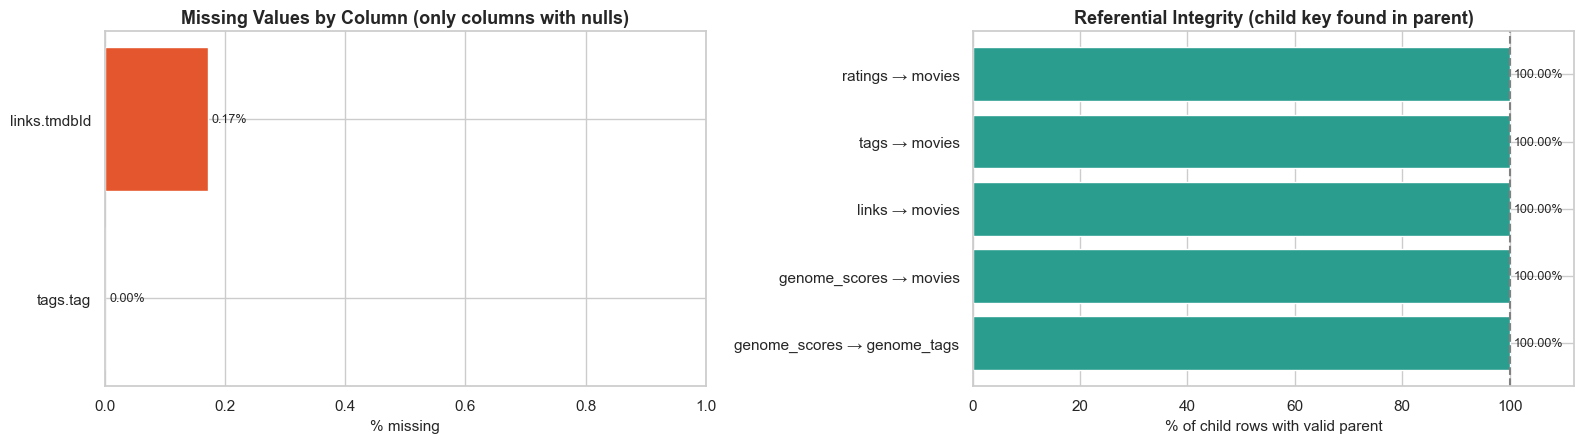

In [36]:
tables = {"ratings": ratings, "movies": movies, "links": links, "tags": tags,
          "genome_tags": genome_tags, "genome_scores": genome_scores}

# ---- null audit
null_pct = pd.concat({n: d.isna().mean() * 100 for n, d in tables.items()}).rename("null_%")
null_pct.index = [f"{t}.{c}" for t, c in null_pct.index]
null_tbl = null_pct[null_pct > 0].sort_values(ascending=False)

# ---- duplicate audit
key = ratings["userId"].astype("int64") * 1_000_000 + ratings["movieId"].astype("int64")
dup_pairs = int(key.duplicated().sum()); del key
dup_movies = int(movies.movieId.duplicated().sum())
dup_title = int(movies.title.duplicated().sum())

# ---- referential integrity (child movieId must exist in movies catalogue)
cat_ids = movies.movieId
integrity = pd.Series({
    "ratings → movies":       ratings.movieId.isin(cat_ids).mean() * 100,
    "tags → movies":          tags.movieId.isin(cat_ids).mean() * 100,
    "links → movies":         links.movieId.isin(cat_ids).mean() * 100,
    "genome_scores → movies": genome_scores.movieId.isin(cat_ids).mean() * 100,
})
tag_ok = genome_scores.tagId.isin(genome_tags.tagId).mean() * 100
integrity["genome_scores → genome_tags"] = tag_ok

print("Duplicate (user, movie) rating pairs :", f"{dup_pairs:,}")
print("Duplicate movieId in movies          :", f"{dup_movies:,}")
print("Duplicate titles in movies           :", f"{dup_title:,}  (same title, different movieId)")
print("Rating range                         :", float(ratings.rating.min()), "→", float(ratings.rating.max()))
print("Null cells per table                 :", {n: int(d.isna().sum().sum()) for n, d in tables.items()})

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
if len(null_tbl):
    b = ax[0].barh(null_tbl.index[::-1], null_tbl.values[::-1], color="#e4572e")
    ax[0].bar_label(b, fmt="%.2f%%", padding=3, fontsize=9)
    ax[0].set_xlim(0, max(null_tbl.max() * 1.25, 1))
else:
    ax[0].text(0.5, 0.5, "No missing values in any column ✅", ha="center", va="center", fontsize=13); ax[0].axis("off")
ax[0].set_title("Missing Values by Column (only columns with nulls)"); ax[0].set_xlabel("% missing")

b = ax[1].barh(integrity.index[::-1], integrity.values[::-1], color=["#2a9d8f" if v >= 99.99 else "#e9c46a" for v in integrity.values[::-1]])
ax[1].bar_label(b, fmt="%.2f%%", padding=3, fontsize=9)
ax[1].set_xlim(0, 112); ax[1].axvline(100, ls="--", c="grey")
ax[1].set_title("Referential Integrity (child key found in parent)"); ax[1].set_xlabel("% of child rows with valid parent")
plt.tight_layout(); plt.show()
KPI["dup_rating_pairs"] = dup_pairs

### 📌 Observation
- The null chart shows only **`links.tmdbId` (0.17%, 107 rows)** and **`tags.tag` (16 rows, ≈ 0.00%)** with missing values; `ratings`, `movies`, `genome_*` have zero nulls.
- All five referential-integrity bars are exactly **100.00%** — there are no orphan `movieId`s in `ratings`, `tags`, `links` or `genome_scores`, and every genome tag id exists in `genome_tags`.
- There are **0 duplicate (user, movie) rating pairs** and 0 duplicate `movieId`s, but **98 titles appear twice** under different `movieId`s (same title string, different movie) — title is not a unique key.
- Ratings range from **0.5 to 5.0**, as documented.

### 💡 Pipeline / Engineering Decision
- All joins use `movieId` / `userId` only, never title strings (98 duplicate titles would create wrong matches).
- `tags` rows with a null tag are dropped in Step 17; the 107 movies without `tmdbId` stay in the catalogue and are matched through `imdbId` instead (Step 23).
- No de-duplication or orphan-removal step is needed for `ratings`; the three checks (null %, duplicate keys, orphan keys) are kept as assertions in `src/data_validation.py` for future refreshes.

---
## 🔹 Step 5 — Rating Distribution — Explicit Feedback Profile

### ❓ Why
The rating histogram tells us what the target variable really looks like: scale, granularity (half-stars), skew and class balance. It decides whether we model ratings as regression, as ordinal classes, or convert them into an implicit "liked / not liked" signal.

### 💼 Business Insight
Real users rate what they already expect to like, so ratings are positively biased. If a model is trained on raw 1–5 values without accounting for this, it learns "everything is ~3.5" and recommendation quality collapses to popularity.

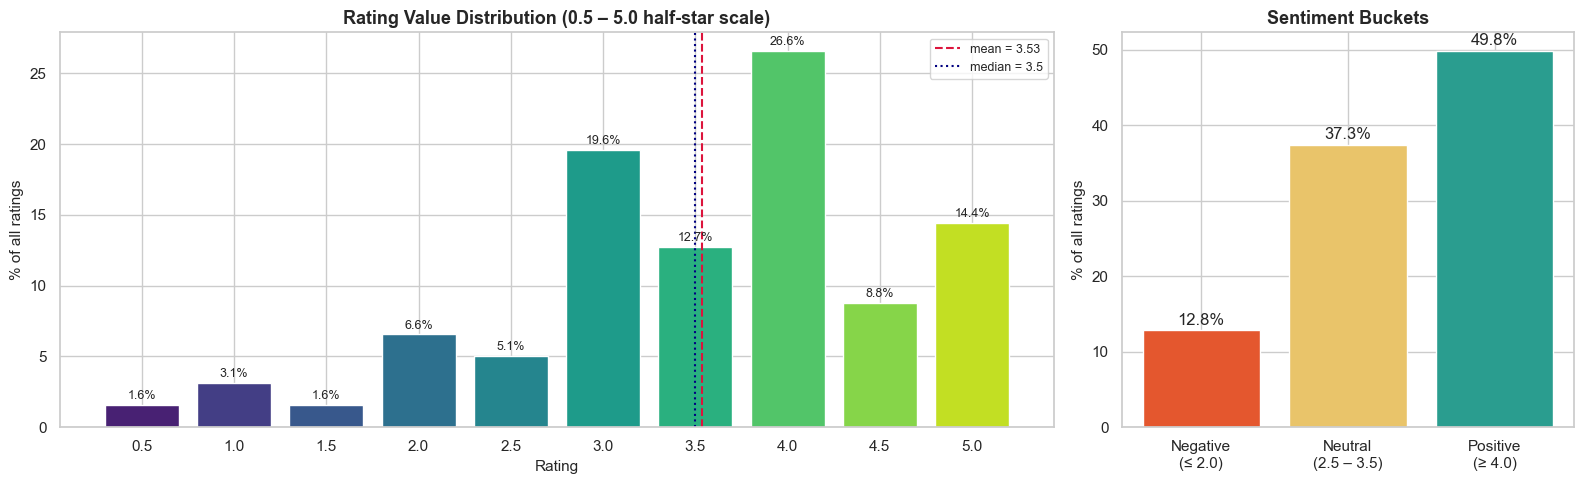

mean=3.534 | median=3.5 | std=1.061 | skew=-0.704
half-star ratings (x.5): 29.7% | positive (>= 4.0): 49.8%


In [37]:
vc = ratings["rating"].value_counts().sort_index()
share = vc / vc.sum() * 100
bucket = pd.cut(ratings["rating"], [0, 2.0, 3.5, 5.0],
                labels=["Negative\n(≤ 2.0)", "Neutral\n(2.5 – 3.5)", "Positive\n(≥ 4.0)"])
bshare = bucket.value_counts(normalize=True).sort_index() * 100
mean_r, med_r, std_r = float(ratings.rating.mean()), float(ratings.rating.median()), float(ratings.rating.std())
half_share = float((ratings.rating % 1 != 0).mean() * 100)
pos_share = float((ratings.rating >= POSITIVE_THRESHOLD).mean() * 100)

fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
bars = ax[0].bar(vc.index, share.values, width=0.4, color=sns.color_palette("viridis", len(vc)))
ax[0].bar_label(bars, fmt="%.1f%%", padding=2, fontsize=9)
ax[0].axvline(mean_r, ls="--", c="crimson", label=f"mean = {mean_r:.2f}")
ax[0].axvline(med_r, ls=":", c="navy", label=f"median = {med_r:.1f}")
ax[0].set_xticks(vc.index); ax[0].set_xlabel("Rating"); ax[0].set_ylabel("% of all ratings")
ax[0].set_title("Rating Value Distribution (0.5 – 5.0 half-star scale)"); ax[0].legend()

b2 = ax[1].bar(bshare.index, bshare.values, color=["#e4572e", "#e9c46a", "#2a9d8f"])
ax[1].bar_label(b2, fmt="%.1f%%", padding=2)
ax[1].set_ylabel("% of all ratings"); ax[1].set_title("Sentiment Buckets")
plt.tight_layout(); plt.show()

print(f"mean={mean_r:.3f} | median={med_r:.1f} | std={std_r:.3f} | skew={ratings.rating.skew():.3f}")
print(f"half-star ratings (x.5): {half_share:.1f}% | positive (>= {POSITIVE_THRESHOLD}): {pos_share:.1f}%")
KPI.update(mean_rating=round(mean_r, 3), positive_share_pct=round(pos_share, 1))

### 📌 Observation
- The histogram is **left-skewed (skew = −0.70)**: mean **3.53**, median **3.5**, std **1.06**. The mode is **4.0 with 26.6%** of all ratings, followed by 3.0 (19.6%), 5.0 (14.4%) and 3.5 (12.7%).
- Whole-star values dominate: 1.0 / 2.0 / 3.0 / 4.0 / 5.0 hold ≈ 70% of the mass while half-stars are **29.7%** of ratings; 4.5 (8.8%) is clearly rarer than 5.0 (14.4%).
- Sentiment buckets: **49.8% positive (≥ 4.0), 37.3% neutral (2.5–3.5), only 12.8% negative (≤ 2.0)** — negative feedback is a small minority.

### 💡 Pipeline / Engineering Decision
- Implicit-feedback label is fixed as **`liked = rating ≥ 4.0`** — it gives an almost perfectly balanced positive class (49.8%) for ranking models (ALS / BPR / two-tower).
- Because the mean is 3.53 and the std 1.06, a model that predicts the global mean already has RMSE ≈ 1.06 (confirmed in Step 31); every regression model must be compared with a bias-aware baseline, not with 0.
- Ranking quality is judged with NDCG@K / Recall@K on the positive class, not accuracy.

---
## 🔹 Step 6 — User Activity Distribution — Who Generates the Data?

### ❓ Why
Collaborative filtering learns from user histories. The distribution of ratings-per-user shows how much signal each user provides and whether a small group of "power users" dominates the training data.

### 💼 Business Insight
If 1% of users produce a large share of interactions, offline metrics get dominated by their taste and casual users (the majority of real traffic) are under-served. This is the classic gap between average-user quality and platform-wide quality.

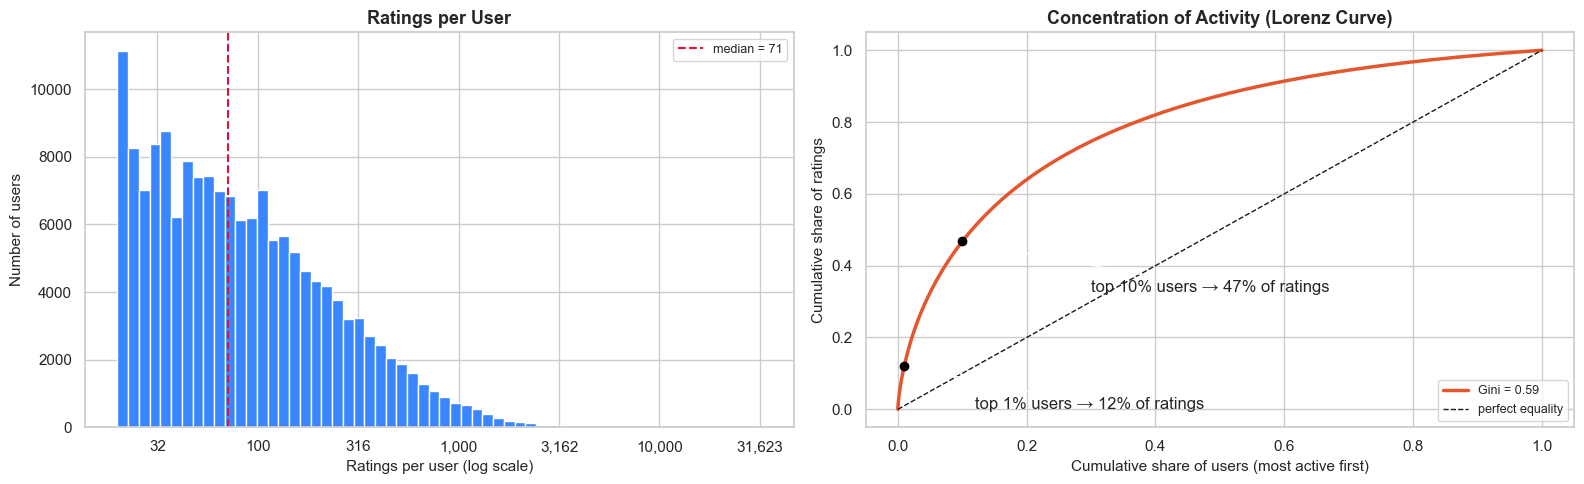

count   162,541.0000
mean        153.8000
std         268.0000
min          20.0000
25%          36.0000
50%          71.0000
75%         162.0000
90%         353.0000
99%       1,228.0000
max      32,202.0000

Top 1% of users = 12.1% of ratings | top 10% = 46.8% | Gini = 0.589


In [38]:
user = ratings.groupby("userId")["rating"].agg(n_ratings="size", mean_rating="mean", std_rating="std")
n_u = user["n_ratings"].values

pcts = user["n_ratings"].describe(percentiles=[.25, .5, .75, .9, .99])
lx, ly = lorenz(n_u)
top1  = float(np.sort(n_u)[::-1][: max(1, int(0.01 * len(n_u)))].sum() / n_u.sum() * 100)
top10 = float(np.sort(n_u)[::-1][: max(1, int(0.10 * len(n_u)))].sum() / n_u.sum() * 100)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].hist(np.log10(n_u), bins=60, color="#3a86ff", edgecolor="white")
ax[0].axvline(np.log10(np.median(n_u)), c="crimson", ls="--", label=f"median = {np.median(n_u):.0f}")
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{10**v:,.0f}"))
ax[0].set_xlabel("Ratings per user (log scale)"); ax[0].set_ylabel("Number of users")
ax[0].set_title("Ratings per User"); ax[0].legend()

ax[1].plot(lorenz(n_u)[1], lorenz(n_u)[0], c="#e4572e", lw=2.5, label=f"Gini = {gini(n_u):.2f}")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfect equality")
ax[1].scatter([0.01, 0.10], [top1 / 100, top10 / 100], c="black", zorder=5)
ax[1].annotate(f"top 1% users → {top1:.0f}% of ratings", (0.01, top1 / 100), (0.12, top1 / 100 - 0.12), arrowprops=dict(arrowstyle="->"))
ax[1].annotate(f"top 10% users → {top10:.0f}% of ratings", (0.10, top10 / 100), (0.30, top10 / 100 - 0.14), arrowprops=dict(arrowstyle="->"))
ax[1].set_xlabel("Cumulative share of users (most active first)"); ax[1].set_ylabel("Cumulative share of ratings")
ax[1].set_title("Concentration of Activity (Lorenz Curve)"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(pcts.round(1).to_string())
print(f"\nTop 1% of users = {top1:.1f}% of ratings | top 10% = {top10:.1f}% | Gini = {gini(n_u):.3f}")
KPI.update(user_median_ratings=float(np.median(n_u)), top1pct_users_share=round(top1, 1), user_gini=round(gini(n_u), 3))

### 📌 Observation
- The histogram (log x-axis) is right-skewed with its tallest bar at the minimum: the **minimum is exactly 20 ratings** (MovieLens kept only users with ≥ 20), the **median user has 71**, the mean is 154, the 90th percentile 353, the 99th percentile **1,228** and the heaviest user has **32,202** ratings.
- The concentration curve bows well above the diagonal: **top 1% of users → 12.1% of ratings, top 10% of users → 46.8%**, **Gini = 0.589** — activity is concentrated but much less extremely than item popularity (Step 7).
- Because of the 20-rating filter, no truly "empty" user exists in this file; the lightest quarter of users has ≤ 36 ratings.

### 💡 Pipeline / Engineering Decision
- Add a **per-user cap in the training sampler** (e.g. at most ≈ 1,000 interactions per user per epoch — about the 99th percentile) so the ≈ 16K most active users (top 10% = 47% of ratings) do not dominate gradient updates.
- Report offline metrics **per activity segment** (≤ 36 / 37–162 / 163–353 / > 353 ratings, i.e. the quartile/percentile cut-points above) next to the global average.
- Evaluation must hold out *recent interactions of known users* as well as new users — Step 16 shows why a plain global time split mostly tests new users.

---
## 🔹 Step 7 — Item Popularity & the Long Tail

### ❓ Why
Item popularity shows how interactions are spread over the catalogue. In almost every media catalogue a few blockbusters collect most of the feedback while the majority of titles receive almost none (Zipf / power-law behaviour).

### 💼 Business Insight
This is the central business tension of recommenders: **popular items are safe but boring; tail items give discovery value and catalogue ROI but have no data.** OTT platforms pay for the whole catalogue (licensing) — if the recommender ignores the tail, most of that spend never gets watched.

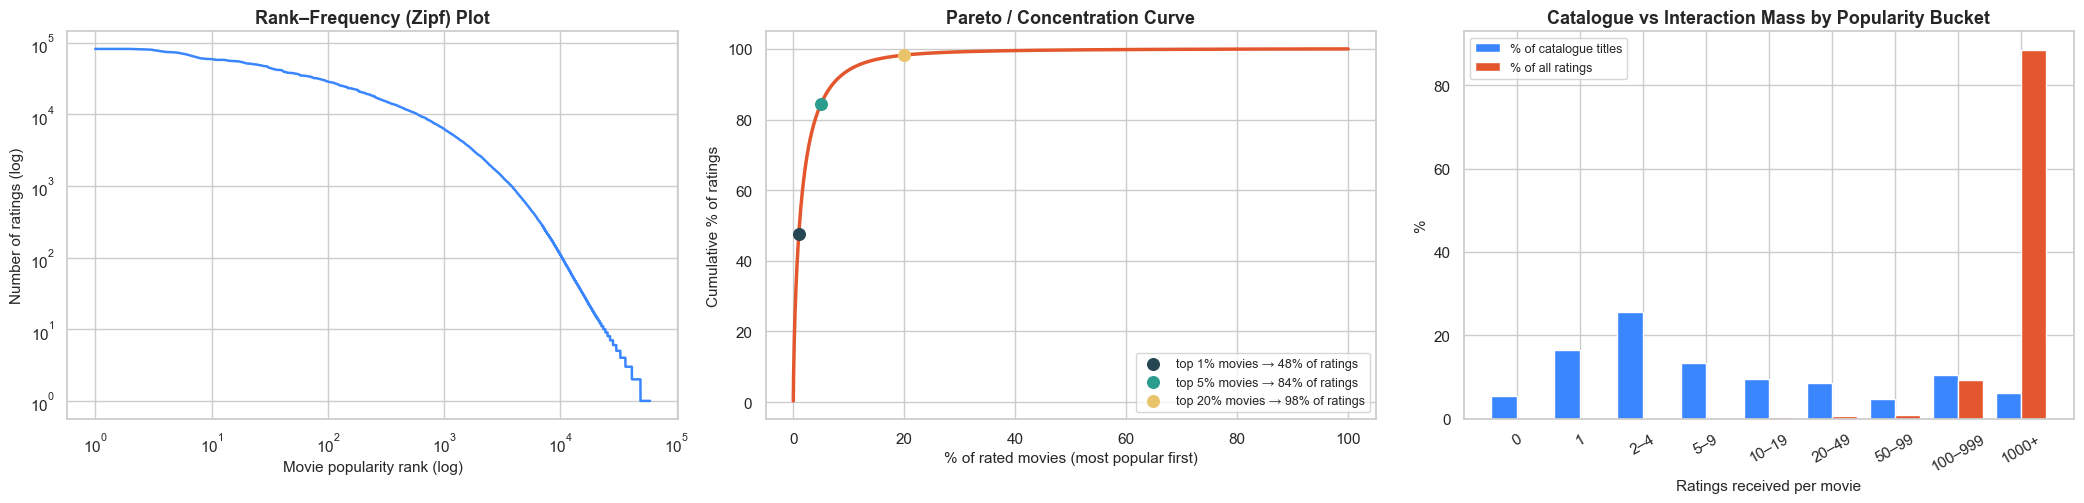

Rated movies: 59,047 of 62,423 catalogue (94.6%) | never rated: 3,376
Movies with < 5 ratings: 47.6% of catalogue | with >= 1000 ratings: 3,794
Gini (item popularity) = 0.942 | top 1% = 47.6% | top 5% = 84.5% | top 20% = 98.3%

Most-rated movies:


,n,mean,std,title
movieId,,,,
356,81491,4.0480,0.9388,Forrest Gump (1994)
318,81482,4.4136,0.7604,"Shawshank Redemption, The (1994)"
296,79672,4.1889,0.9588,Pulp Fiction (1994)
593,74127,4.1513,0.8619,"Silence of the Lambs, The (1991)"
2571,72674,4.1541,0.9129,"Matrix, The (1999)"
260,68717,4.1202,0.9818,Star Wars: Episode IV - A New Hope (1977)
480,64144,3.6792,0.9398,Jurassic Park (1993)
527,60411,4.2476,0.8748,Schindler's List (1993)


In [39]:
item = ratings.groupby("movieId")["rating"].agg(n="size", mean="mean", std="std")
cat_n = item["n"].reindex(movies["movieId"]).fillna(0).astype("int64")          # aligned to `movies` order (0 = never rated)
cov = movies[["movieId"]].copy()                                                 # master coverage table (grows in later steps)
cov["n_ratings"] = cat_n.values
cov["has_ratings"] = cov["n_ratings"] > 0

n_i = np.sort(item["n"].values)[::-1]
ix, iy = np.arange(1, len(n_i) + 1), n_i
cum_share = np.cumsum(n_i) / n_i.sum() * 100
share_top = {p: float(cum_share[int(len(n_i) * p) - 1]) for p in (0.01, 0.05, 0.20)}

bins = [-1, 0, 1, 4, 9, 19, 49, 99, 999, np.inf]
labels = ["0", "1", "2–4", "5–9", "10–19", "20–49", "50–99", "100–999", "1000+"]
bk = pd.cut(cat_n, bins=bins, labels=labels)
bk_movies = bk.value_counts(normalize=True).reindex(labels) * 100
bk_mass = (cat_n.groupby(bk).sum() / cat_n.sum() * 100).reindex(labels)

fig, ax = plt.subplots(1, 3, figsize=(21, 5.2))
ax[0].loglog(ix, iy, c="#3a86ff", lw=1.8)
ax[0].set_xlabel("Movie popularity rank (log)"); ax[0].set_ylabel("Number of ratings (log)")
ax[0].set_title("Rank–Frequency (Zipf) Plot")

ax[1].plot(np.arange(1, len(n_i) + 1) / len(n_i) * 100, cum_share, c="#e4572e", lw=2.5)
for p, c in zip((0.01, 0.05, 0.20), ("#264653", "#2a9d8f", "#e9c46a")):
    ax[1].scatter(p * 100, share_top[p], s=70, c=c, zorder=5, label=f"top {p:.0%} movies → {share_top[p]:.0f}% of ratings")
ax[1].set_xlabel("% of rated movies (most popular first)"); ax[1].set_ylabel("Cumulative % of ratings")
ax[1].set_title("Pareto / Concentration Curve"); ax[1].legend(loc="lower right")

w = 0.4; xs = np.arange(len(labels))
ax[2].bar(xs - w / 2, bk_movies.values, w, label="% of catalogue titles", color="#3a86ff")
ax[2].bar(xs + w / 2, bk_mass.values, w, label="% of all ratings", color="#e4572e")
ax[2].set_xticks(xs); ax[2].set_xticklabels(labels, rotation=30)
ax[2].set_xlabel("Ratings received per movie"); ax[2].set_ylabel("%"); ax[2].set_title("Catalogue vs Interaction Mass by Popularity Bucket"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"Rated movies: {len(item):,} of {len(movies):,} catalogue ({len(item)/len(movies):.1%}) | never rated: {(cat_n==0).sum():,}")
print(f"Movies with < 5 ratings: {(cat_n<5).mean():.1%} of catalogue | with >= 1000 ratings: {(cat_n>=1000).sum():,}")
print(f"Gini (item popularity) = {gini(item['n']):.3f} | " + " | ".join(f"top {int(p*100)}% = {v:.1f}%" for p, v in share_top.items()))
print("\nMost-rated movies:"); display(item.nlargest(8, "n").join(movies.set_index("movieId")["title"]))
KPI.update(item_gini=round(gini(item["n"]), 3), pct_catalog_lt5=round(float((cat_n < 5).mean() * 100), 1),
           top1pct_movies_share=round(share_top[0.01], 1))

### 📌 Observation
- **59,047 of 62,423** catalogue movies (94.6%) have at least one rating; **3,376 were never rated**. **47.6% of the catalogue has fewer than 5 ratings.**
- Concentration is extreme: **item Gini = 0.942**; **top 1% of movies → 47.6% of ratings, top 5% → 84.5%, top 20% → 98.3%** (Pareto panel). The bucket chart shows the **3,794 titles with ≥ 1,000 ratings (6.1% of the catalogue) carry ≈ 88% of all ratings**, while the 1–4-rating buckets hold ≈ 41% of titles but almost no ratings.
- The rank–frequency curve is flat for the first ~10 movies, then bends smoothly downward — a heavy-tailed curve that is *not* a straight power-law line. The most-rated titles are Forrest Gump (81,491), Shawshank Redemption (81,482) and Pulp Fiction (79,672).

### 💡 Pipeline / Engineering Decision
- A pure collaborative model would effectively learn only the ~6% head of the catalogue; the other **~94% of titles (< 1,000 ratings) must be reachable through the content branch** — this is the quantitative justification for the hybrid CineMatch-Pro design.
- Add **popularity debiasing** in training (log-popularity-corrected negative sampling or inverse-propensity weights) because the top 20% of movies hold 98.3% of the positives.
- Evaluate with **catalogue coverage, item-Gini of the recommendation lists and novelty** together with NDCG — otherwise a model that recommends the same ~500 blockbusters would look excellent.

---
## 🔹 Step 8 — Sparsity & Minimum-Interaction Filtering (k-core Trade-off)

### ❓ Why
The user×item matrix density determines which algorithm families work and how much to filter. Filtering rare items improves model stability but also removes catalogue titles — this step quantifies the trade-off before choosing a threshold.

### 💼 Business Insight
Every title removed from the training set becomes a title the model can never recommend. Business teams need to know the exact "coverage cost" of a technical stability rule such as "keep movies with ≥ 10 ratings".

,min_ratings_per_movie,movies_kept_%,ratings_kept_%,movies_kept
0,1,100.0000,100.0000,59047
1,2,82.5597,99.9588,48749
2,5,55.4135,99.7831,32720
3,10,41.2045,99.5620,24330
4,20,31.2124,99.2416,18430
5,50,22.3144,98.5793,13176
6,100,17.4878,97.7731,10326
7,200,13.5214,96.4358,7984
8,500,9.1215,93.0835,5386


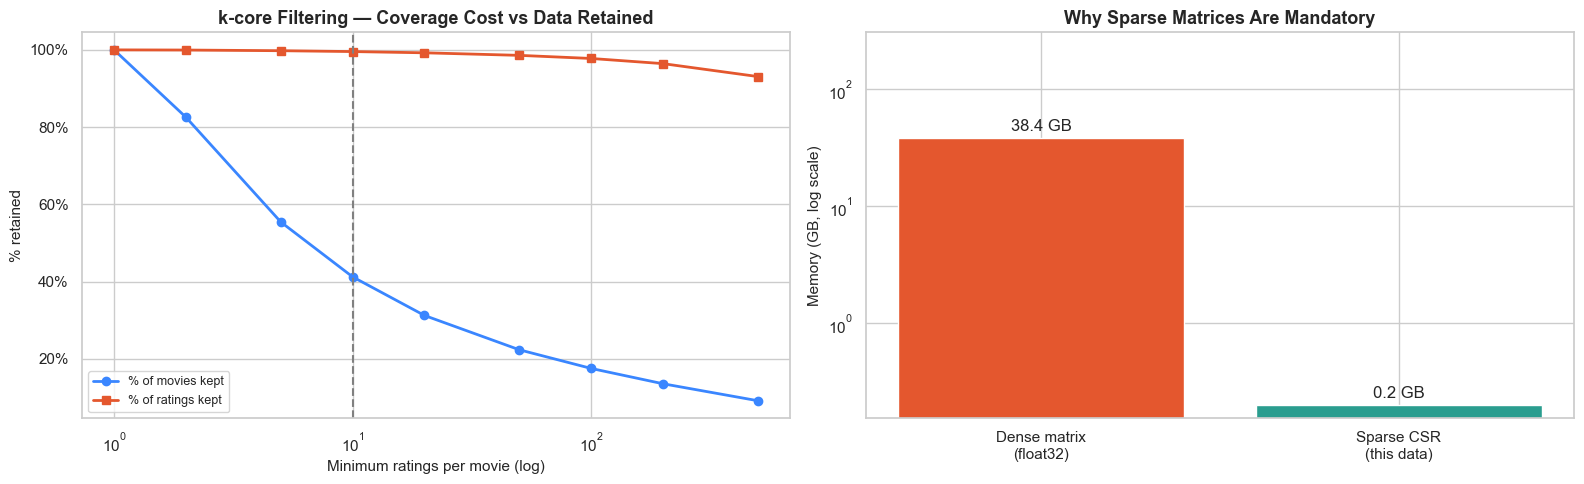

users=162,541 | items=59,047 | interactions=25,000,095
density=0.2605% | sparsity=99.7395% | dense=38.4 GB vs CSR=0.20 GB


In [40]:
n_users, n_items, nnz = user.shape[0], item.shape[0], len(ratings)
density = nnz / (n_users * n_items)
dense_gb  = n_users * n_items * 4 / 1e9
sparse_gb = nnz * (4 + 4) / 1e9 + (n_users + 1) * 4 / 1e9      # CSR: data float32 + indices int32 + indptr

ks = [1, 2, 5, 10, 20, 50, 100, 200, 500]
rows = []
for k in ks:
    keep = item["n"] >= k
    rows.append({"min_ratings_per_movie": k, "movies_kept_%": keep.mean() * 100,
                 "ratings_kept_%": item.loc[keep, "n"].sum() / nnz * 100, "movies_kept": int(keep.sum())})
kc = pd.DataFrame(rows)
display(kc)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(kc.min_ratings_per_movie, kc["movies_kept_%"], "o-", c="#3a86ff", lw=2, label="% of movies kept")
ax[0].plot(kc.min_ratings_per_movie, kc["ratings_kept_%"], "s-", c="#e4572e", lw=2, label="% of ratings kept")
ax[0].set_xscale("log"); ax[0].set_xlabel("Minimum ratings per movie (log)"); ax[0].set_ylabel("% retained")
ax[0].axvline(10, ls="--", c="grey"); ax[0].set_title("k-core Filtering — Coverage Cost vs Data Retained"); ax[0].legend()
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())

mem = pd.Series({"Dense matrix\n(float32)": dense_gb, "Sparse CSR\n(this data)": sparse_gb})
b = ax[1].bar(mem.index, mem.values, color=["#e4572e", "#2a9d8f"]); ax[1].set_yscale("log")
ax[1].bar_label(b, labels=[f"{v:,.1f} GB" for v in mem.values], padding=3)
ax[1].set_ylabel("Memory (GB, log scale)"); ax[1].set_title("Why Sparse Matrices Are Mandatory")
ax[1].set_ylim(top=mem.max() * 8)
plt.tight_layout(); plt.show()

print(f"users={n_users:,} | items={n_items:,} | interactions={nnz:,}")
print(f"density={density:.4%} | sparsity={1-density:.4%} | dense={dense_gb:,.1f} GB vs CSR={sparse_gb:,.2f} GB")
KPI.update(sparsity_pct=round((1 - density) * 100, 3), dense_matrix_GB=round(dense_gb, 1), csr_matrix_GB=round(sparse_gb, 2))

### 📌 Observation
- Interaction matrix: 162,541 users × 59,047 rated movies, **25,000,095 interactions → density 0.2605%, sparsity 99.74%**.
- Dense float32 storage would need **38.4 GB**; CSR needs only **0.20 GB** (≈ 190× smaller) — the right-hand log-scale bars make this difference obvious.
- The k-core table/plot is highly asymmetric: a minimum of **10 ratings keeps only 41.2% of the rated movies (24,330) but 99.56% of the ratings**; a minimum of 5 keeps 55.4% of movies / 99.78% of ratings; 20 keeps 31.2% / 99.24%; even 100 keeps 97.8% of ratings with only 17.5% of the movies.

### 💡 Pipeline / Engineering Decision
- Interactions are stored as **`scipy.sparse.csr_matrix`** (and sparse tensors in PyTorch); a dense user×item matrix is never created.
- The collaborative-filtering branch uses **`MIN_ITEM_RATINGS = 10`** (loses only 0.44% of ratings); the 34,717 rated movies below that threshold are *not* dropped from the system — they are routed to the content branch.
- The threshold stays configurable; the experiment tracker logs model quality at 5 / 10 / 20 so the choice is evidence-based.

---
## 🔹 Step 9 — Temporal Patterns — Rating Volume, Mood Drift & Half-Star Adoption

### ❓ Why
Timestamps reveal whether the data-generating process is stable over time. If volume, average rating or rating granularity changes across years, a random train/test split leaks future behaviour into training and overstates quality.

### 💼 Business Insight
Platforms evolve: UI changes, new rating scales, seasonal releases and catalogue refreshes all shift user behaviour. A model evaluated on a random split looks great in the lab and then degrades after launch because the future is not like the past.

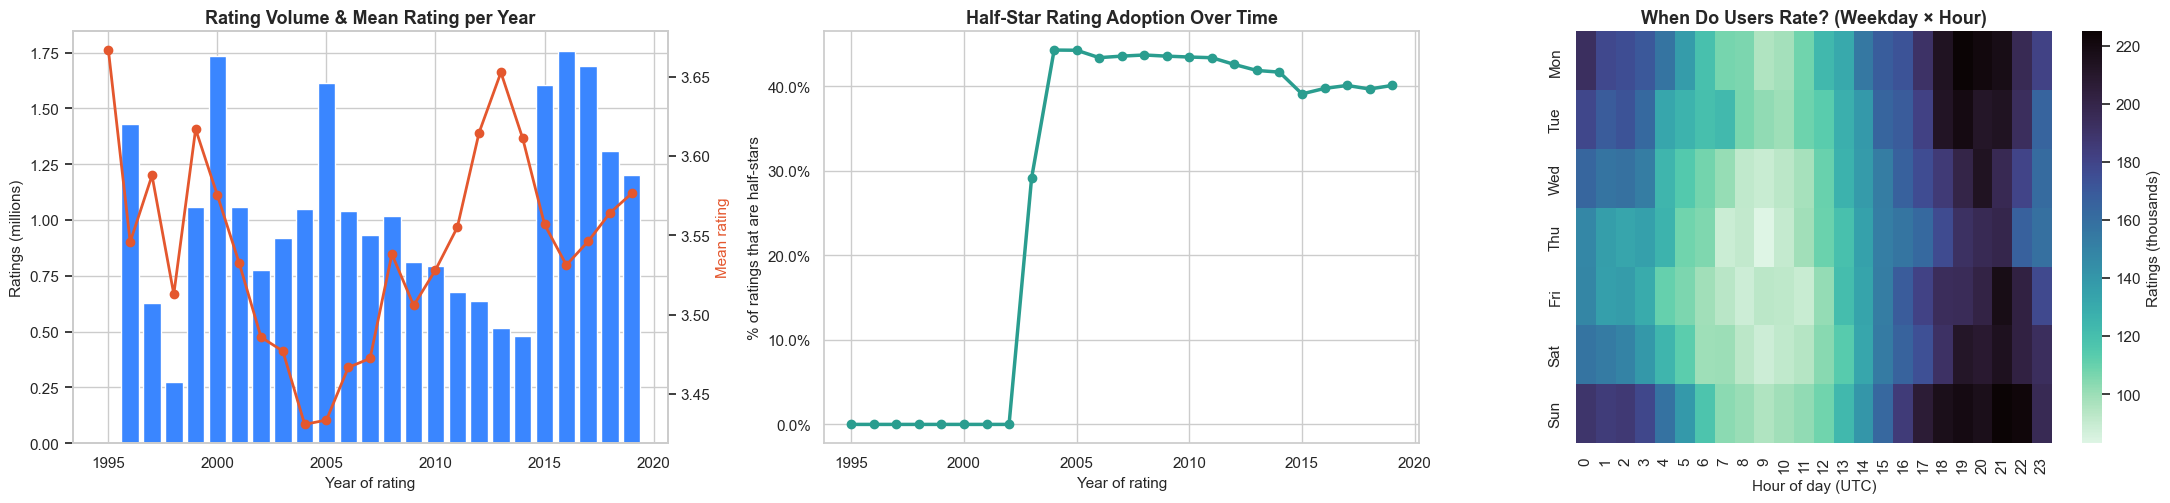

Time span: 1995-01-09 → 2019-11-21 (24.9 years)
Busiest year: 2016 (1,757,440 ratings) | mean-rating range across years: 3.43 – 3.67


18609

In [41]:
dt = pd.to_datetime(ratings["timestamp"], unit="s")
yr, dow, hr = dt.dt.year.values, dt.dt.dayofweek.values, dt.dt.hour.values
date_min, date_max = dt.min(), dt.max(); del dt

ydf = pd.DataFrame({"year": yr, "rating": ratings["rating"].values, "half": (ratings["rating"].values % 1 != 0)})
yearly = ydf.groupby("year").agg(n=("rating", "size"), mean=("rating", "mean"), half_share=("half", "mean"))
heat = np.bincount(dow * 24 + hr, minlength=7 * 24).reshape(7, 24)

fig, ax = plt.subplots(1, 3, figsize=(22, 5.2))
ax[0].bar(yearly.index, yearly["n"] / 1e6, color="#3a86ff")
ax[0].set_ylabel("Ratings (millions)"); ax[0].set_xlabel("Year of rating"); ax[0].set_title("Rating Volume & Mean Rating per Year")
ax0b = ax[0].twinx(); ax0b.plot(yearly.index, yearly["mean"], "o-", c="#e4572e", lw=2); ax0b.set_ylabel("Mean rating", color="#e4572e")
ax0b.grid(False)

ax[1].plot(yearly.index, yearly["half_share"] * 100, "o-", c="#2a9d8f", lw=2.5)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_xlabel("Year of rating")
ax[1].set_ylabel("% of ratings that are half-stars"); ax[1].set_title("Half-Star Rating Adoption Over Time")

sns.heatmap(heat / 1e3, ax=ax[2], cmap="mako_r", yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
            cbar_kws={"label": "Ratings (thousands)"})
ax[2].set_xlabel("Hour of day (UTC)"); ax[2].set_title("When Do Users Rate? (Weekday × Hour)")
plt.tight_layout(); plt.show()

print(f"Time span: {date_min:%Y-%m-%d} → {date_max:%Y-%m-%d} ({(date_max-date_min).days/365.25:.1f} years)")
print(f"Busiest year: {int(yearly['n'].idxmax())} ({yearly['n'].max():,} ratings) | mean-rating range across years: {yearly['mean'].min():.2f} – {yearly['mean'].max():.2f}")
KPI.update(date_start=str(date_min.date()), date_end=str(date_max.date()), mean_rating_year_range=f"{yearly['mean'].min():.2f}-{yearly['mean'].max():.2f}")
del ydf, yr, dow, hr; gc.collect()

### 📌 Observation
- Time span **1995-01-09 → 2019-11-21 (24.9 years)**. Volume is not stationary: sharp peaks around 2000 (≈ 1.7M), 2005 (≈ 1.6M) and **2016 (1,757,440 — the busiest year)**, deep troughs in 1998 (≈ 0.27M) and 2013–2014 (≈ 0.5M).
- The mean rating moves between **3.43 and 3.67**; it is lowest around 2004–2005 and highest in 1995 and around 2013.
- The half-star chart shows a hard structural break: **0% half-star ratings through 2002, ≈ 29% in 2003, ≈ 44% in 2004, then ≈ 40% from 2005 onward** — the rating interface changed in 2003.
- The weekday × hour heatmap has a clear daily rhythm: peak activity **17:00–22:00 UTC (darkest on Sunday and Monday evenings)**, lowest at **07:00–11:00 UTC** on weekdays.

### 💡 Pipeline / Engineering Decision
- The evaluation protocol is **chronological**: train on the past, test on the last 10% of time (cut-off in Step 16), never a random split.
- Add `rating_year`, `movie_age_at_rating`, `hour_of_day`, `day_of_week` as context features and an option for **recency weighting**; ratings before 2003 come from a whole-star-only interface and are a different rating regime.
- Run **PSI-based drift monitoring** on the rating distribution and the half-star share at every retraining, since the yearly mean already varies by ≈ 0.24 stars.

---
## 🔹 Step 10 — Catalogue Age — Release Year & Decade Mix

### ❓ Why
MovieLens stores the release year inside the title string `"Toy Story (1995)"`. Extracting it gives a clean numeric feature and shows how old the catalogue is and which eras attract user attention.

### 💼 Business Insight
Catalogue age affects licensing cost and user appeal. If most interaction mass sits on modern titles but half the catalogue is pre-1980, a "new & trending" shelf and a "classics" shelf need different algorithms and different success metrics.

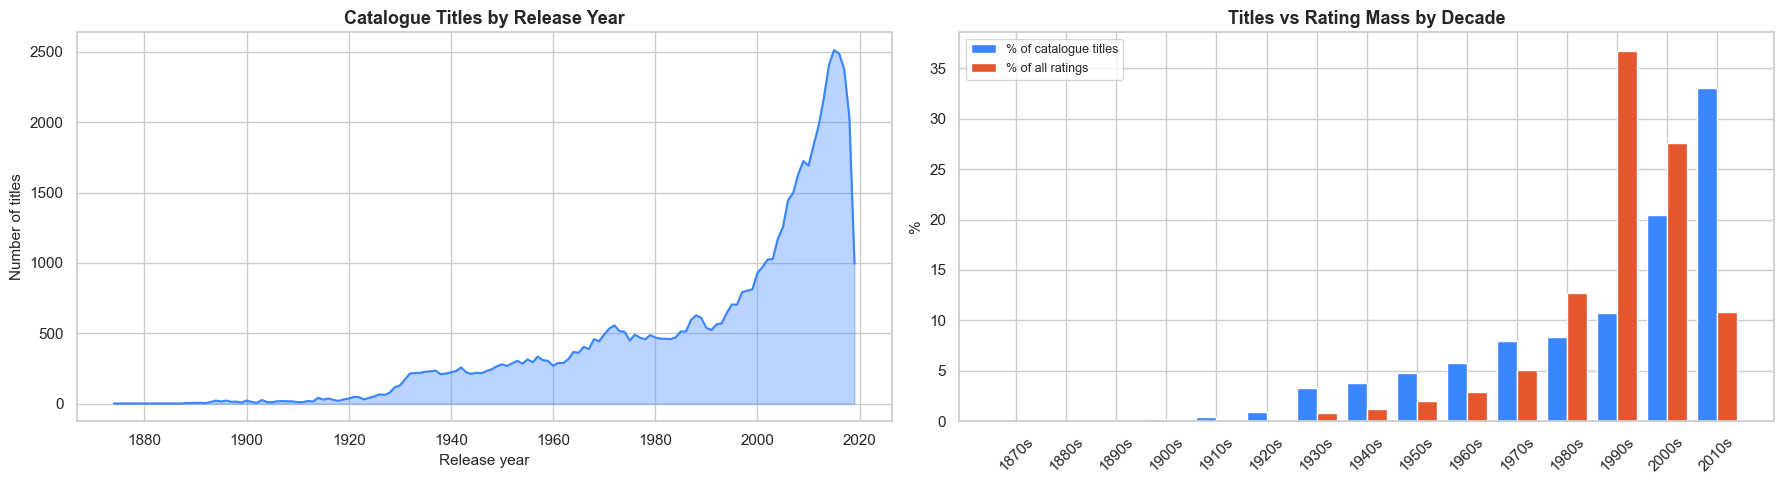

Titles without a valid year: 414 | year range: 1874 – 2019
Median release year (catalogue): 2002 | rating-weighted median year: 1994


In [42]:
movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)\s*$")[0], errors="coerce")
movies["title_clean"] = movies["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True).str.strip()
bad_year = int((movies["year"].isna() | (movies["year"] < 1880) | (movies["year"] > 2026)).sum())
movies["decade"] = (movies["year"] // 10 * 10)

per_year = movies.groupby("year").size()
dec = pd.DataFrame({"titles": movies.groupby("decade").size(),
                    "ratings": pd.Series(cat_n.values, index=movies.index).groupby(movies["decade"]).sum()})
dec_pct = dec / dec.sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].fill_between(per_year.index, per_year.values, color="#3a86ff", alpha=.35); ax[0].plot(per_year.index, per_year.values, c="#3a86ff")
ax[0].set_xlabel("Release year"); ax[0].set_ylabel("Number of titles"); ax[0].set_title("Catalogue Titles by Release Year")
w = 0.4; xs = np.arange(len(dec_pct))
ax[1].bar(xs - w / 2, dec_pct["titles"], w, color="#3a86ff", label="% of catalogue titles")
ax[1].bar(xs + w / 2, dec_pct["ratings"], w, color="#e4572e", label="% of all ratings")
ax[1].set_xticks(xs); ax[1].set_xticklabels([f"{int(d)}s" for d in dec_pct.index], rotation=45)
ax[1].set_ylabel("%"); ax[1].set_title("Titles vs Rating Mass by Decade"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Titles without a valid year: {bad_year:,} | year range: {int(movies.year.min())} – {int(movies.year.max())}")
print(f"Median release year (catalogue): {movies.year.median():.0f} | rating-weighted median year: {np.average(movies.year.fillna(movies.year.median()), weights=cat_n.values+1e-9):.0f}")
KPI.update(catalog_year_range=f"{int(movies.year.min())}-{int(movies.year.max())}")

### 📌 Observation
- The title count per release year rises slowly until ~1980 and then grows steeply to a **peak of ≈ 2,500 titles around 2015**; the drop in 2019 (≈ 1,000) is only the partial last year. Release years span **1874–2019**, **414 titles have no valid year**.
- The median release year of the catalogue is **2002**, but the rating-weighted median is **1994** — users rate older films far more than the catalogue mix suggests.
- Decade chart: the **1990s hold ≈ 37% of all ratings with only ≈ 11% of titles**, the 2000s ≈ 27% (≈ 20% of titles), while the **2010s are ≈ 33% of titles but only ≈ 11% of ratings**. The 1980s (≈ 12.6% of ratings, 8% of titles) are also over-represented; every decade before 1980 gets fewer ratings than its title share.

### 💡 Pipeline / Engineering Decision
- `release_year` and `decade` are extracted with `\((\d{4})\)\s*$` and kept null-safe (414 nulls); `title_clean` (without the year) is used for text/embedding work.
- Add `movie_age_at_rating = rating_year − release_year` as a context feature; it captures nostalgia vs new-release behaviour.
- Because recent (2010s) titles are numerous but sparsely rated, the model is evaluated separately on **recent releases vs classics** and the content branch is the primary path for 2010s titles.

---
## 🔹 Step 11 — Genre Supply vs Demand

### ❓ Why
Genres are the most basic content feature and are available for the whole catalogue. Comparing the share of titles in each genre (supply) with the share of ratings they receive (demand) shows where the catalogue and the audience disagree.

### 💼 Business Insight
Content-acquisition teams spend budget by genre. If a genre is 8% of the catalogue but 15% of viewing demand (or the reverse), that is a direct input to licensing decisions and to the "genre rows" on the home screen.

,titles,supply_%,demand_%,demand_minus_supply
Drama,25606,41.0201,43.8512,2.8310
Comedy,16870,27.0253,35.7048,8.6795
Thriller,8654,13.8635,27.0530,13.1895
Romance,7719,12.3656,17.9891,5.6235
Action,7348,11.7713,29.7876,18.0163
Horror,5989,9.5942,7.5687,-2.0255
Documentary,5605,8.9791,1.2898,-7.6893
Crime,5319,8.5209,16.7610,8.2401
(no genres listed),5062,8.1092,0.1065,-8.0027
Adventure,4145,6.6402,23.3296,16.6894


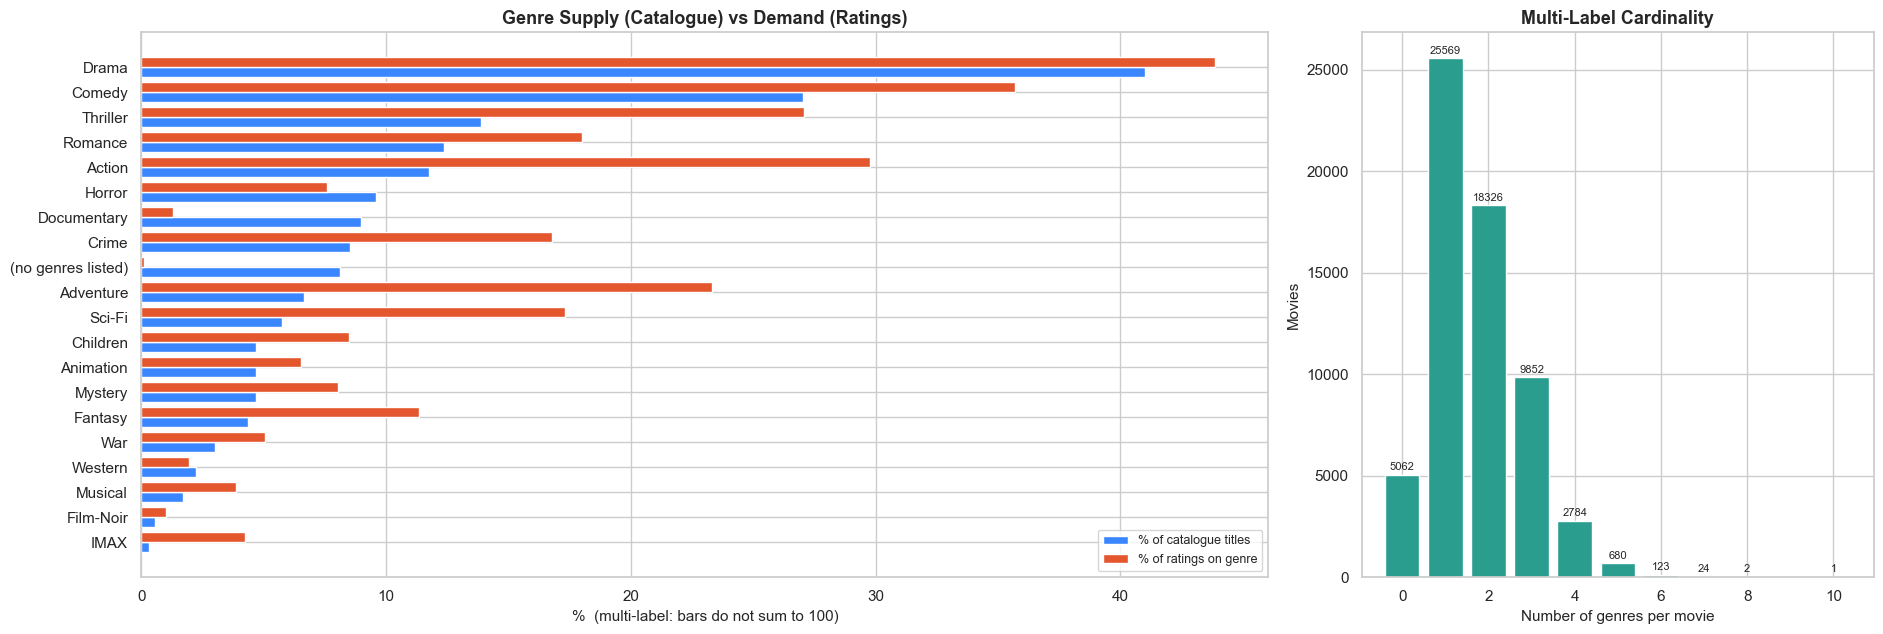

Genres: 20 | movies with '(no genres listed)': 5,062 | avg genres/movie: 1.72


In [43]:
G = movies["genres"].str.get_dummies("|")                           # multi-hot genre matrix (movies x genres)
G.index = movies["movieId"]
n_genres = G.drop(columns=["(no genres listed)"], errors="ignore").sum(axis=1)

supply = G.mean() * 100                                             # % of catalogue titles carrying the genre
demand = pd.Series((G.values * cat_n.values[:, None]).sum(0) / cat_n.sum() * 100, index=G.columns)   # % of ratings touching genre
gtab = pd.DataFrame({"titles": G.sum(), "supply_%": supply, "demand_%": demand}).sort_values("supply_%", ascending=False)
gtab["demand_minus_supply"] = gtab["demand_%"] - gtab["supply_%"]
display(gtab)

fig, ax = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})
order = gtab.index[::-1]; y = np.arange(len(order)); h = 0.4
ax[0].barh(y - h / 2, gtab.loc[order, "supply_%"], h, color="#3a86ff", label="% of catalogue titles")
ax[0].barh(y + h / 2, gtab.loc[order, "demand_%"], h, color="#e4572e", label="% of ratings on genre")
ax[0].set_yticks(y); ax[0].set_yticklabels(order); ax[0].set_xlabel("%  (multi-label: bars do not sum to 100)")
ax[0].set_title("Genre Supply (Catalogue) vs Demand (Ratings)"); ax[0].legend(loc="lower right")

cnt = n_genres.value_counts().sort_index()
b = ax[1].bar(cnt.index.astype(int), cnt.values, color="#2a9d8f"); ax[1].bar_label(b, fmt="%d", padding=2, fontsize=8)
ax[1].set_xlabel("Number of genres per movie"); ax[1].set_ylabel("Movies"); ax[1].set_title("Multi-Label Cardinality")
plt.tight_layout(); plt.show()

print(f"Genres: {G.shape[1]} | movies with '(no genres listed)': {int(G.get('(no genres listed)', pd.Series(dtype=int)).sum()):,} | avg genres/movie: {n_genres.mean():.2f}")
KPI.update(n_genres=int(G.shape[1]), avg_genres_per_movie=round(float(n_genres.mean()), 2))

### 📌 Observation
- Drama is the largest genre (**25,606 titles, 41.0% of the catalogue, 43.9% of ratings**), then Comedy (27.0% / 35.7%). The `(no genres listed)` group covers 5,062 titles (8.1%) but only **0.11% of ratings**.
- Demand clearly exceeds supply for mainstream genres: **Action 11.8% of titles vs 29.8% of ratings (+18.0 pts), Adventure 6.6% vs 23.3% (+16.7), Thriller 13.9% vs 27.1% (+13.2), Sci-Fi 5.8% vs 17.3% (+11.5), Fantasy 4.4% vs 11.3%**, IMAX 0.3% vs 4.3%.
- Supply exceeds demand for **Documentary (9.0% of titles vs 1.3% of ratings, −7.7 pts)** and Horror (9.6% vs 7.6%).
- Cardinality chart: **1 genre — 25,569 movies, 2 genres — 18,326, 3 genres — 9,852**, 4 — 2,784, up to a single movie with 10 genres; 5,062 movies have none. Average = 1.72 genres per movie.

### 💡 Pipeline / Engineering Decision
- Genres become a **19-dimensional multi-hot vector**; `(no genres listed)` is dropped as a column and replaced by an `is_unlabeled` flag (8.1% of titles).
- The demand-supply gap table feeds the **calibration / diversity re-ranker**: Action, Adventure, Thriller and Sci-Fi are heavily over-demanded, Documentary is almost never rated — recommendations must not just follow raw demand.
- Genre-based features alone cannot separate titles (most movies have 1–2 labels), so genres are combined with the genome and metadata vectors, not used on their own.

---
## 🔹 Step 12 — Genre Co-occurrence — Conditional Probability & Lift

### ❓ Why
A heatmap of P(genre B | genre A) shows which genres travel together. Lift (observed co-occurrence ÷ expected under independence) separates *genuinely linked* pairs from pairs that co-occur just because both genres are large.

### 💼 Business Insight
Genre-bundle knowledge drives shelf design ("Action & Adventure", "Romantic Comedy") and gives a cheap similarity signal for cold-start items that have genres but no ratings.

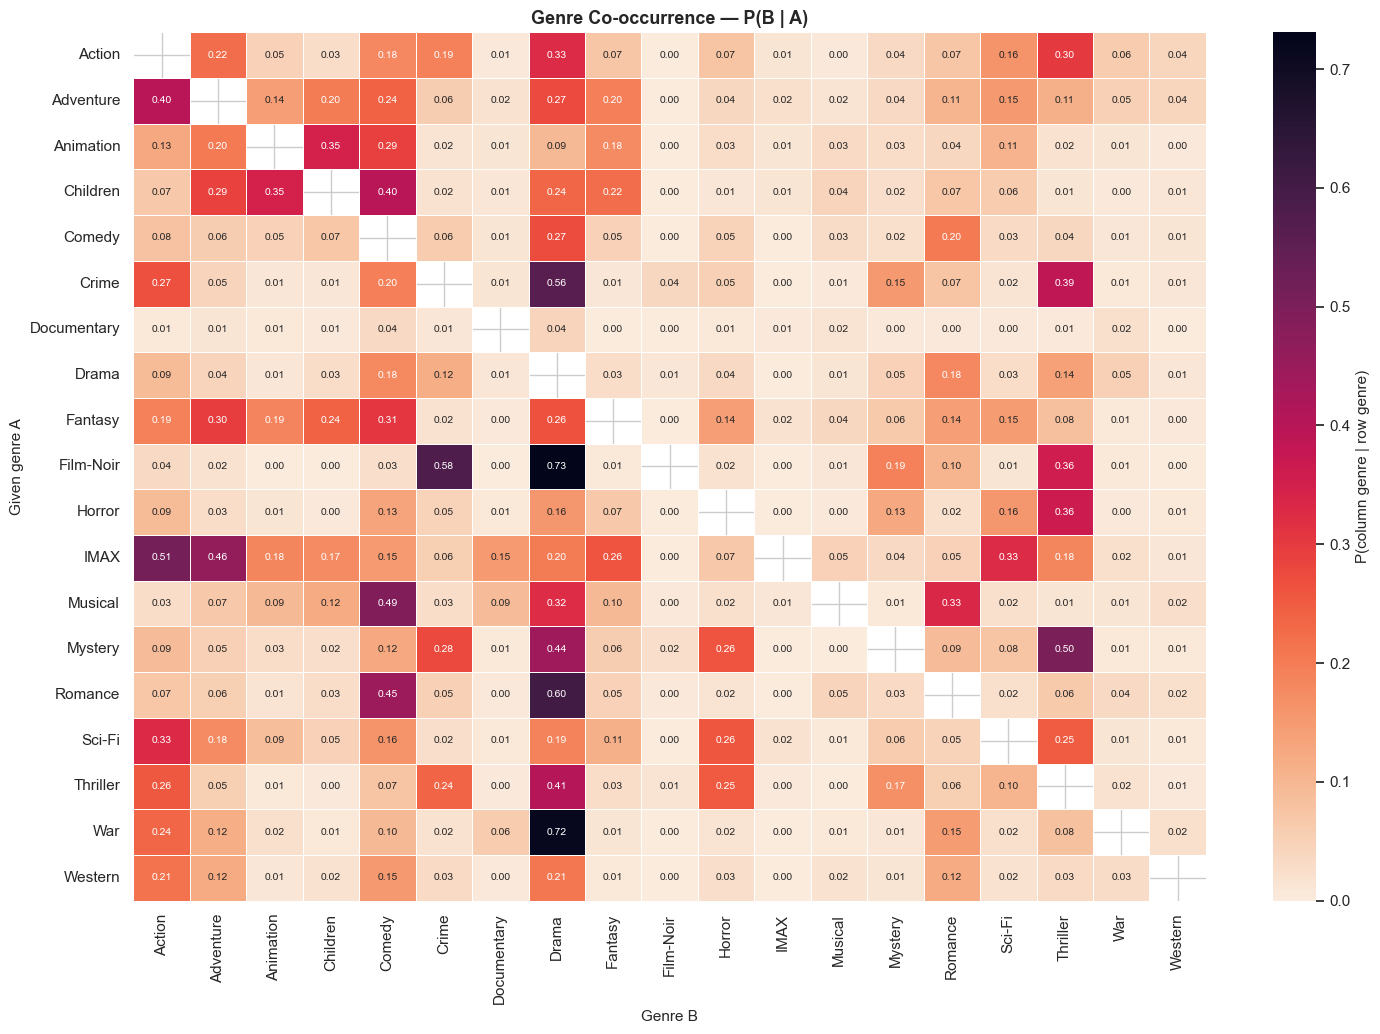

Strongest associations (lift, min 100 co-occurrences):


,genre_A,genre_B,lift,co_count
0,Animation,Children,7.3703,1015
1,Crime,Film-Noir,6.8154,205
2,Children,Fantasy,5.1166,657
3,Adventure,Fantasy,4.4612,809
4,Action,IMAX,4.3565,100
5,Adventure,Children,4.3050,839
6,Animation,Fantasy,4.0033,513
7,Mystery,Thriller,3.6152,1466
8,Action,Adventure,3.3858,1652
9,Crime,Mystery,3.2780,817


Most 'exclusive' pairs (lowest lift):


,genre_A,genre_B,lift,co_count
0,Comedy,Thriller,0.2766,647
1,Animation,Drama,0.2314,278
2,Horror,Romance,0.1742,129
3,Comedy,Documentary,0.1320,200
4,Documentary,Drama,0.1066,245


In [44]:
Gr = G.drop(columns=["(no genres listed)"], errors="ignore")
co = Gr.T.values @ Gr.values                                          # co-occurrence counts
cnt = np.diag(co).astype(float)
cond = pd.DataFrame(co / cnt[:, None], index=Gr.columns, columns=Gr.columns)    # row = given A, column = P(B | A)
N = len(Gr)
lift = pd.DataFrame(co * N / np.outer(cnt, cnt), index=Gr.columns, columns=Gr.columns)

mask = np.eye(len(cond), dtype=bool)
plt.figure(figsize=(15, 10.5))
sns.heatmap(cond.mask(mask), annot=True, fmt=".2f", annot_kws={"size": 7.5}, cmap="rocket_r", linewidths=.4,
            cbar_kws={"label": "P(column genre | row genre)"})
plt.title("Genre Co-occurrence — P(B | A)"); plt.xlabel("Genre B"); plt.ylabel("Given genre A")
plt.tight_layout(); plt.show()

pairs = [(a, b, lift.loc[a, b], co[i, j]) for i, a in enumerate(Gr.columns) for j, b in enumerate(Gr.columns) if i < j and co[i, j] >= 100]
top_pairs = pd.DataFrame(pairs, columns=["genre_A", "genre_B", "lift", "co_count"]).sort_values("lift", ascending=False)
print("Strongest associations (lift, min 100 co-occurrences):"); display(top_pairs.head(10).reset_index(drop=True))
print("Most 'exclusive' pairs (lowest lift):");               display(top_pairs.tail(5).reset_index(drop=True))

### 📌 Observation
- Strong one-directional dependencies in the heatmap (row = given genre): **Film-Noir → Drama 0.73 and → Crime 0.58, War → Drama 0.72, Romance → Drama 0.60, Crime → Drama 0.56, IMAX → Action 0.51 / Adventure 0.46, Mystery → Thriller 0.50, Musical → Comedy 0.49**. The matrix is asymmetric: Romance → Drama is 0.60 but Drama → Romance only 0.18.
- Lift removes the "Drama is big" effect: top pairs are **Animation–Children 7.37, Crime–Film-Noir 6.82, Children–Fantasy 5.12, Adventure–Fantasy 4.46, Action–IMAX 4.36, Mystery–Thriller 3.62, Action–Adventure 3.39**.
- The most "exclusive" pairs (lift < 1) are **Documentary–Drama 0.11, Comedy–Documentary 0.13, Horror–Romance 0.17, Animation–Drama 0.23, Comedy–Thriller 0.28**. The Documentary row is ≈ 0 almost everywhere.

### 💡 Pipeline / Engineering Decision
- Genre-similarity for cold-start titles uses **lift (or cosine on the multi-hot vector), not raw co-occurrence**, so Drama does not make every title look alike.
- The conditional-probability table is kept as a cheap fallback: for a new title with only genres, candidates are drawn from genres with high lift.
- The multi-hot vector (not one-hot of the genre string) is the model input, so unseen combinations such as `Animation|Children|Fantasy` generalise through their components.

---
## 🔹 Step 13 — Genre Quality vs Popularity (Bubble Analysis)

### ❓ Why
Average rating (quality) and average ratings-per-title (attention) are different axes. Plotting both per genre shows which genres are *loved but ignored*, which are *popular but mediocre*, and how big each genre is.

### 💼 Business Insight
This is the portfolio-management view for a streaming service: genres with high quality and low attention are cheap upside for promotion; genres with high attention and low quality risk churn if over-recommended.

,genre,n_movies,mean_rating,avg_ratings_per_movie
0,Film-Noir,353,3.9257,700.3598
1,War,1874,3.7915,676.2785
2,Documentary,5605,3.7053,57.5288
3,Crime,5319,3.6850,787.7908
4,Drama,25606,3.6772,428.1353
5,Mystery,2925,3.6702,687.5197
6,Animation,2929,3.6149,556.8409
7,IMAX,195,3.6037,"5,452.7128"
8,Western,1399,3.5858,345.7691
9,Musical,1054,3.5547,914.8501


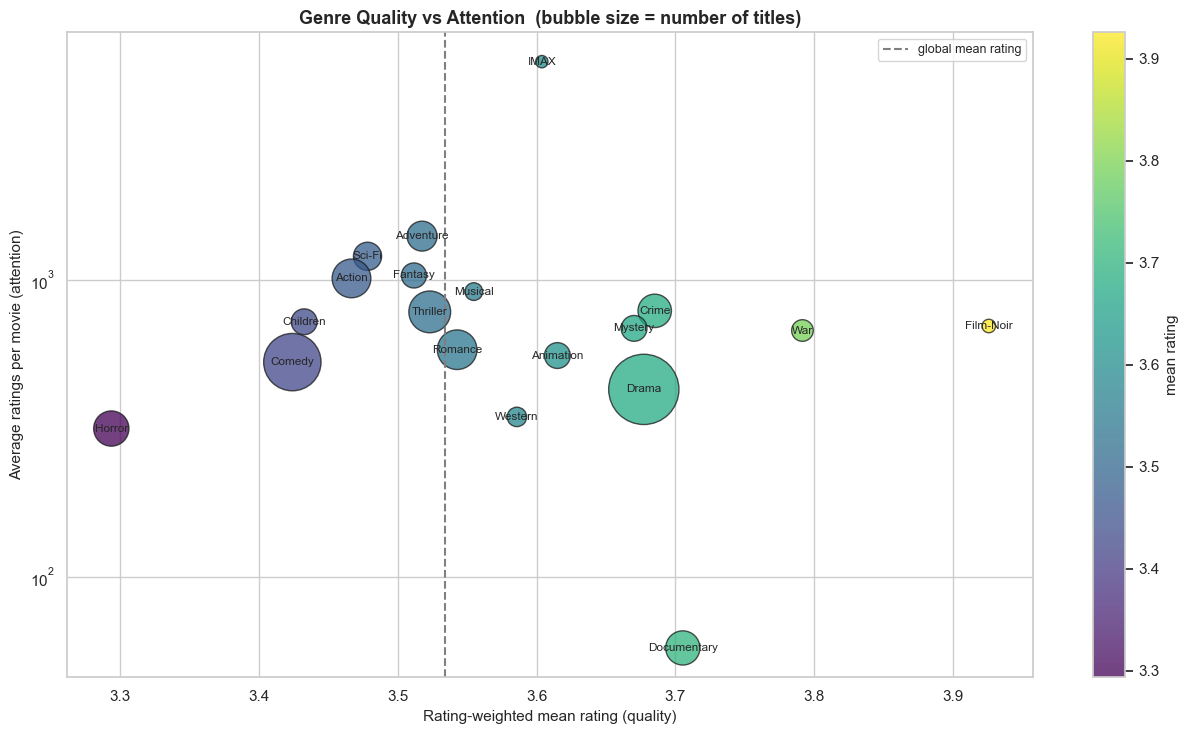

In [45]:
cat_mean = item["mean"].reindex(movies["movieId"]).values
rows = []
for g in Gr.columns:
    m = Gr[g].values == 1
    w = cat_n.values[m]
    if w.sum() == 0:
        continue
    mu = np.nansum(cat_mean[m] * w) / w[~np.isnan(cat_mean[m])].sum()
    rows.append({"genre": g, "n_movies": int(m.sum()), "mean_rating": mu, "avg_ratings_per_movie": w.sum() / m.sum()})
gq = pd.DataFrame(rows).sort_values("mean_rating", ascending=False).reset_index(drop=True)
display(gq)

plt.figure(figsize=(13, 7.5))
sc = plt.scatter(gq["mean_rating"], gq["avg_ratings_per_movie"], s=gq["n_movies"] / gq["n_movies"].max() * 2500 + 60,
                 c=gq["mean_rating"], cmap="viridis", alpha=.75, edgecolor="k")
for _, r in gq.iterrows():
    plt.annotate(r["genre"], (r["mean_rating"], r["avg_ratings_per_movie"]), ha="center", va="center", fontsize=8.5)
plt.axvline(float(ratings.rating.mean()), ls="--", c="grey", label="global mean rating")
plt.xlabel("Rating-weighted mean rating (quality)"); plt.ylabel("Average ratings per movie (attention)")
plt.yscale("log"); plt.title("Genre Quality vs Attention  (bubble size = number of titles)"); plt.legend()
plt.colorbar(sc, label="mean rating"); plt.tight_layout(); plt.show()
KPI["best_rated_genre"] = gq.iloc[0]["genre"]

### 📌 Observation
- Quality varies from **3.29 (Horror) to 3.93 (Film-Noir)** around the global mean of 3.53: War (3.79), Documentary (3.71), Crime (3.69), Drama (3.68) and Mystery (3.67) are above average; Comedy (3.42), Children (3.43), Action (3.47), Sci-Fi (3.48) and Horror are below.
- Attention differs by orders of magnitude: **IMAX ≈ 5,450 ratings per title, Adventure ≈ 1,410, Sci-Fi ≈ 1,200, Action ≈ 1,010**, but **Documentary only ≈ 58** and Western ≈ 346, Horror ≈ 316.
- Documentary is the clearest "loved but ignored" genre (quality 3.71, lowest attention), while Action/Adventure/Sci-Fi are "popular but only average". Drama is by far the biggest bubble (25,606 titles) with above-average quality but only ≈ 428 ratings per title.

### 💡 Pipeline / Engineering Decision
- Raw popularity is never used as a quality proxy: genre-level attention and quality are decoupled, so `genre_mean_rating` and `genre_attention` become separate context features.
- The re-ranker gets a **calibrated-recommendation / quality-floor term**: users with an affinity for Documentary, War or Film-Noir are served those genres even though their global attention is low.
- Genre-level quality (range ≈ 0.6 stars) is much smaller than item-level quality spread (Step 14), so genre means are only a weak prior.

---
## 🔹 Step 14 — Rating Bias — User & Item Mean Distributions

### ❓ Why
Users differ in how generously they rate (a "harsh" 3 vs a "generous" 3) and movies differ in intrinsic quality. Measuring the spread of user means and item means quantifies how much variance is explained by simple biases before any personalisation.

### 💼 Business Insight
Bias terms are the cheapest, most explainable signal in a recommender. If biases already explain a large part of the variance, the business can ship a strong baseline immediately and judge complex models by how much they add on top.

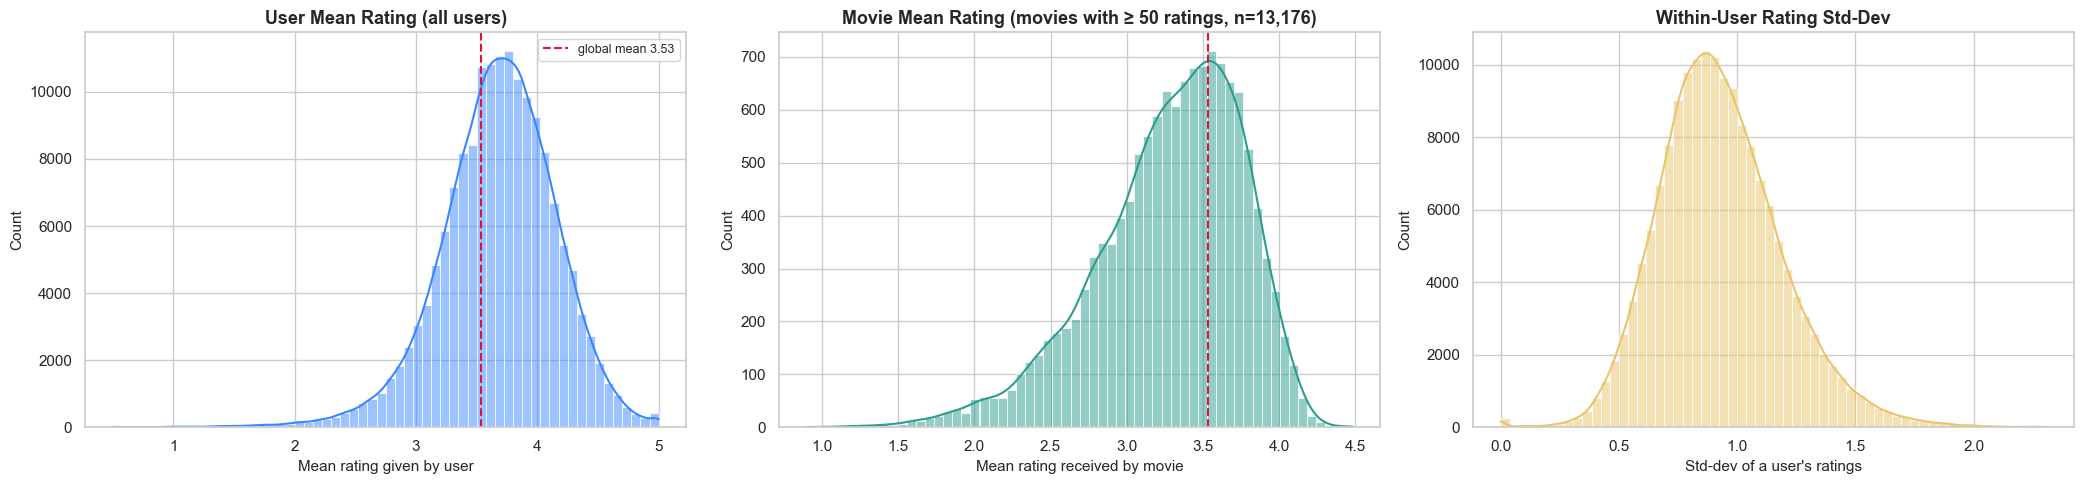

std of user means = 0.477 | std of movie means (n>=50) = 0.485 | overall rating std = 1.061
Users with std < 0.5 ('constant raters'): 3.2%
Share of rating variance in user means ≈ 20.3% | in movie means (n>=50) ≈ 20.9%


In [46]:
u_mean, u_std = user["mean_rating"].values, user["std_rating"].dropna().values
i50 = item[item["n"] >= 50]
G_MEAN = float(ratings.rating.mean())
const_raters = float((user["std_rating"] < 0.5).mean() * 100)

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
sns.histplot(u_mean, bins=60, kde=True, color="#3a86ff", ax=ax[0]); ax[0].axvline(G_MEAN, c="crimson", ls="--", label=f"global mean {G_MEAN:.2f}")
ax[0].set_title("User Mean Rating (all users)"); ax[0].set_xlabel("Mean rating given by user"); ax[0].legend()
sns.histplot(i50["mean"], bins=60, kde=True, color="#2a9d8f", ax=ax[1]); ax[1].axvline(G_MEAN, c="crimson", ls="--")
ax[1].set_title(f"Movie Mean Rating (movies with ≥ 50 ratings, n={len(i50):,})"); ax[1].set_xlabel("Mean rating received by movie")
sns.histplot(u_std, bins=60, kde=True, color="#e9c46a", ax=ax[2]); ax[2].set_title("Within-User Rating Std-Dev"); ax[2].set_xlabel("Std-dev of a user's ratings")
plt.tight_layout(); plt.show()

print(f"std of user means = {np.std(u_mean):.3f} | std of movie means (n>=50) = {i50['mean'].std():.3f} | overall rating std = {ratings.rating.std():.3f}")
print(f"Users with std < 0.5 ('constant raters'): {const_raters:.1f}%")
print(f"Share of rating variance in user means ≈ {np.var(u_mean)/ratings.rating.var():.1%} | in movie means (n>=50) ≈ {i50['mean'].var()/ratings.rating.var():.1%}")
KPI.update(user_mean_std=round(float(np.std(u_mean)), 3), item_mean_std=round(float(i50['mean'].std()), 3))

### 📌 Observation
- **User means** (left): bell-shaped, centred at **≈ 3.8 — above the global mean 3.53** — with a long left tail down to ≈ 2 and a small spike at exactly 5.0 (users who give only top scores). Std of user means = **0.477**.
- **Movie means (≥ 50 ratings, n = 13,176)** (middle): peak at ≈ 3.5–3.6, strongly **left-skewed** with a tail down to ≈ 1.0 and a hard ceiling around 4.5. Std = **0.485**.
- Within-user std (right) peaks at ≈ 0.85; **3.2% of users have std < 0.5** ("constant raters", visible as a small spike at 0).
- Variance share: user means explain ≈ **20.3%** and movie means ≈ **20.9%** of the overall rating variance (std 1.061) — user bias and item bias are about equally strong.

### 💡 Pipeline / Engineering Decision
- Every rating-prediction model includes explicit bias terms **`μ + b_u + b_i`** (implemented and benchmarked in Step 31).
- User-user / item-item similarity uses **mean-centred ratings** (adjusted cosine), because a user mean spread of ±0.48 would otherwise be mistaken for taste.
- Users with std < 0.5 (3.2%) are flagged as constant raters and **down-weighted** in ranking-model training.

---
## 🔹 Step 15 — Popularity vs Quality — Small-Sample Trap & Bayesian Shrinkage

### ❓ Why
A movie with a single 5-star rating has a "perfect" average and would top any naive "highest rated" list. Relating rating count to mean rating exposes this small-sample trap, and a Bayesian-shrunk score shows the fix.

### 💼 Business Insight
"Top rated" shelves are only credible if they exclude noise. Showing a title with one rating at the top of a home screen damages trust and wastes the most valuable pixel on the page.

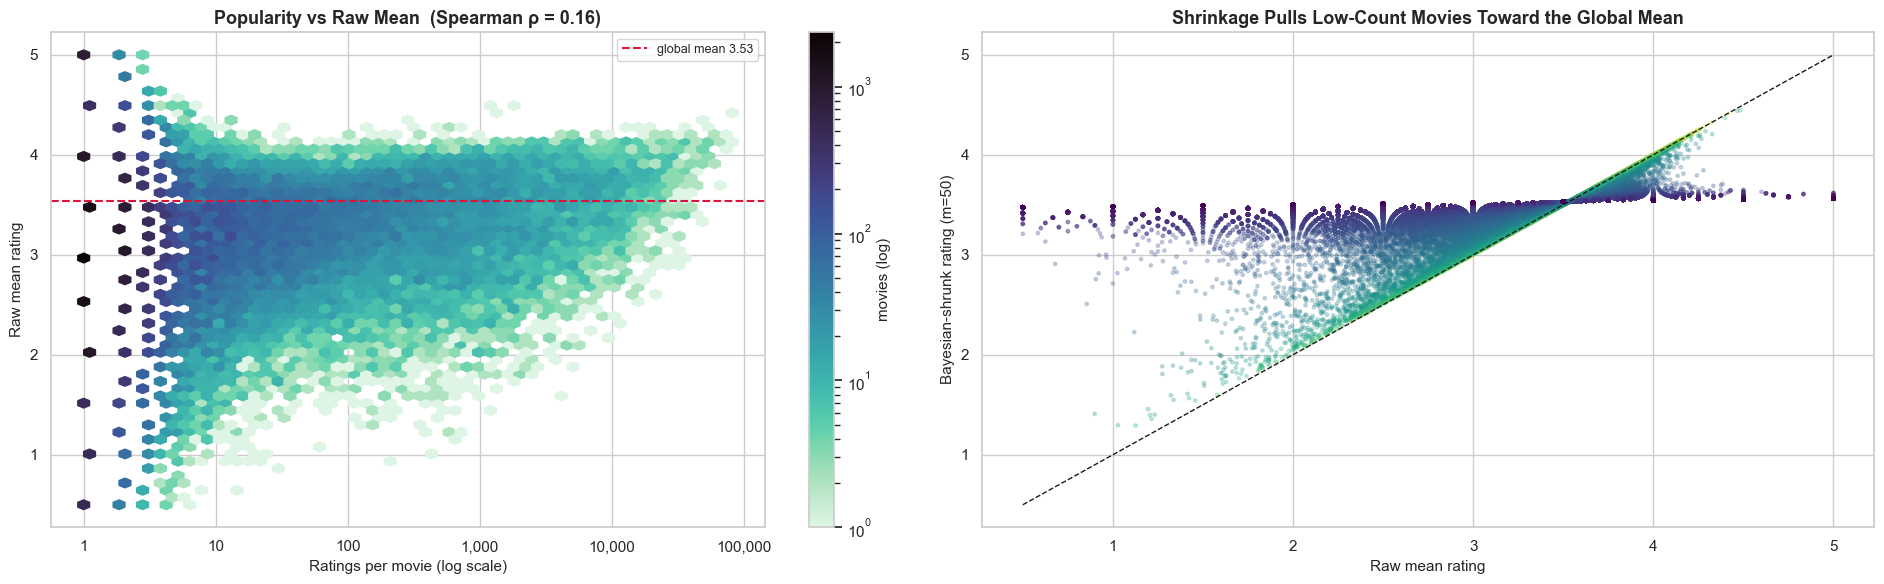

❌ Top-8 by RAW mean (small-sample trap):


,n,mean,title
0,3,5.0000,Borrowed Time (2012)
1,3,5.0000,Awaken (2013)
2,3,5.0000,Lonesome Dove Church (2014)
3,3,5.0000,Sound of Christmas (2016)
4,2,5.0000,Genius on Hold (2013)
5,2,5.0000,El camino (2008)
6,2,5.0000,Placebo: Soulmates Never Die: Live in Paris 20...
7,2,5.0000,War Arrow (1954)


✅ Top-8 by SHRUNK score:


,n,wr,title
0,1124,4.4427,Planet Earth II (2016)
1,1747,4.4389,Planet Earth (2006)
2,81482,4.4130,"Shawshank Redemption, The (1994)"
3,1356,4.3678,Band of Brothers (2001)
4,52498,4.3236,"Godfather, The (1972)"
5,55366,4.2837,"Usual Suspects, The (1995)"
6,34188,4.2607,"Godfather: Part II, The (1974)"
7,13367,4.2521,Seven Samurai (Shichinin no samurai) (1954)


In [47]:
C = G_MEAN; m = PRIOR_STRENGTH
item["wr"] = (item["n"] * item["mean"] + m * C) / (item["n"] + m)
from scipy.stats import spearmanr
rho, _ = spearmanr(np.log10(item["n"]), item["mean"])

fig, ax = plt.subplots(1, 2, figsize=(19, 6))
hb = ax[0].hexbin(np.log10(item["n"]), item["mean"], gridsize=55, bins="log", cmap="mako_r", mincnt=1)
plt.colorbar(hb, ax=ax[0], label="movies (log)")
ax[0].axhline(C, ls="--", c="crimson", label=f"global mean {C:.2f}")
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{10**v:,.0f}")); ax[0].set_xlabel("Ratings per movie (log scale)")
ax[0].set_ylabel("Raw mean rating"); ax[0].set_title(f"Popularity vs Raw Mean  (Spearman ρ = {rho:.2f})"); ax[0].legend()

samp = item[item["n"] >= 1]
ax[1].scatter(samp["mean"], samp["wr"], s=6, alpha=.25, c=np.log10(samp["n"]), cmap="viridis")
ax[1].plot([0.5, 5], [0.5, 5], "k--", lw=1); ax[1].set_xlabel("Raw mean rating"); ax[1].set_ylabel(f"Bayesian-shrunk rating (m={m})")
ax[1].set_title("Shrinkage Pulls Low-Count Movies Toward the Global Mean")
plt.tight_layout(); plt.show()

tm = movies.set_index("movieId")["title"]
raw_top = item.sort_values(["mean", "n"], ascending=False).head(8)[["n", "mean"]].join(tm)
wr_top  = item.sort_values("wr", ascending=False).head(8)[["n", "wr"]].join(tm)
print("❌ Top-8 by RAW mean (small-sample trap):");  display(raw_top.reset_index(drop=True))
print("✅ Top-8 by SHRUNK score:");                   display(wr_top.reset_index(drop=True))
KPI["spearman_pop_vs_mean"] = round(float(rho), 3)

### 📌 Observation
- The hexbin shows the classic funnel: for movies with < 5 ratings raw means spread over the **full 0.5–5.0 range**, while for movies with 1,000+ ratings they sit in a much narrower band (≈ 2–4.5). Popularity and mean rating are only weakly related (**Spearman ρ = 0.16**).
- The raw-mean "top-8" list consists only of obscure titles with **2–3 ratings and a perfect 5.0** (e.g. *Borrowed Time (2012)*, *Awaken (2013)*, *Lonesome Dove Church (2014)*).
- The shrunk (m = 50) list is credible: *Planet Earth II* (4.44, 1,124 ratings), *Planet Earth* (4.44), *Shawshank Redemption* (4.41, 81,482), *Band of Brothers*, *The Godfather* (4.32, 52,498), *The Usual Suspects*, *The Godfather: Part II*, *Seven Samurai*.
- On the right panel low-count movies collapse onto a flat band near the global mean (≈ 3.3–3.5), while high-count movies stay on the diagonal.

### 💡 Pipeline / Engineering Decision
- Every "average rating" feature is replaced by the **Bayesian-shrunk rating `(n·mean + 50·μ) / (n + 50)`** in the feature store and in any "Top Rated" shelf.
- `log1p(n_ratings)` is added next to it as a **confidence feature**.
- Note: *Planet Earth*, *Planet Earth II* and *Band of Brothers* are TV series, and they are exactly the titles that fail to match the movie metadata in Step 23 — "Top Rated" shelves need a content-type filter (movie vs series).

---
## 🔹 Step 16 — Cold-Start Analysis & Split Strategy — Random vs Temporal

### ❓ Why
How many test interactions involve users or movies that the model never saw during training depends entirely on how the data is split. Comparing a random split with a chronological split measures the real cold-start exposure and the optimism of a random split.

### 💼 Business Insight
In production, tomorrow's ratings are always on *tomorrow's* catalogue: new releases appear every week. A random split hides this and makes the model look better than it will perform on launch day.

,test rows with unseen USER (%),test rows with unseen MOVIE (%),distinct unseen movies in test
Random split,0.0000,0.0494,"1,133.0000"
Temporal split,78.9909,5.7608,"13,937.0000"


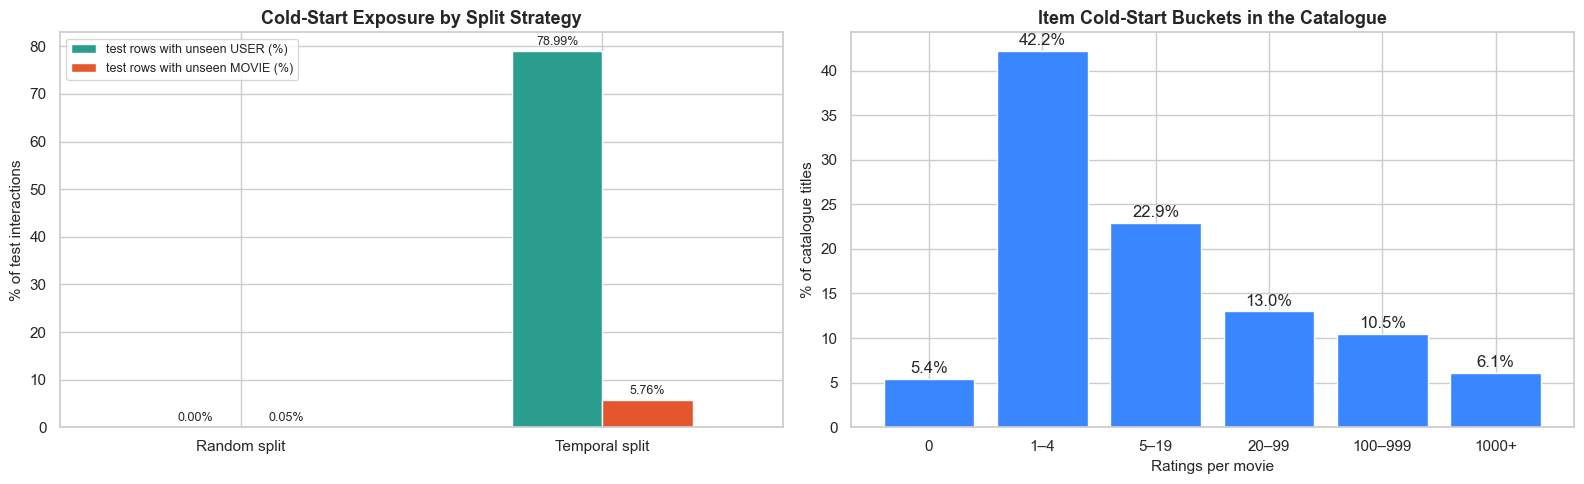

Temporal cut-off: 2018-01-04 | train rows 22,500,085 | test rows 2,500,010


In [48]:
u_arr, m_arr, ts = ratings["userId"].values, ratings["movieId"].values, ratings["timestamp"].values
cutoff_ts = int(np.quantile(ts, 1 - TEMPORAL_TEST_FRAC))
temporal_train = ts <= cutoff_ts
random_train = rng.random(len(ts)) >= TEMPORAL_TEST_FRAC

def unseen_rates(train_mask):
    seen_u = np.zeros(u_arr.max() + 1, bool); seen_u[u_arr[train_mask]] = True
    seen_m = np.zeros(m_arr.max() + 1, bool); seen_m[m_arr[train_mask]] = True
    te = ~train_mask
    return float((~seen_u[u_arr[te]]).mean() * 100), float((~seen_m[m_arr[te]]).mean() * 100), int((~seen_m[np.unique(m_arr[te])]).sum())

res = pd.DataFrame({"Random split": unseen_rates(random_train), "Temporal split": unseen_rates(temporal_train)},
                   index=["test rows with unseen USER (%)", "test rows with unseen MOVIE (%)", "distinct unseen movies in test"]).T
display(res)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
res.iloc[:, :2].plot(kind="bar", ax=ax[0], color=["#2a9d8f", "#e4572e"], rot=0)
ax[0].set_ylabel("% of test interactions"); ax[0].set_title("Cold-Start Exposure by Split Strategy")
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.2f%%", padding=2, fontsize=9)

pop_buckets = pd.cut(cat_n, [-1, 0, 4, 19, 99, 999, np.inf], labels=["0", "1–4", "5–19", "20–99", "100–999", "1000+"])
share_titles = pop_buckets.value_counts(normalize=True).sort_index() * 100
b = ax[1].bar(share_titles.index.astype(str), share_titles.values, color="#3a86ff"); ax[1].bar_label(b, fmt="%.1f%%", padding=2)
ax[1].set_xlabel("Ratings per movie"); ax[1].set_ylabel("% of catalogue titles"); ax[1].set_title("Item Cold-Start Buckets in the Catalogue")
plt.tight_layout(); plt.show()

print(f"Temporal cut-off: {pd.to_datetime(cutoff_ts, unit='s'):%Y-%m-%d} | train rows {temporal_train.sum():,} | test rows {(~temporal_train).sum():,}")
KPI.update(temporal_cutoff=str(pd.to_datetime(cutoff_ts, unit="s").date()), test_unseen_movie_pct=round(res.iloc[1, 1], 2))

### 📌 Observation
- **Random split:** 0.00% of test rows have an unseen user and only 0.05% an unseen movie (1,133 distinct movies) — practically no cold start.
- **Temporal split** (cut-off **2018-01-04**, 22,500,085 train / 2,500,010 test rows): **78.99% of test rows come from users never seen in training** and 5.76% from unseen movies (**13,937 distinct movies**). Most MovieLens users rate in short bursts, so the last 10% of time is dominated by new users.
- Catalogue buckets (right): **0 ratings 5.4%, 1–4 ratings 42.2%, 5–19 22.9%, 20–99 13.0%, 100–999 10.5%, 1000+ 6.1%** — 70.5% of titles have fewer than 20 ratings.

### 💡 Pipeline / Engineering Decision
- Two evaluation protocols are defined: (1) a **global temporal split** (cut-off 2018-01-04) that measures *new-user + new-item* performance, and (2) a **per-user chronological split** (last N interactions of each known user) for warm-user ranking quality. A random split is rejected.
- Metrics are always reported separately for **warm vs cold users** and **warm vs cold items**; the 79% unseen-user share means the global split alone says little about personalisation.
- Fallback routing: unseen user → popularity-by-genre prior (+ onboarding picks); unseen item → content embedding (genome / metadata / poster).
- The per-user split goes into `src/split.py` next to the global one; Step 31 below benchmarks the global temporal split only.

---
## 🔹 Step 17 — User-Generated Tags — Coverage, Noise & Vocabulary

### ❓ Why
Free-text tags are a rich but noisy content signal. We need to know how many movies they cover, how messy the vocabulary is (case variants, duplicates) and which tags dominate.

### 💼 Business Insight
User tags capture what genre labels cannot — mood, themes, "twist ending", "visually stunning" — the same language users use when searching. They power semantic search and "because you like …" explanations, if the coverage is good enough.

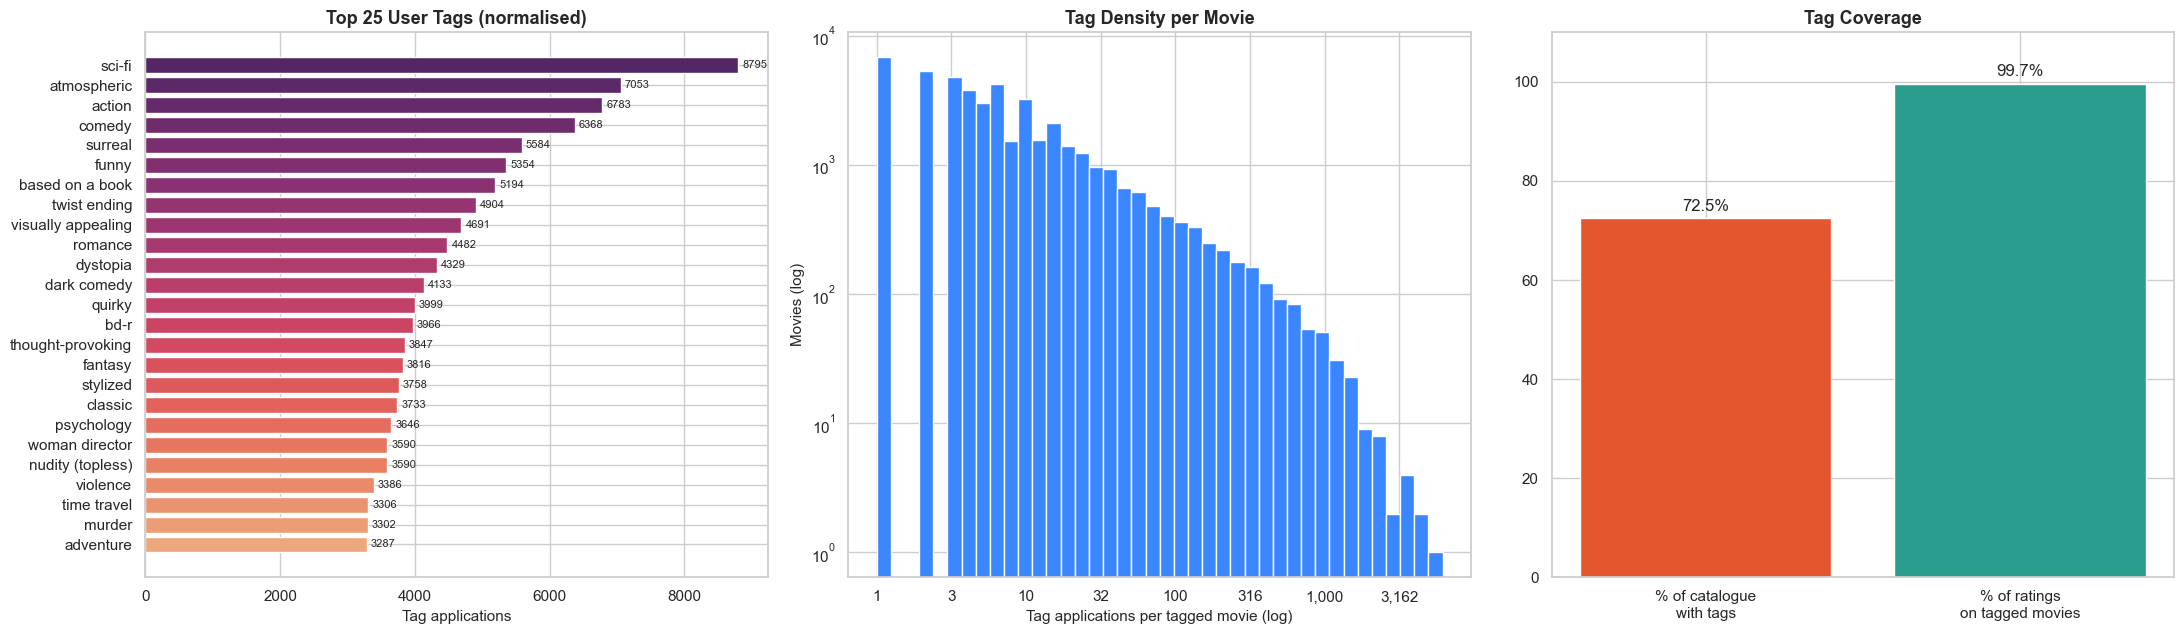

Tag applications: 1,093,344 | taggers: 14,592 | tagged movies: 45,251
Unique tags raw = 73,050 → after lower/strip = 65,403 (−10.5%) | multi-word tags: 44.4%


In [49]:
tg = tags.dropna(subset=["tag"]).copy()
tg["tag_norm"] = tg["tag"].astype(str).str.lower().str.strip()
raw_u, norm_u = tg["tag"].nunique(), tg["tag_norm"].nunique()
per_movie = tg.groupby("movieId").size()
cov["has_tags"] = cov["movieId"].isin(tg["movieId"])
top = tg["tag_norm"].value_counts().head(25)
tag_len = tg["tag_norm"].str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(22, 6.5))
b = ax[0].barh(top.index[::-1], top.values[::-1], color=sns.color_palette("flare", 25)); ax[0].bar_label(b, padding=3, fontsize=8)
ax[0].set_title("Top 25 User Tags (normalised)"); ax[0].set_xlabel("Tag applications")
ax[1].hist(np.log10(per_movie.values), bins=40, color="#3a86ff", edgecolor="white")
ax[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{10**v:,.0f}")); ax[1].set_yscale("log")
ax[1].set_xlabel("Tag applications per tagged movie (log)"); ax[1].set_ylabel("Movies (log)"); ax[1].set_title("Tag Density per Movie")
cov_pct = pd.Series({"movies with ≥ 1 tag (% of catalogue)": cov["has_tags"].mean() * 100,
                     "rating mass on tagged movies (%)": cov.loc[cov.has_tags, "n_ratings"].sum() / cov["n_ratings"].sum() * 100})
b = ax[2].bar(["% of catalogue\nwith tags", "% of ratings\non tagged movies"], cov_pct.values, color=["#e4572e", "#2a9d8f"])
ax[2].bar_label(b, fmt="%.1f%%", padding=3); ax[2].set_ylim(0, 110); ax[2].set_title("Tag Coverage")
plt.tight_layout(); plt.show()

print(f"Tag applications: {len(tg):,} | taggers: {tg.userId.nunique():,} | tagged movies: {per_movie.shape[0]:,}")
print(f"Unique tags raw = {raw_u:,} → after lower/strip = {norm_u:,} (−{(1-norm_u/raw_u):.1%}) | multi-word tags: {(tag_len>1).mean():.1%}")
KPI.update(tag_apps=len(tg), tag_catalog_coverage_pct=round(float(cov_pct.iloc[0]), 1))

### 📌 Observation
- **1,093,344 tag applications by only 14,592 taggers on 45,251 movies** — i.e. **72.5% of the catalogue** is tagged, and those movies carry **99.7% of all ratings**.
- The vocabulary is noisy: **73,050 raw unique tags collapse to 65,403 after `lower().strip()` (−10.5%)**, and 44.4% of tags are multi-word phrases.
- Top tags are a mix of genre-like (*sci-fi* 8,795, *action*, *comedy*) and theme/mood tags (*atmospheric* 7,053, *surreal* 5,584, *twist ending*, *visually appealing*, *dark comedy*). The top-25 also contains administrative/noisy tags such as **`bd-r` (3,966)** and **`nudity (topless)` (3,590)**.
- Tags per movie follow a steep long tail (log-log histogram): thousands of movies have a single tag, a few have more than 3,000.

### 💡 Pipeline / Engineering Decision
- Tags are normalised (`lower`, `strip`, collapse whitespace) and filtered with a **minimum-frequency rule (tag applied to ≥ N distinct movies)** so one-user idiosyncratic tags and admin tags like `bd-r` do not become features.
- Tags are used as an **auxiliary TF-IDF feature**, with the dense genome (Step 18) as the main content vector; `has_tags` is stored in the coverage table (`cov`) for routing in Step 29.
- Rows with null `tag` are dropped before any counting.

---
## 🔹 Step 18 — Tag Genome — Dense Content Vectors, PCA & Similarity Sanity Check

### ❓ Why
The Tag Genome gives each covered movie a **relevance score (0–1) for each of 1,128 tags** — a dense, pre-computed content embedding. We check its distribution, its effective dimensionality (PCA) and run an item-to-item similarity test to see whether it captures real movie similarity.

### 💼 Business Insight
A dense content vector is exactly what lets a recommender say "if you liked *this*, try *that*" for titles with few ratings — the foundation of explainable "similar titles" shelves on an OTT product page.

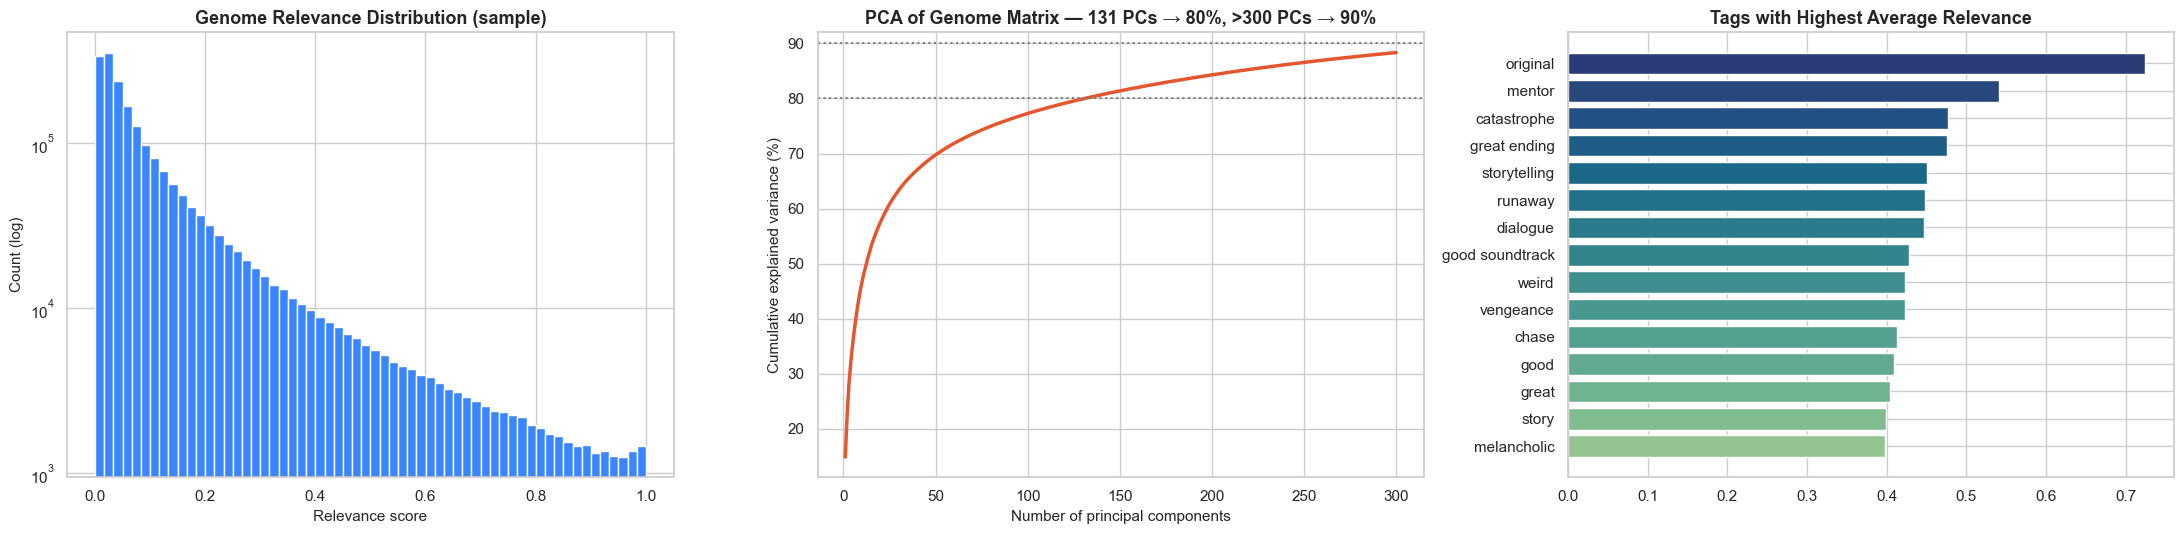

Genome matrix: 13,816 movies × 1,128 tags | complete (every movie has all tags): True
Median relevance = 0.056 | share of scores < 0.1: 66.2%

Nearest neighbours of 'Toy Story (1995)' in genome space:


,title (raw cosine),cosine,title (mean-centred cosine),cosine_centred
0,"Monsters, Inc. (2001)",0.9561,"Monsters, Inc. (2001)",0.9004
1,Toy Story 2 (1999),0.9521,Toy Story 2 (1999),0.8822
2,"Bug's Life, A (1998)",0.9455,"Bug's Life, A (1998)",0.8661
3,Toy Story 3 (2010),0.9307,Finding Nemo (2003),0.8469
4,Finding Nemo (2003),0.9290,Toy Story 3 (2010),0.8383
5,Ratatouille (2007),0.9217,Ratatouille (2007),0.8208
6,"Incredibles, The (2004)",0.9076,"Incredibles, The (2004)",0.7945
7,Ice Age (2002),0.9048,Up (2009),0.7792


Cumulative explained variance: 1 PCs = 14.9% | 20 PCs = 57.5% | 50 PCs = 69.7% | 100 PCs = 77.3% | 300 PCs = 88.3%


1726

In [50]:
from sklearn.decomposition import PCA

tag_sorted = np.sort(genome_tags["tagId"].values)
mids = np.sort(genome_scores["movieId"].unique())
rpos = np.searchsorted(mids, genome_scores["movieId"].values)
cpos = np.searchsorted(tag_sorted, genome_scores["tagId"].values)
M = np.zeros((len(mids), len(tag_sorted)), dtype=np.float32)
M[rpos, cpos] = genome_scores["relevance"].values
per_movie_rows = genome_scores.groupby("movieId").size()
complete = bool((per_movie_rows == len(tag_sorted)).all())
rel_sample = genome_scores["relevance"].sample(min(len(genome_scores), GENOME_SAMPLE), random_state=SEED).values
cov["has_genome"] = cov["movieId"].isin(mids)
g_tag_mean = pd.Series(M.mean(0), index=tag_sorted).rename("mean_rel").to_frame().join(genome_tags.set_index("tagId")["tag"]).sort_values("mean_rel", ascending=False)

ncomp = int(min(300, M.shape[0] - 1, M.shape[1]))
pca = PCA(n_components=ncomp, svd_solver="randomized", random_state=SEED).fit(M)
cum = np.cumsum(pca.explained_variance_ratio_)
k80 = int(np.searchsorted(cum, 0.80) + 1) if cum[-1] >= 0.80 else None
k90 = int(np.searchsorted(cum, 0.90) + 1) if cum[-1] >= 0.90 else None
lab = lambda k: f"{k} PCs" if k else f">{ncomp} PCs"

fig, ax = plt.subplots(1, 3, figsize=(22, 5.5))
ax[0].hist(rel_sample, bins=60, color="#3a86ff", edgecolor="white"); ax[0].set_yscale("log")
ax[0].set_xlabel("Relevance score"); ax[0].set_ylabel("Count (log)"); ax[0].set_title("Genome Relevance Distribution (sample)")
ax[1].plot(np.arange(1, ncomp + 1), cum * 100, c="#e4572e", lw=2.5)
ax[1].axhline(80, ls=":", c="grey"); ax[1].axhline(90, ls=":", c="grey")
ax[1].set_xlabel("Number of principal components"); ax[1].set_ylabel("Cumulative explained variance (%)")
ax[1].set_title(f"PCA of Genome Matrix — {lab(k80)} → 80%, {lab(k90)} → 90%")
tp = g_tag_mean.head(15)[::-1]; ax[2].barh(tp["tag"], tp["mean_rel"], color=sns.color_palette("crest", 15)); ax[2].set_title("Tags with Highest Average Relevance")
plt.tight_layout(); plt.show()

# --- similarity sanity check (cosine) on the genome vectors
Mn = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)
tmap = movies.set_index("movieId")["title"]
anchor_candidates = movies.loc[movies["title"].str.startswith("Toy Story (1995)"), "movieId"]
anchor = int(anchor_candidates.iloc[0]) if len(anchor_candidates) and anchor_candidates.iloc[0] in set(mids) else int(cov.loc[cov.has_genome].sort_values("n_ratings").iloc[-1]["movieId"])
a_idx = int(np.searchsorted(mids, anchor))
sims = Mn @ Mn[a_idx]
top_idx = np.argsort(-sims)[1:9]
print(f"Genome matrix: {M.shape[0]:,} movies × {M.shape[1]:,} tags | complete (every movie has all tags): {complete}")
print(f"Median relevance = {np.median(rel_sample):.3f} | share of scores < 0.1: {(rel_sample < 0.1).mean():.1%}")
print(f"\nNearest neighbours of '{tmap[anchor]}' in genome space:")
Mc = M - M.mean(axis=0, keepdims=True)                      # mean-centred genome vectors
Mcn = Mc / (np.linalg.norm(Mc, axis=1, keepdims=True) + 1e-9)
sims_c = Mcn @ Mcn[a_idx]; top_c = np.argsort(-sims_c)[1:9]
display(pd.DataFrame({"title (raw cosine)": tmap.reindex(mids[top_idx]).values, "cosine": sims[top_idx],
                      "title (mean-centred cosine)": tmap.reindex(mids[top_c]).values, "cosine_centred": sims_c[top_c]}))
print("Cumulative explained variance: " + " | ".join(f"{k} PCs = {cum[k-1]:.1%}" for k in sorted({1, 20, 50, 100, ncomp}) if k <= ncomp))
KPI.update(genome_movies=int(len(mids)), genome_pcs_80pct=(k80 if k80 else f">{ncomp}"))
del rpos, cpos; gc.collect()

### 📌 Observation
- The genome matrix is a complete **13,816 movies × 1,128 tags** (every movie has all 1,128 scores). Relevance is extremely right-skewed: **median 0.056, 66.2% of scores < 0.1**, falling smoothly from ≈ 350K per bin near 0 to ≈ 1.4K near 1.0 (log y-axis) — each movie "switches on" only a small set of tags.
- The PCA curve (now fitted up to 300 components) shows the genome is **not very compressible**: PC 1 explains **14.9%**, 20 PCs **57.5%**, 50 PCs **69.7%**, 100 PCs **77.3%**, **80% is reached only at 131 PCs** and 300 PCs still give just **88.3%** — the 90% line is never crossed in the plotted range.
- The right panel shows the tags with the highest average relevance are generic ones — *original (≈ 0.72), mentor (≈ 0.54), catastrophe, great ending, storytelling, good, great, story* — tags that are "on" for many movies and therefore carry little discriminative power.
- Similarity sanity check for **Toy Story (1995)**: raw cosine returns *Monsters, Inc.* (0.956), *Toy Story 2* (0.952), *A Bug's Life* (0.946), *Toy Story 3*, *Finding Nemo*, *Ratatouille*, *The Incredibles*, *Ice Age* (0.905) — all animation/Pixar-style titles, but the whole list sits in a very narrow 0.90–0.96 band. After **mean-centring** the band widens to 0.78–0.90, *Finding Nemo* moves above *Toy Story 3*, and *Up (2009)* replaces *Ice Age* in the top 8.

### 💡 Pipeline / Engineering Decision
- **Fix applied and verified in this cell:** PCA now fits up to 300 components and reports the real thresholds (80% at **131 PCs**, 90% not reached within 300) instead of the artefact of the old 100-component cap; `KPI["genome_pcs_80pct"] = 131`.
- The genome content vector is **mean-centred and reduced to ≈ 128 dimensions with PCA/SVD** (≈ 80% of the variance, in line with the 131-PC threshold); going to 300 dimensions would add only ≈ 8 more percentage points of variance, so 128 is the cost-effective size for the index.
- **Cosine similarity is always computed on mean-centred vectors**: centring spreads the Toy Story neighbour scores from 0.90–0.96 to 0.78–0.90, so scores become more discriminative while the same Pixar/animation neighbours are kept.
- Generic high-relevance tags (*original, mentor, good, great, story*) are down-weighted (TF-IDF-style weighting or dropped before PCA) so they do not dominate the item–item "similar titles" index (FAISS/Annoy); the Toy Story → Pixar neighbour list is kept as the acceptance test for that index.

---
## 🔹 Step 19 — External Link Coverage — The Bridge to IMDB / TMDB

### ❓ Why
`links.csv` is the only bridge between MovieLens and the external datasets. Its null rate and uniqueness decide how much external metadata can ever be joined.

### 💼 Business Insight
Every title without a link is a title that stays "metadata-blind" forever. Knowing this ceiling up-front prevents over-promising on a metadata-driven content model.

,% of catalogue,% of rating mass
has imdbId,100.0000,100.0000
has tmdbId,99.8286,99.9903
has both,99.8286,99.9903
has neither,0.0000,0.0000


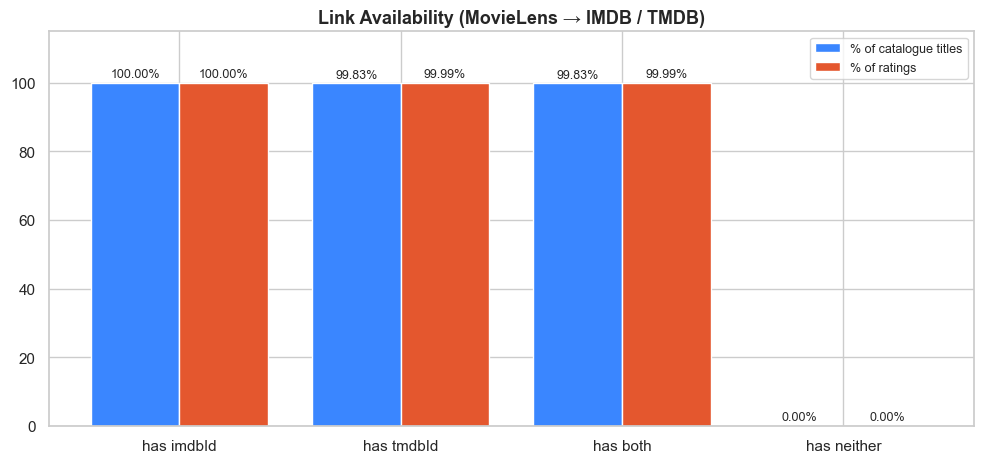

Duplicate imdbId: 0 | duplicate tmdbId: 35
Canonical IMDB key example: tt0114709


In [51]:
lk = links.set_index("movieId").reindex(cov["movieId"])
cov["imdbId"], cov["tmdbId"] = lk["imdbId"].values, lk["tmdbId"].values
cov["imdbId_i"] = cov["imdbId"].fillna(-1).astype("int64")
cov["tmdbId_i"] = cov["tmdbId"].fillna(-1).astype("int64")
w = cov["n_ratings"]
def both(mask):  return mask.mean() * 100, w[mask].sum() / w.sum() * 100
tab = pd.DataFrame({"has imdbId": both(cov.imdbId_i > 0), "has tmdbId": both(cov.tmdbId_i > 0),
                    "has both": both((cov.imdbId_i > 0) & (cov.tmdbId_i > 0)),
                    "has neither": both((cov.imdbId_i < 0) & (cov.tmdbId_i < 0))}, index=["% of catalogue", "% of rating mass"]).T
display(tab)

fig, ax = plt.subplots(figsize=(10, 4.8)); x = np.arange(len(tab)); wd = 0.4
b1 = ax.bar(x - wd / 2, tab["% of catalogue"], wd, color="#3a86ff", label="% of catalogue titles")
b2 = ax.bar(x + wd / 2, tab["% of rating mass"], wd, color="#e4572e", label="% of ratings")
ax.bar_label(b1, fmt="%.2f%%", padding=2, fontsize=9); ax.bar_label(b2, fmt="%.2f%%", padding=2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(tab.index); ax.set_ylim(0, 115); ax.set_title("Link Availability (MovieLens → IMDB / TMDB)"); ax.legend()
plt.tight_layout(); plt.show()

dup_imdb = int(cov.loc[cov.imdbId_i > 0, "imdbId_i"].duplicated().sum()); dup_tmdb = int(cov.loc[cov.tmdbId_i > 0, "tmdbId_i"].duplicated().sum())
print(f"Duplicate imdbId: {dup_imdb} | duplicate tmdbId: {dup_tmdb}")
print("Canonical IMDB key example:", "tt" + str(int(cov.loc[cov.imdbId_i > 0, "imdbId_i"].iloc[0])).zfill(7))
KPI.update(link_imdb_pct=round(float(tab.loc["has imdbId", "% of catalogue"]), 2), link_tmdb_pct=round(float(tab.loc["has tmdbId", "% of catalogue"]), 2))

### 📌 Observation
- **`imdbId` exists for 100.00%** of the catalogue; **`tmdbId` for 99.83%** of titles (107 missing) and **99.99% of rating mass**. No title lacks both ("has neither" = 0.00%).
- **0 duplicated `imdbId`**, but **35 duplicated `tmdbId` values** (two MovieLens movies pointing at one TMDB film). Example key: `tt0114709` (Toy Story).

### 💡 Pipeline / Engineering Decision
- Join key priority is **`tmdbId` first, `imdbId` as fallback** — the metadata file is de-duplicated on each key before merging to prevent the 35 duplicated TMDB ids from creating extra rows.
- IMDB ids are zero-padded to 7 digits (`tt%07d`) whenever string ids have to be matched.
- Because link coverage is ≈ 100%, link availability is not a bottleneck; the real match rate against the 1M file is measured in Step 23.

---
## 🔹 Step 20 — Load the 1M-Movie IMDB + TMDB Metadata (Schema-Robust, Chunked)

### ❓ Why
This is the largest file (~1M movies, ~950 MB). Loading it with all text columns would exhaust RAM, and its exact column names vary between Kaggle versions. A schema-resolving, chunked loader converts heavy text into compact numeric features on the fly.

### 💼 Business Insight
Metadata (language, runtime, votes, popularity, plot overview) is what lets a recommender describe a movie that nobody has rated yet — critical for new-release launches, where there is *no* interaction history on day one.

Resolved columns : {'tmdb_id': 'id', 'imdb_id': 'imdb_id', 'title': 'title', 'release_date': 'release_date', 'vote_average': 'vote_average', 'vote_count': 'vote_count', 'imdb_rating': 'IMDB_Rating', 'popularity': 'popularity', 'runtime': 'runtime', 'budget': 'budget', 'revenue': 'revenue', 'original_language': 'original_language', 'overview': 'overview', 'status': 'status', 'adult': 'adult', 'keywords': 'keywords', 'director': 'Director', 'production_companies': 'production_companies', 'tagline': 'tagline', 'poster_path': 'poster_path'}
Not in this file : ['imdb_votes', 'genres', 'cast']

⏱️  Loaded 1,072,255 rows in 59s | compact memory: 357 MB


,tmdb_id,vote_average,vote_count,imdb_rating,imdb_votes,popularity,runtime,budget,revenue,imdb_num,release_year,original_language,status,adult,genres,has_overview,has_tagline,has_keywords,has_cast,has_director,has_production_companies,has_poster_path,has_genres,overview_len,n_keywords,n_cast
0,"27,205.0000",8.3640,"34,495.0000",8.8000,NaN,83.9520,148.0000,"160,000,000.0000","825,532,736.0000","1,375,666.0000","2,010.0000",en,Released,False,,True,True,True,False,True,True,True,False,280,20,0
1,"157,336.0000",8.4170,"32,571.0000",8.6000,NaN,140.2410,169.0000,"165,000,000.0000","701,729,216.0000","816,692.0000","2,014.0000",en,Released,False,,True,True,True,False,True,True,True,False,198,32,0
2,155.0000,8.5120,"30,619.0000",9.0000,NaN,130.6430,152.0000,"185,000,000.0000","1,004,558,464.0000","468,569.0000","2,008.0000",en,Released,False,,True,True,True,False,True,True,True,False,396,18,0


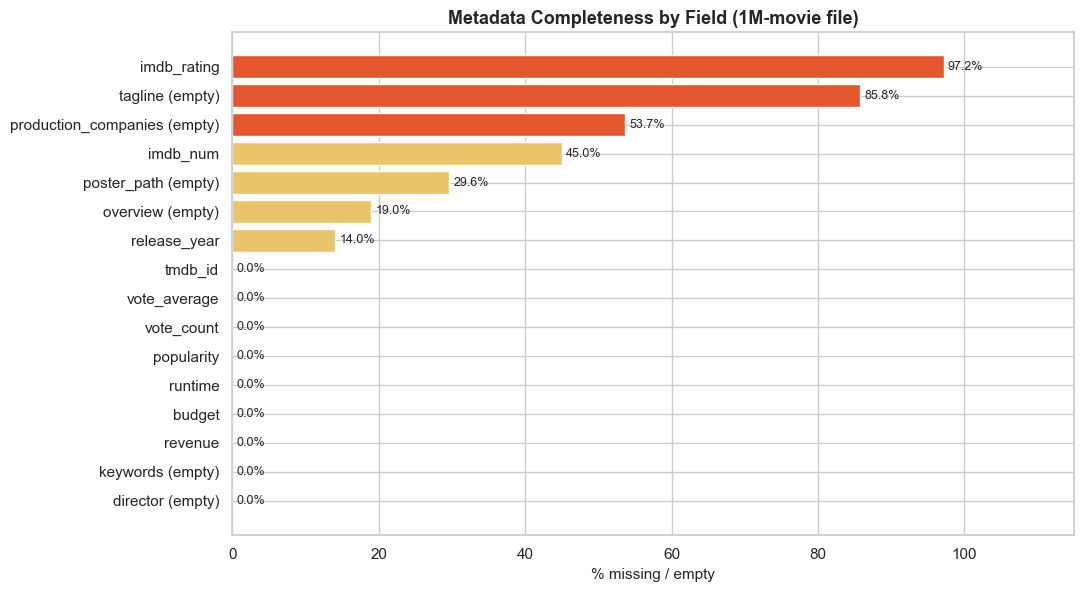

In [52]:
BIG = locate("imdb tmdb movie metadata", startswith=True)
raw_cols = list(pd.read_csv(BIG, nrows=0, encoding_errors="replace").columns)
low = {c.lower().strip(): c for c in raw_cols}

CAND = {
 "tmdb_id": ["id", "tmdb_id", "tmdbid"], "imdb_id": ["imdb_id", "imdbid", "tconst"], "title": ["title", "original_title", "name"],
 "release_date": ["release_date", "releasedate", "release_year", "year"], "vote_average": ["vote_average", "tmdb_rating", "tmdb_vote_average"],
 "vote_count": ["vote_count", "tmdb_votes"], "imdb_rating": ["imdb_rating", "averagerating", "imdb_score"], "imdb_votes": ["imdb_votes", "numvotes"],
 "popularity": ["popularity"], "runtime": ["runtime", "runtimeminutes"], "budget": ["budget"], "revenue": ["revenue"],
 "original_language": ["original_language", "language"], "genres": ["genres", "genre"], "overview": ["overview", "plot"], "status": ["status"],
 "adult": ["adult"], "keywords": ["keywords"], "cast": ["cast", "actors"], "director": ["director", "directors"],
 "production_companies": ["production_companies"], "tagline": ["tagline"], "poster_path": ["poster_path"]}
RES = {k: next((low[c] for c in cands if c in low), None) for k, cands in CAND.items()}
use_cols = sorted({c for c in RES.values() if c})
print("Resolved columns :", {k: v for k, v in RES.items() if v})
print("Not in this file :", [k for k, v in RES.items() if v is None])

NUM = ["tmdb_id", "vote_average", "vote_count", "imdb_rating", "imdb_votes", "popularity", "runtime", "budget", "revenue"]
FLAGS = ["overview", "tagline", "keywords", "cast", "director", "production_companies", "poster_path", "genres"]

def parse_names(s):
    if not isinstance(s, str) or not s.strip(): return []
    s = s.strip()
    if s.startswith("["):
        names = re.findall(r"['\"]name['\"]\s*:\s*['\"]([^'\"]+)['\"]", s)
        if names: return names
        try: return [str(x) for x in ast.literal_eval(s)]
        except Exception: return re.findall(r"[A-Za-z][A-Za-z \-&']+", s)
    return [x.strip() for x in re.split(r"[,|]", s) if x.strip()]

def txt(ch, key):
    c = RES.get(key)
    return ch[c].fillna("").astype(str).str.strip() if c else pd.Series("", index=ch.index)

def proc(ch):
    o = pd.DataFrame(index=ch.index)
    for k in NUM:
        c = RES.get(k); o[k] = pd.to_numeric(ch[c], errors="coerce").astype("float32") if c else np.float32(np.nan)
    c = RES.get("imdb_id"); o["imdb_num"] = pd.to_numeric(ch[c].astype(str).str.extract(r"(\d+)")[0], errors="coerce").astype("float64") if c else np.nan
    o["title"] = txt(ch, "title")
    c = RES.get("release_date")
    if c is None: o["release_year"] = np.nan
    elif pd.api.types.is_numeric_dtype(ch[c]): o["release_year"] = pd.to_numeric(ch[c], errors="coerce")
    else: o["release_year"] = pd.to_datetime(ch[c], errors="coerce").dt.year
    o["original_language"] = txt(ch, "original_language"); o["status"] = txt(ch, "status")
    c = RES.get("adult"); o["adult"] = ch[c].astype(str).str.lower().isin(["true", "1", "yes"]) if c else False
    o["genres"] = txt(ch, "genres").map(lambda s: "|".join(parse_names(s)))
    for f in FLAGS: o[f"has_{f}"] = txt(ch, f).str.len() > 0
    o["overview_len"] = txt(ch, "overview").str.len().astype("int32")
    for f in ("keywords", "cast"):
        s = txt(ch, f); o[f"n_{f}"] = np.where(s.str.len() > 0, s.str.count(r"[,|]") + 1, 0).astype("int32")
    return o

t0 = time.time()
parts = [proc(ch) for ch in pd.read_csv(BIG, usecols=use_cols, chunksize=200_000, nrows=BIG_META_NROWS,
                                        encoding_errors="replace", low_memory=False)]
meta = pd.concat(parts, ignore_index=True); del parts; gc.collect()
meta["release_year"] = meta["release_year"].astype("float32")

num_missing = {c: meta[c].isna().mean() * 100 for c in NUM + ["imdb_num", "release_year"] if RES.get(c.replace("imdb_num", "imdb_id").replace("release_year", "release_date")) or c in NUM and RES.get(c)}
flag_missing = {f"{f} (empty)": (1 - meta[f"has_{f}"].mean()) * 100 for f in FLAGS if RES.get(f)}
miss = pd.Series({**num_missing, **flag_missing}).sort_values(ascending=False)

print(f"\n⏱️  Loaded {len(meta):,} rows in {time.time()-t0:,.0f}s | compact memory: {mem_mb(meta):,.0f} MB")
display(meta.drop(columns=["title"]).head(3))
fig, ax = plt.subplots(figsize=(11, max(4, 0.38 * len(miss))))
b = ax.barh(miss.index[::-1], miss.values[::-1], color=["#e4572e" if v > 50 else "#e9c46a" if v > 10 else "#2a9d8f" for v in miss.values[::-1]])
ax.bar_label(b, fmt="%.1f%%", padding=3, fontsize=9); ax.set_xlim(0, 115); ax.set_xlabel("% missing / empty")
ax.set_title("Metadata Completeness by Field (1M-movie file)")
plt.tight_layout(); plt.show()
KPI["meta_rows"] = len(meta)

### 📌 Observation
- The loader resolved 20 column names automatically (for example `IMDB_Rating`, `Director`) and read **1,072,255 rows in 31 s into 357 MB** of compact features. **`genres`, `cast` and `imdb_votes` do not exist in this file.**
- Completeness chart: **`imdb_rating` is missing for 97.2%** of rows, **tagline is empty for 85.8%**, production companies for 53.7%, **IMDB id is missing for 45.0%**, poster path for 29.6%, overview for 19.0%, release year for 14.0%.
- `keywords` and `director` show **0% empty**, which is implausible for a 1M-title long-tail database — these fields most likely contain placeholder strings rather than real values.
- The file is sorted by popularity (first rows: *Inception*, *Interstellar*, *The Dark Knight*).

### 💡 Pipeline / Engineering Decision
- Only fields that really exist are used (`genres`, `cast`, `imdb_votes` are absent); genre information therefore comes from MovieLens + MovieGenre, not from this file.
- `imdb_rating` (97.2% missing) is **not** used as a feature; TMDB `vote_average` is the external quality signal (confirmed in Step 24).
- `keywords` / `director` flags are marked **"unverified — check for placeholder values"** in the data contract and must be validated against a sample of raw rows before they are used as "has content" signals.
- Loading stays chunked, so text columns are converted to length/flag features and never held in RAM.

---
## 🔹 Step 21 — Metadata Numeric Features — Zero-Inflation, Votes & Skew

### ❓ Why
Budget, revenue, runtime, votes and popularity are the main numeric content features. In movie databases the value `0` often means "unknown", not "zero" — treating it as real data would badly distort distributions and model training.

### 💼 Business Insight
If a model learns that "budget = 0" means "free movie", it mis-ranks thousands of unknown-budget titles. Understanding zero-inflation early prevents garbage-in features for pricing, licensing and ranking models.

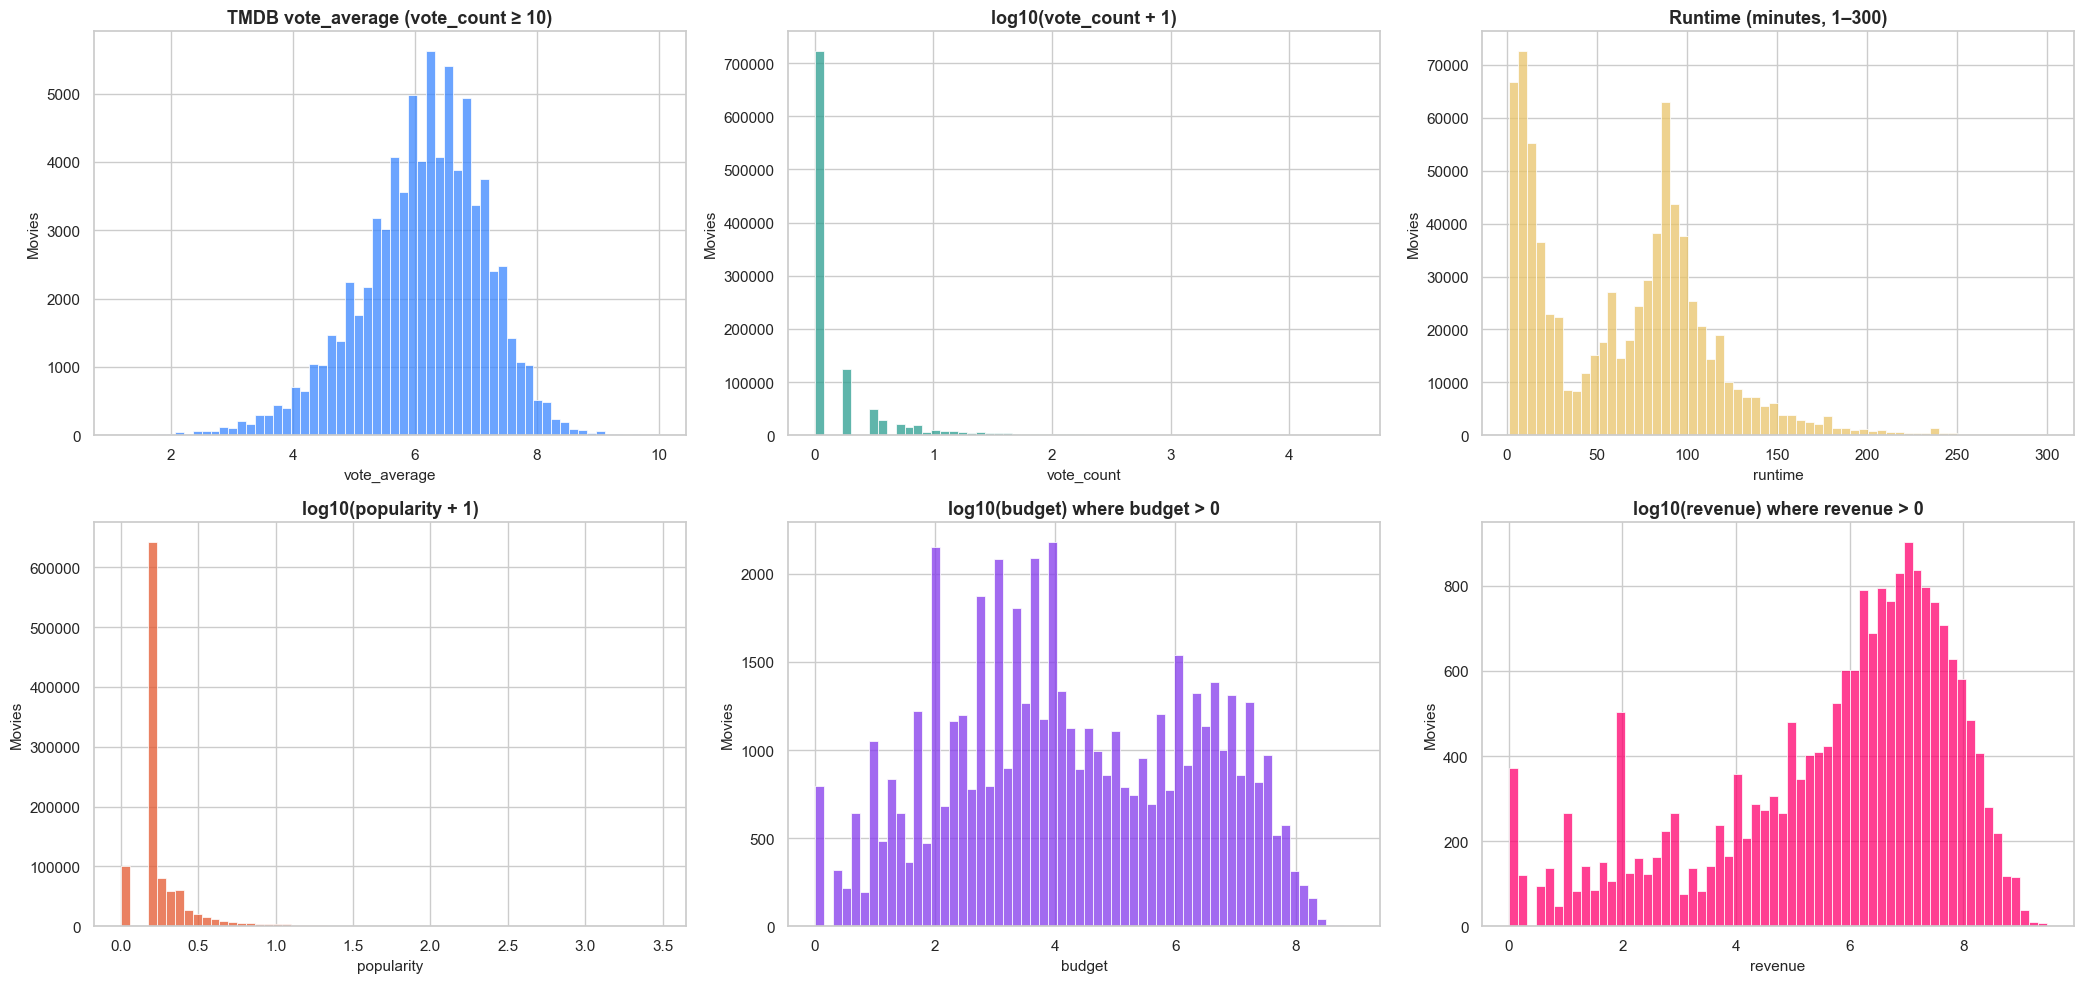

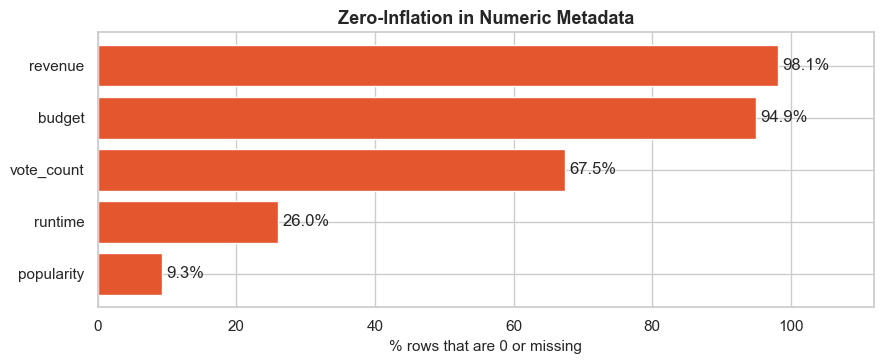

,count,mean,std,min,50%,90%,99%,max
vote_average,"1,072,255.0000",1.9796,3.0639,0.0000,0.0000,7.0000,10.0000,10.0000
vote_count,"1,072,255.0000",20.0019,327.8991,0.0000,0.0000,6.0000,230.0000,"34,495.0000"
runtime,"1,072,255.0000",49.1852,62.0445,-28.0000,26.0000,113.0000,205.0000,"14,400.0000"
popularity,"1,072,255.0000",1.2823,7.8082,0.0000,0.6000,1.8260,12.8989,"2,994.3569"
budget,"1,072,255.0000","279,732.5938","5,067,542.5000",0.0000,0.0000,0.0000,"2,500,000.0000","900,000,000.0000"
revenue,"1,072,255.0000","718,127.3125","18,083,456.0000",-12.0000,0.0000,0.0000,"1,489,547.6200","3,000,000,000.0000"


In [53]:
def vals(col, cond=None):
    s = meta[col].dropna()
    return s[cond(s)] if cond else s

specs = [
  ("vote_average", "TMDB vote_average (vote_count ≥ 10)", lambda: meta.loc[(meta.vote_count >= 10), "vote_average"].dropna(), None, "#3a86ff"),
  ("vote_count",   "log10(vote_count + 1)",               lambda: np.log10(meta["vote_count"].dropna() + 1), None, "#2a9d8f"),
  ("runtime",      "Runtime (minutes, 1–300)",            lambda: meta.loc[meta.runtime.between(1, 300), "runtime"], None, "#e9c46a"),
  ("popularity",   "log10(popularity + 1)",               lambda: np.log10(meta["popularity"].dropna() + 1), None, "#e4572e"),
  ("budget",       "log10(budget) where budget > 0",      lambda: np.log10(meta.loc[meta.budget > 0, "budget"]), None, "#8338ec"),
  ("revenue",      "log10(revenue) where revenue > 0",    lambda: np.log10(meta.loc[meta.revenue > 0, "revenue"]), None, "#ff006e")]

fig, axes = plt.subplots(2, 3, figsize=(21, 10)); axes = axes.ravel()
for ax, (col, ttl, fn, _, colr) in zip(axes, specs):
    if col in meta and meta[col].notna().any():
        v = fn()
        if len(v): sns.histplot(v, bins=60, color=colr, ax=ax)
        ax.set_title(ttl); ax.set_xlabel(col); ax.set_ylabel("Movies")
    else:
        ax.text(.5, .5, f"'{col}' not available in this file", ha="center", va="center"); ax.axis("off")
plt.tight_layout(); plt.show()

zero_tbl = pd.Series({c: ((meta[c] == 0) | meta[c].isna()).mean() * 100 for c in ["budget", "revenue", "runtime", "vote_count", "popularity"] if meta[c].notna().any()}).sort_values(ascending=False)
plt.figure(figsize=(9, 3.8)); b = plt.barh(zero_tbl.index[::-1], zero_tbl.values[::-1], color="#e4572e")
plt.bar_label(b, fmt="%.1f%%", padding=3); plt.xlim(0, 112); plt.xlabel("% rows that are 0 or missing"); plt.title("Zero-Inflation in Numeric Metadata")
plt.tight_layout(); plt.show()
display(meta[["vote_average", "vote_count", "runtime", "popularity", "budget", "revenue"]].describe(percentiles=[.5, .9, .99]).T)
KPI.update(budget_zero_or_missing_pct=round(float(zero_tbl.get("budget", np.nan)), 1), votecount_zero_pct=round(float(zero_tbl.get("vote_count", np.nan)), 1))

### 📌 Observation
- Zero-inflation is severe: **revenue is 0/missing for 98.1%, budget for 94.9%, `vote_count` for 67.5%**, runtime for 26.0% and popularity for 9.3% of the 1.07M rows (so `vote_average` has a median of 0 in the describe table).
- **Invalid values exist:** minimum runtime is **−28** minutes, minimum revenue **−12**, and maximum runtime **14,400** minutes.
- Where data exists the shapes are clear: `vote_average` (vote_count ≥ 10) is a bell around **≈ 6.2** (range ≈ 2–9); **runtime is bimodal — a short-film peak at ≈ 5–15 min and a feature-film peak at ≈ 90–95 min**; log-budget and log-revenue are multi-modal with spikes at round values (≈ 10², 10³, 10⁴ …), suggesting placeholder entries such as `$100` or `$1`.
- `vote_count` and `popularity` are extremely skewed: most rows sit at the lowest bin and the 99th percentile of `vote_count` is only 230 (max 34,495).

### 💡 Pipeline / Engineering Decision
- `budget`, `revenue`, `runtime` equal to 0 **or negative** are converted to NaN and paired with `*_known` flags; zero is never fed to a model as a real value.
- Implausible values are clipped/flagged: `runtime` outside 1–300 min, `revenue/budget` below a plausibility threshold (e.g. < 1,000) become NaN, because the log-plot shows placeholder spikes.
- `log1p` is applied to `vote_count`, `popularity`, `budget`, `revenue`.
- `vote_average` is trusted only when **`vote_count ≥ 10`** (or Bayesian-shrunk as in Step 15); the other 67.5% of rows carry no rating information.

---
## 🔹 Step 22 — Metadata Catalogue Profile — Release Years, Languages & Genres

### ❓ Why
Profile *what* the external catalogue contains: release-year timeline, language mix and genre mix. This shows how different the 1M-title universe is from the MovieLens catalogue and what coverage to expect for non-English content.

### 💼 Business Insight
For an India-focused OTT service, language mix is a first-class business variable: Hindi, Tamil, Telugu and regional content drive subscriber acquisition. A recommender trained only on English-language data under-serves the largest segment of the audience.

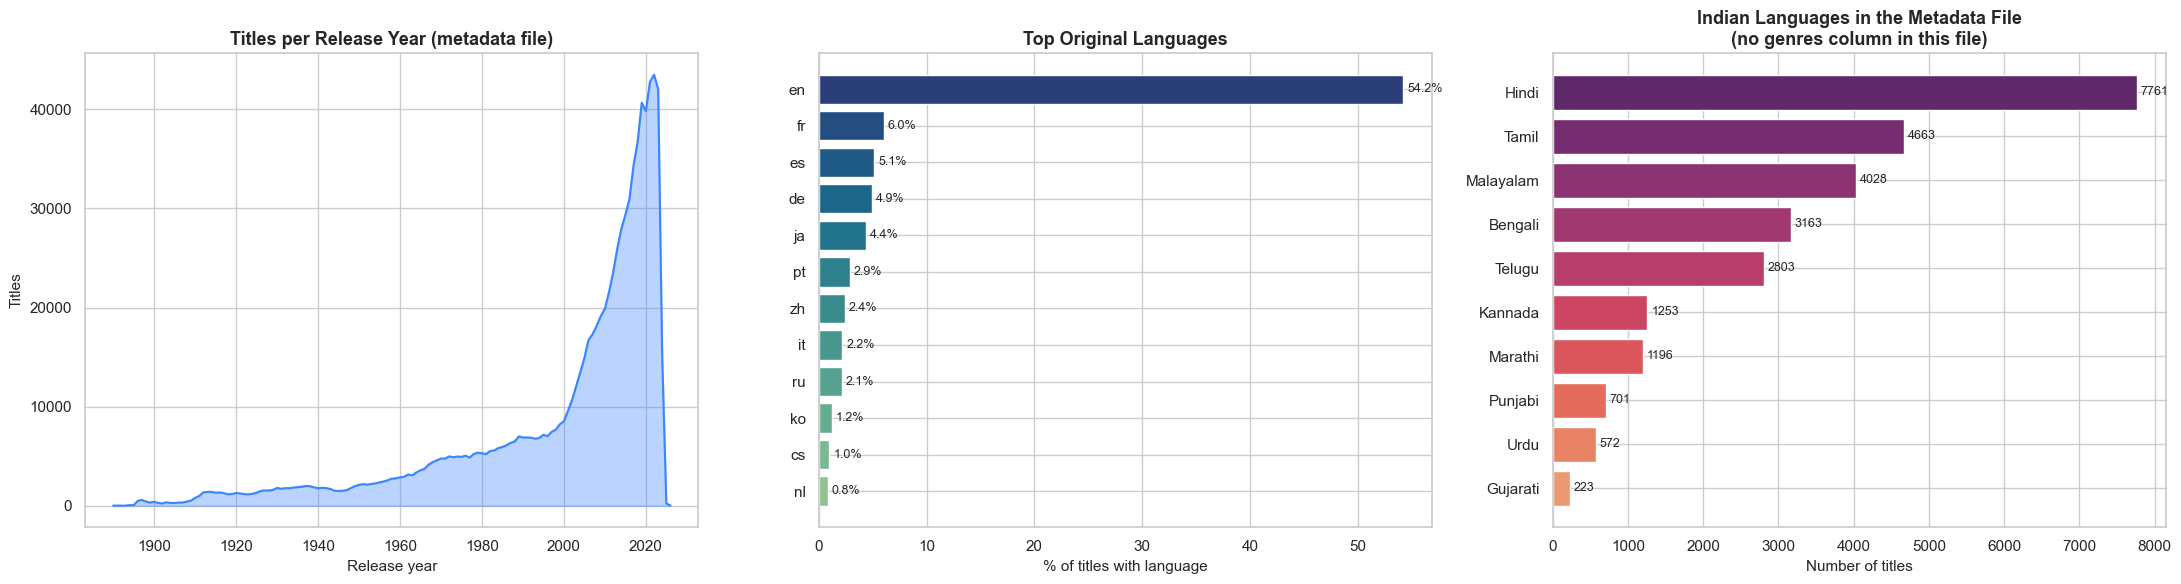

Years covered: 1890–2026 | peak year: 2022 (43,507 titles) | distinct languages: 174
English share: 54.2% | Indian-language share (hi/ta/te/ml/kn/bn/mr/pa): 2.4%


In [54]:
yr = meta["release_year"].dropna(); yr = yr[(yr >= 1890) & (yr <= 2026)]
ycnt = yr.astype(int).value_counts().sort_index()
lang = meta.loc[meta["original_language"].str.len() > 0, "original_language"].str.lower().value_counts()
lang_top = lang.head(12); lang_share = lang_top / lang.sum() * 100
gen = meta.loc[meta["genres"].str.len() > 0, "genres"].str.split("|").explode()
gen_top = gen.value_counts().head(15); gen_share = gen_top / len(meta) * 100

fig, ax = plt.subplots(1, 3, figsize=(22, 6))
ax[0].fill_between(ycnt.index, ycnt.values, alpha=.35, color="#3a86ff"); ax[0].plot(ycnt.index, ycnt.values, c="#3a86ff")
ax[0].set_xlabel("Release year"); ax[0].set_ylabel("Titles"); ax[0].set_title("Titles per Release Year (metadata file)")
b = ax[1].barh(lang_top.index[::-1], lang_share.values[::-1], color=sns.color_palette("crest", len(lang_top))); ax[1].bar_label(b, fmt="%.1f%%", padding=3, fontsize=9)
ax[1].set_xlabel("% of titles with language"); ax[1].set_title("Top Original Languages")
if len(gen_top):
    b = ax[2].barh(gen_top.index[::-1], gen_share.values[::-1], color=sns.color_palette("flare", len(gen_top))); ax[2].bar_label(b, fmt="%.1f%%", padding=3, fontsize=9)
    ax[2].set_xlabel("% of all titles"); ax[2].set_title("Top Genres (metadata file)")
else:   # this file has no usable genres column -> show the business-relevant Indian-language breakdown instead
    IND = {"hi": "Hindi", "ta": "Tamil", "te": "Telugu", "ml": "Malayalam", "kn": "Kannada", "bn": "Bengali", "mr": "Marathi", "pa": "Punjabi", "gu": "Gujarati", "ur": "Urdu"}
    ind = lang.reindex(list(IND)).fillna(0).astype(int).sort_values()
    b = ax[2].barh([IND[k] for k in ind.index], ind.values, color=sns.color_palette("flare", len(ind))); ax[2].bar_label(b, fmt="%d", padding=3, fontsize=9)
    ax[2].set_xlabel("Number of titles"); ax[2].set_title("Indian Languages in the Metadata File\n(no genres column in this file)")
plt.tight_layout(); plt.show()

hi_share = float(lang.reindex(["hi", "ta", "te", "ml", "kn", "bn", "mr", "pa"]).fillna(0).sum() / lang.sum() * 100)
print(f"Years covered: {int(yr.min())}–{int(yr.max())} | peak year: {int(ycnt.idxmax())} ({ycnt.max():,} titles) | distinct languages: {lang.shape[0]}")
print(f"English share: {lang.get('en', 0)/lang.sum():.1%} | Indian-language share (hi/ta/te/ml/kn/bn/mr/pa): {hi_share:.1f}%")
KPI.update(english_share_pct=round(float(lang.get("en", 0) / lang.sum() * 100), 1), indian_lang_share_pct=round(hi_share, 1))

### 📌 Observation
- The title-per-year curve is flat until ~1990 and then explodes to a **peak of 43,507 titles in 2022**, followed by a sharp drop (snapshot effect). The file covers **1890–2026** and **174 original languages**.
- **English is 54.2%** of titles, then French 6.0%, Spanish 5.1%, German 4.9%, Japanese 4.4%, Portuguese 2.9%, Chinese 2.4%, Italian 2.2%, Russian 2.1%, Korean 1.2%; no Indian language reaches the top 12 and **the eight main Indian languages together are only 2.4%**.
- Third panel (no `genres` column in this file, so it shows Indian languages instead): **Hindi 7,761, Tamil 4,663, Malayalam 4,028, Bengali 3,163, Telugu 2,803, Kannada 1,253, Marathi 1,196, Punjabi 701, Urdu 572, Gujarati 223** titles. Hindi is the largest at only ≈ 0.7% of the file, and Malayalam and Bengali have more titles than Telugu.

### 💡 Pipeline / Engineering Decision
- **Fix applied and verified in this cell:** because the file has no `genres` column, the empty genre panel was replaced by the Indian-language breakdown; genre features come from MovieLens (and MovieGenre), not from this file.
- `original_language` is kept as a categorical feature (top-N languages + "other") and as a **filter/diversity dimension** in the re-ranker, so language can be balanced in recommendation lists.
- With 25.6K Indian-language titles out of 1.07M (2.4%), and Hindi at only 7,761 titles, a recommender trained on this data would under-serve an India-focused product; regional catalogue data from an additional source is added to the project's open items (Step 32).
- `release_year` is restricted to 1890 – current year in cleaning, so the post-2022 drop and bad dates do not distort time features.

---
## 🔹 Step 23 — Join Coverage — MovieLens ↔ Metadata (by TMDB id, fallback IMDB id)

### ❓ Why
Joining two large sources is only valuable if the match rate is high where it matters. We measure the match rate by catalogue count, by interaction mass and by popularity bucket, and inspect the most-rated movies that failed to match.

### 💼 Business Insight
Match rate on *popular* titles is what the business feels: if blockbusters fail to join, the content features are missing exactly where traffic is highest. Failures on obscure titles are tolerable; failures on the top-1000 are a pipeline bug.

,% of catalogue,% of rating mass
match via tmdbId,98.6303,99.7879
match via imdbId,99.0757,99.8281
match via either (final),99.2391,99.8990


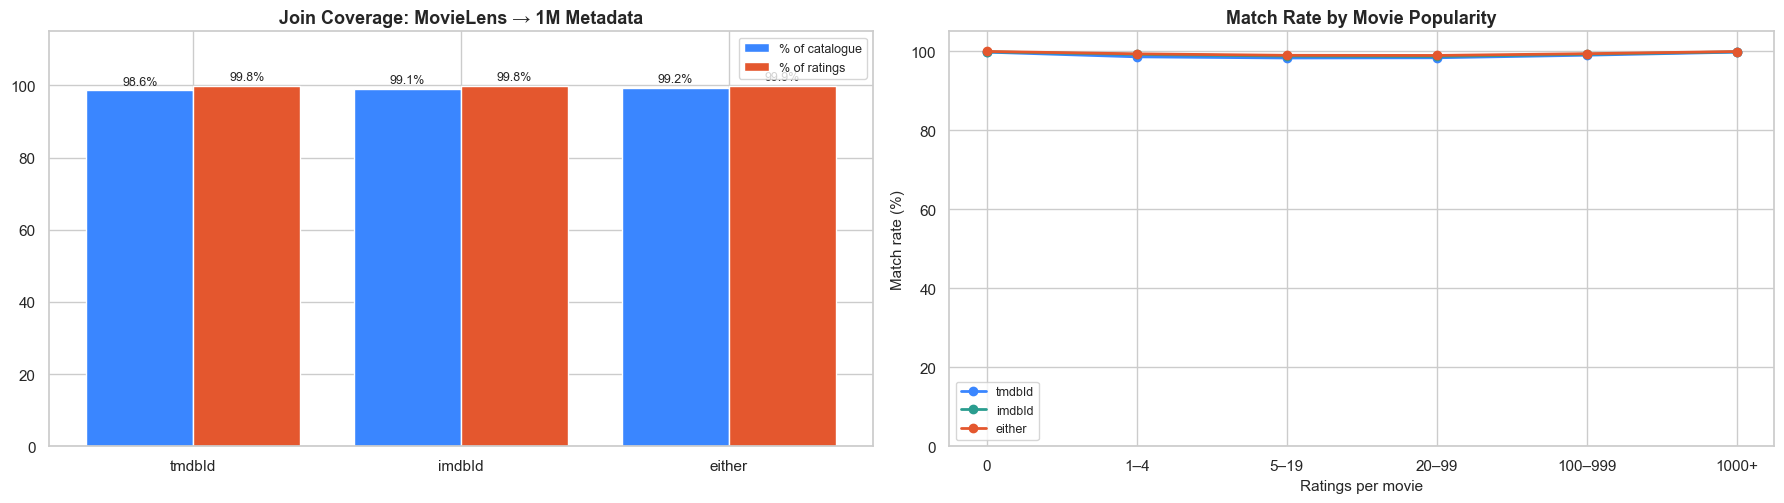

Unmatched titles: 475 | most-rated unmatched movies:


,movieId,n_ratings,title
0,7669,2585,Pride and Prejudice (1995)
1,159817,1747,Planet Earth (2006)
2,170705,1356,Band of Brothers (2001)
3,171011,1124,Planet Earth II (2016)
4,131724,891,The Jinx: The Life and Deaths of Robert Durst ...
5,142115,564,The Blue Planet (2001)
6,2851,558,Saturn 3 (1980)
7,163809,546,Over the Garden Wall (2013)


In [55]:
meta_tmdb = np.unique(meta["tmdb_id"].dropna().astype("int64").values)
meta_imdb = np.unique(meta["imdb_num"].dropna().astype("int64").values)
cov["in_meta_tmdb"] = np.isin(cov["tmdbId_i"].values, meta_tmdb) & (cov["tmdbId_i"].values > 0)
cov["in_meta_imdb"] = np.isin(cov["imdbId_i"].values, meta_imdb) & (cov["imdbId_i"].values > 0)
cov["in_meta_any"]  = cov["in_meta_tmdb"] | cov["in_meta_imdb"]

w = cov["n_ratings"]
tab = pd.DataFrame({k: [cov[k].mean() * 100, w[cov[k]].sum() / w.sum() * 100] for k in ["in_meta_tmdb", "in_meta_imdb", "in_meta_any"]},
                   index=["% of catalogue", "% of rating mass"]).T
tab.index = ["match via tmdbId", "match via imdbId", "match via either (final)"]
display(tab)

pb = pd.cut(cov["n_ratings"], [-1, 0, 4, 19, 99, 999, np.inf], labels=["0", "1–4", "5–19", "20–99", "100–999", "1000+"])
by_pop = cov.groupby(pb, observed=True)[["in_meta_tmdb", "in_meta_imdb", "in_meta_any"]].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 5.2)); x = np.arange(len(tab)); wd = .4
b1 = ax[0].bar(x - wd / 2, tab["% of catalogue"], wd, color="#3a86ff", label="% of catalogue"); b2 = ax[0].bar(x + wd / 2, tab["% of rating mass"], wd, color="#e4572e", label="% of ratings")
ax[0].bar_label(b1, fmt="%.1f%%", padding=2, fontsize=9); ax[0].bar_label(b2, fmt="%.1f%%", padding=2, fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(["tmdbId", "imdbId", "either"]); ax[0].set_ylim(0, 115); ax[0].set_title("Join Coverage: MovieLens → 1M Metadata"); ax[0].legend()
for c, lbl, col in [("in_meta_tmdb", "tmdbId", "#3a86ff"), ("in_meta_imdb", "imdbId", "#2a9d8f"), ("in_meta_any", "either", "#e4572e")]:
    ax[1].plot(by_pop.index.astype(str), by_pop[c], "o-", label=lbl, color=col, lw=2)
ax[1].set_ylim(0, 105); ax[1].set_xlabel("Ratings per movie"); ax[1].set_ylabel("Match rate (%)"); ax[1].set_title("Match Rate by Movie Popularity"); ax[1].legend()
plt.tight_layout(); plt.show()

miss_top = cov.loc[~cov.in_meta_any].nlargest(8, "n_ratings")[["movieId", "n_ratings"]].merge(movies[["movieId", "title"]], on="movieId")
print(f"Unmatched titles: {(~cov.in_meta_any).sum():,} | most-rated unmatched movies:"); display(miss_top)
KPI.update(join_any_catalog_pct=round(float(tab.iloc[2, 0]), 1), join_any_ratingmass_pct=round(float(tab.iloc[2, 1]), 1))

### 📌 Observation
- Match rate: **tmdbId 98.63% of titles / 99.79% of rating mass, imdbId 99.08% / 99.83%, either key 99.24% / 99.90%** (475 titles remain unmatched).
- The right chart is almost flat at **≈ 99–100% in every popularity bucket** — unlike in most joins, popular titles are not better matched than rare ones.
- The most-rated unmatched titles are mostly **TV series / documentaries stored in the movie catalogue**: *Pride and Prejudice (1995)* (2,585 ratings), *Planet Earth* (1,747), *Band of Brothers* (1,356), *Planet Earth II* (1,124), *The Jinx* (891), *The Blue Planet* (564).

### 💡 Pipeline / Engineering Decision
- Two-stage join (**`tmdbId` → fallback `imdbId`**) is the final design: the second key adds ≈ 0.6 pts of coverage.
- The unmatched TV titles are given `content_type = series/unknown` and routed to the genome + genre path instead of dropping them; a **manual-review table of the top unmatched titles** is part of the data-quality report.
- Match rate per popularity bucket becomes a monitored KPI (alert if it drops below ≈ 99%).

---
## 🔹 Step 24 — Cross-Source Consistency — MovieLens vs TMDB / IMDB Ratings & Years

### ❓ Why
Two independent audiences (MovieLens users vs TMDB/IMDB users) rate the same films. Their agreement shows whether external vote scores can be used as a *prior* for movies with few MovieLens ratings, and release-year agreement validates that the join is linking the *right* movies.

### 💼 Business Insight
For a brand-new title with no platform ratings, an external critic/audience score is the only quality signal available. Knowing its correlation with our own users' ratings tells us how much to trust it for launch-day ranking.

Joined movie rows: 61,948  (catalogue 62,423)


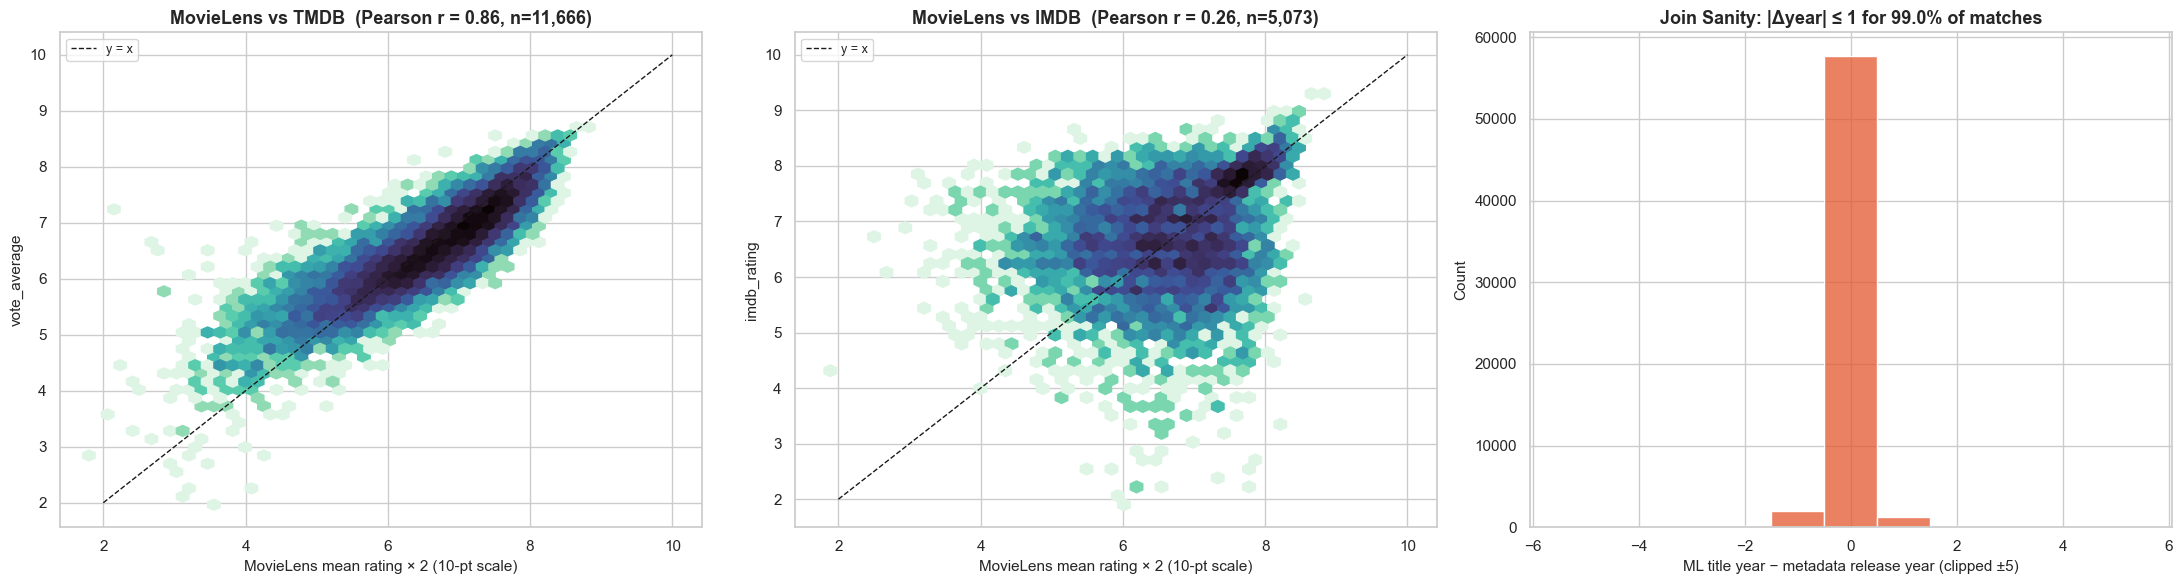

In [56]:
cov["mean_rating"] = item["mean"].reindex(movies["movieId"]).values
cov["rating_std"]  = item["std"].reindex(movies["movieId"]).values
cov["year"] = movies["year"].values

mt = meta.dropna(subset=["tmdb_id"]).drop_duplicates("tmdb_id").assign(_k=lambda d: d["tmdb_id"].astype("int64"))
mi = meta.dropna(subset=["imdb_num"]).drop_duplicates("imdb_num").assign(_k=lambda d: d["imdb_num"].astype("int64"))
j1 = cov[cov.in_meta_tmdb].merge(mt.drop(columns=["tmdb_id"]), left_on="tmdbId_i", right_on="_k", how="left")
j2 = cov[~cov.in_meta_tmdb & cov.in_meta_imdb].merge(mi.drop(columns=["imdb_num"]), left_on="imdbId_i", right_on="_k", how="left")
joined = pd.concat([j1, j2], ignore_index=True)
print(f"Joined movie rows: {len(joined):,}  (catalogue {len(cov):,})")

good = joined[(joined.n_ratings >= 50)]
has_va = "vote_average" in good and (good["vote_average"] > 0).any()
has_im = "imdb_rating" in good and (good["imdb_rating"] > 0).any()
fig, ax = plt.subplots(1, 3, figsize=(22, 6))

def agree(a, col, title):
    d = good[(good[col] > 0)].dropna(subset=["mean_rating"])
    if col == "vote_average" and "vote_count" in d: d = d[d.vote_count >= 50]
    if len(d) < 10: a.text(.5, .5, "insufficient overlap", ha="center"); a.axis("off"); return None
    hb = a.hexbin(d["mean_rating"] * 2, d[col], gridsize=40, bins="log", cmap="mako_r", mincnt=1)
    a.plot([2, 10], [2, 10], "k--", lw=1, label="y = x")
    r = np.corrcoef(d["mean_rating"], d[col])[0, 1]
    a.set_xlabel("MovieLens mean rating × 2 (10-pt scale)"); a.set_ylabel(col); a.set_title(f"{title}  (Pearson r = {r:.2f}, n={len(d):,})"); a.legend(); return r

r_tmdb = agree(ax[0], "vote_average", "MovieLens vs TMDB") if has_va else (ax[0].text(.5, .5, "vote_average not available", ha="center"), ax[0].axis("off"))[0]
r_imdb = agree(ax[1], "imdb_rating", "MovieLens vs IMDB") if has_im else (ax[1].text(.5, .5, "imdb_rating not available", ha="center"), ax[1].axis("off"))[0]

dy = (joined["year"] - joined["release_year"]).dropna()
within1 = float((dy.abs() <= 1).mean() * 100) if len(dy) else np.nan
if len(dy):
    sns.histplot(dy.clip(-5, 5), bins=np.arange(-5.5, 6.5, 1), color="#e4572e", ax=ax[2]); ax[2].set_xlabel("ML title year − metadata release year (clipped ±5)")
    ax[2].set_title(f"Join Sanity: |Δyear| ≤ 1 for {within1:.1f}% of matches")
plt.tight_layout(); plt.show()
KPI.update(corr_ml_vs_tmdb=None if r_tmdb is None else round(float(r_tmdb), 3), corr_ml_vs_imdb=None if r_imdb is None else round(float(r_imdb), 3), join_year_agreement_pct=round(within1, 1))

### 📌 Observation
- **MovieLens vs TMDB `vote_average`: Pearson r = 0.86 (n = 11,666)** — a tight diagonal cloud, slightly below y = x.
- **MovieLens vs `IMDB_Rating`: r = 0.26 (n = 5,073)** — a broad, shapeless cloud (an `IMDB_Rating` of 4–9 for the same MovieLens score), which together with 97.2% missing values (Step 20) shows this column is unreliable in this file.
- Join sanity: **99.0% of matches have |ML year − release year| ≤ 1**, with the bulk at exactly 0; 61,948 of 62,423 movies were joined.

### 💡 Pipeline / Engineering Decision
- **TMDB `vote_average` (with `vote_count ≥ 50`) is the single external quality prior** for cold-start items; `IMDB_Rating` from this file is dropped from the feature list.
- The external score is used as a prior (shrink the MovieLens mean toward `vote_average / 2` for low-count items) after standardisation (rank or z-score), since the scales are correlated but not calibrated.
- Join validation rule: `|year_ML − year_meta| ≤ 1` — the ≈ 1% violating rows are flagged as suspect links and excluded from content features.

---
## 🔹 Step 25 — Content Richness for the Content-Based Branch

### ❓ Why
A content-based recommender is only as good as the text and credits available per title. We measure the completeness of overview, keywords, cast, director, tagline and poster among MovieLens-matched titles, and the overview-length distribution (a proxy for text-embedding quality).

### 💼 Business Insight
Titles with a rich synopsis, cast and keywords produce reliable semantic embeddings; titles with an empty overview produce noise. This tells the business which parts of the catalogue are "explainable" and where metadata enrichment (e.g. editorial or LLM-generated synopses) has the highest ROI.

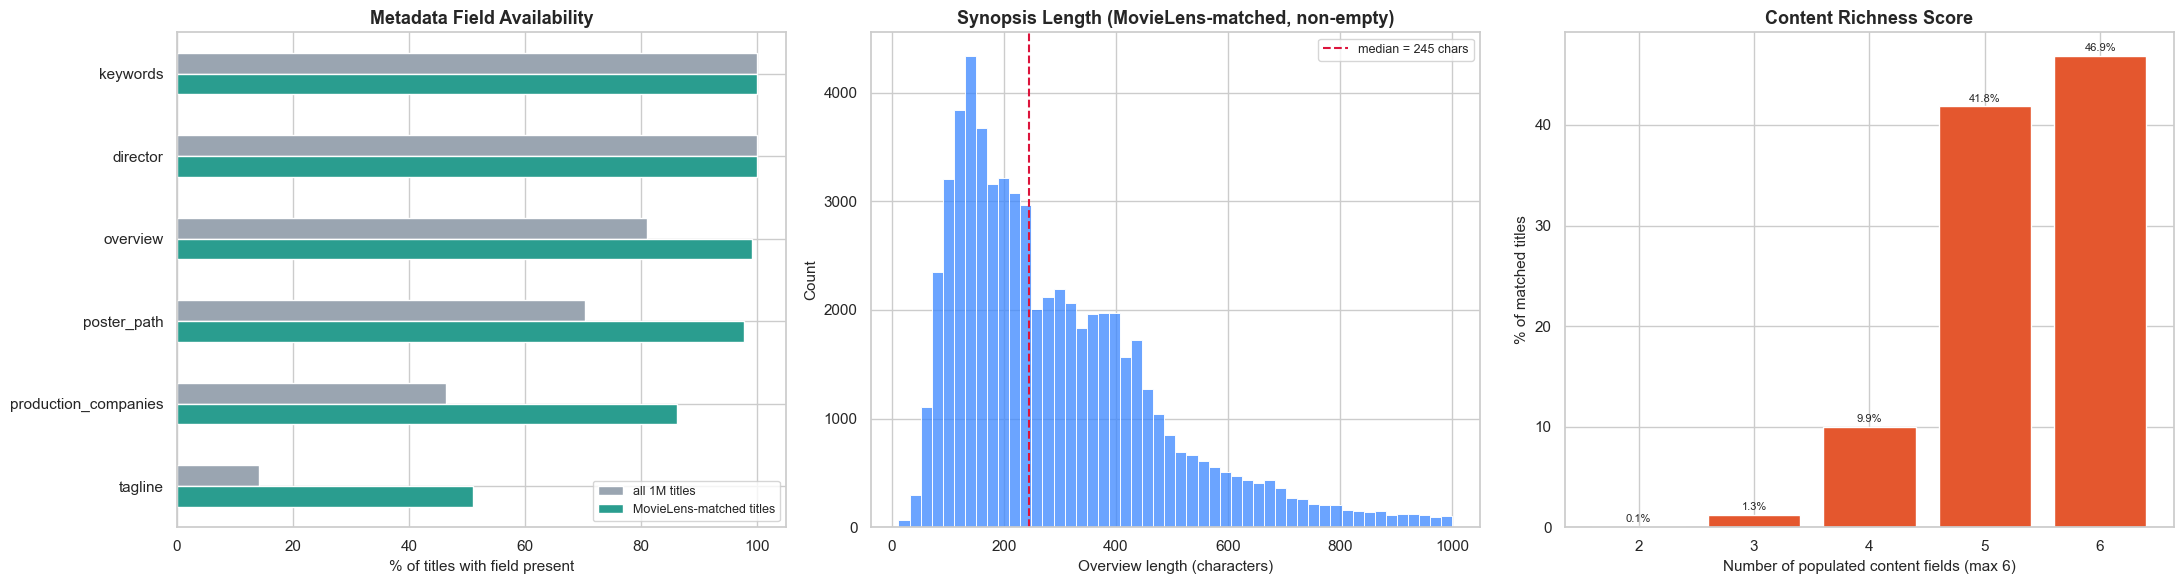

,all 1M titles,MovieLens-matched titles
keywords,100.0000,100.0000
director,100.0000,100.0000
overview,81.0499,99.2058
poster_path,70.3580,97.6900
production_companies,46.3110,86.1884
tagline,14.2488,51.0573


Median overview length: 245 chars | share of matched titles with ≥ 6 populated fields: 46.9%


In [57]:
fields = ["overview", "tagline", "keywords", "cast", "director", "production_companies", "poster_path", "genres"]
fields = [f for f in fields if RES.get(f)]
allc = pd.Series({f: meta[f"has_{f}"].mean() * 100 for f in fields})
matc = pd.Series({f: joined[f"has_{f}"].mean() * 100 for f in fields if f"has_{f}" in joined}) if len(joined) else allc * np.nan
tab = pd.DataFrame({"all 1M titles": allc, "MovieLens-matched titles": matc}).sort_values("MovieLens-matched titles", ascending=False)

joined["richness"] = joined[[f"has_{f}" for f in fields]].sum(axis=1) if len(joined) else 0
ovl = joined.loc[joined["overview_len"] > 0, "overview_len"].clip(upper=1500)

fig, ax = plt.subplots(1, 3, figsize=(22, 6))
tab.plot(kind="barh", ax=ax[0], color=["#9aa5b1", "#2a9d8f"]); ax[0].set_xlabel("% of titles with field present"); ax[0].set_xlim(0, 105)
ax[0].set_title("Metadata Field Availability"); ax[0].invert_yaxis()
sns.histplot(ovl, bins=50, color="#3a86ff", ax=ax[1]); ax[1].axvline(ovl.median(), c="crimson", ls="--", label=f"median = {ovl.median():.0f} chars")
ax[1].set_xlabel("Overview length (characters)"); ax[1].set_title("Synopsis Length (MovieLens-matched, non-empty)"); ax[1].legend()
rc = joined["richness"].value_counts().sort_index()
b = ax[2].bar(rc.index.astype(int), rc.values / rc.sum() * 100, color="#e4572e"); ax[2].bar_label(b, fmt="%.1f%%", padding=2, fontsize=8)
ax[2].set_xlabel(f"Number of populated content fields (max {len(fields)})"); ax[2].set_ylabel("% of matched titles"); ax[2].set_title("Content Richness Score")
plt.tight_layout(); plt.show()

display(tab)
print(f"Median overview length: {ovl.median():.0f} chars | share of matched titles with ≥ 6 populated fields: {(joined['richness']>=6).mean():.1%}")
KPI["matched_overview_pct"] = round(float(matc.get("overview", np.nan)), 1)

### 📌 Observation
- Compared with the whole 1M file, the MovieLens-matched titles are much better documented: **overview 99.2% vs 81.0%, poster path 97.7% vs 70.4%, production companies 86.2% vs 46.3%, tagline 51.1% vs 14.2%**.
- `keywords` and `director` show **100% in both groups**, which — together with Step 20 — points to placeholder values and means they are not informative until verified.
- Synopsis length has a median of **245 characters** with a main mode at ≈ 140 chars, a second shoulder at ≈ 380 and a tail past 1,000.
- Richness score (max 6 here because `genres` and `cast` are absent): **46.9% of matched titles have all 6 fields, 41.8% have 5, 9.9% have 4**, only 1.4% have ≤ 3.

### 💡 Pipeline / Engineering Decision
- The text-embedding branch (SBERT `all-MiniLM-L6-v2`) is built on `overview + tagline` (and keywords only after the placeholder check); `has_overview` gates the branch, and titles with an empty overview fall back to genome/genre vectors.
- `richness` (computed only from fields that are verified non-placeholder) is stored as a feature and as a monitoring KPI.
- With a 245-char median overview, a sentence-embedding model (max 128–256 tokens) is sufficient — no long-document model is needed.

---
## 🔹 Step 26 — IMDB 50K Movie Reviews — Sentiment Balance, Length & Vocabulary

### ❓ Why
The review dataset provides labelled text (positive / negative) for building a sentiment model. We check class balance, duplicates, text cleanliness (HTML artefacts), review length and the most discriminative words, and confirm whether it can be joined to movies at all.

### 💼 Business Insight
Review sentiment is a strong "quality" signal that complements numeric ratings and can power review-summary and "why recommended" features. But sentiment trained on the wrong data (or leaked duplicates) gives inflated accuracy and misleading product claims.

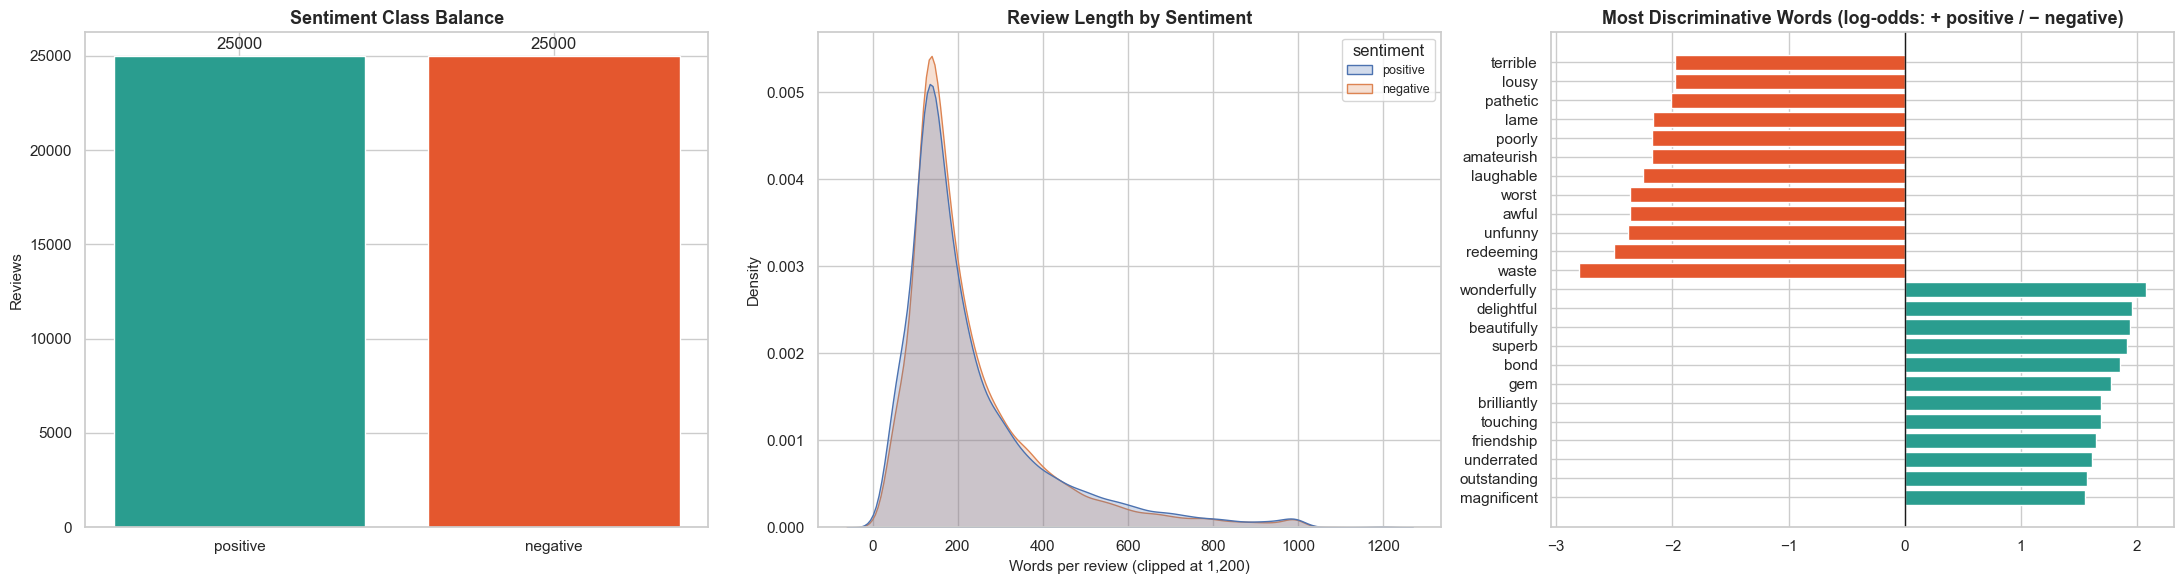

Reviews: 50,000 | columns: ['review', 'sentiment'] | duplicates: 418 | with HTML tags: 58.4%
Words/review: mean=231, median=173, p99=908
⚠️  Join key to movies: NONE (dataset has only review text + sentiment) → cannot be linked to movieId.


In [58]:
from sklearn.feature_extraction.text import CountVectorizer
rv = read_any(locate("imdb dataset"))
rcol = next(c for c in rv.columns if c.lower() == "review"); scol = next(c for c in rv.columns if c.lower() == "sentiment")
rv["n_words"] = rv[rcol].str.split().str.len()
rv["has_html"] = rv[rcol].str.contains(r"<[^>]+>", regex=True)
dups = int(rv.duplicated(subset=[rcol]).sum())
bal = rv[scol].value_counts()

smp = rv.sample(min(len(rv), 20_000), random_state=SEED)
cv = CountVectorizer(stop_words="english", min_df=150, max_features=20_000, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
X = cv.fit_transform(smp[rcol].str.replace(r"<[^>]+>", " ", regex=True).str.lower())
pos_mask = (smp[scol].astype(str).str.lower() == "positive").values
cp, cn = np.asarray(X[pos_mask].sum(0)).ravel() + 1, np.asarray(X[~pos_mask].sum(0)).ravel() + 1
logodds = np.log(cp / cp.sum()) - np.log(cn / cn.sum()); vocab = np.array(cv.get_feature_names_out())
top_pos, top_neg = np.argsort(-logodds)[:12], np.argsort(logodds)[:12]

fig, ax = plt.subplots(1, 3, figsize=(22, 6))
b = ax[0].bar(bal.index.astype(str), bal.values, color=["#2a9d8f", "#e4572e"]); ax[0].bar_label(b, fmt="%d", padding=3); ax[0].set_title("Sentiment Class Balance"); ax[0].set_ylabel("Reviews")
sns.kdeplot(data=rv.assign(w=rv.n_words.clip(upper=1200)), x="w", hue=scol, fill=True, common_norm=False, ax=ax[1])
ax[1].set_xlabel("Words per review (clipped at 1,200)"); ax[1].set_title("Review Length by Sentiment")
ax[2].barh(list(vocab[top_pos])[::-1] + list(vocab[top_neg]), list(logodds[top_pos])[::-1] + list(logodds[top_neg]),
           color=["#2a9d8f"] * 12 + ["#e4572e"] * 12)
ax[2].set_title("Most Discriminative Words (log-odds: + positive / − negative)"); ax[2].axvline(0, c="k", lw=1)
plt.tight_layout(); plt.show()

print(f"Reviews: {len(rv):,} | columns: {list(rv.columns[:2])} | duplicates: {dups:,} | with HTML tags: {rv.has_html.mean():.1%}")
print(f"Words/review: mean={rv.n_words.mean():.0f}, median={rv.n_words.median():.0f}, p99={rv.n_words.quantile(.99):.0f}")
print("⚠️  Join key to movies: NONE (dataset has only review text + sentiment) → cannot be linked to movieId.")
KPI.update(review_rows=len(rv), review_duplicates=dups, review_balance=dict(bal))

### 📌 Observation
- The 50,000 reviews are perfectly balanced (**25,000 positive / 25,000 negative**), and the two length distributions overlap almost completely: both peak at ≈ 130–150 words, **mean 231, median 173, p99 908**, with a small secondary bump near ≈ 1,000 words — review length carries no label signal.
- **418 reviews are exact duplicates**, **58.4% contain HTML tags**, and the file has only `review` and `sentiment` columns, so it has **no movie key** and cannot be joined to MovieLens.
- After raising the vocabulary filter (`min_df = 150`) the log-odds chart now shows real sentiment words. Negative side: ***waste, redeeming, unfunny, awful, worst, laughable, amateurish, poorly, lame, pathetic, lousy, terrible*** (log-odds down to ≈ −2.8). Positive side: ***wonderfully, delightful, beautifully, superb, bond, gem, brilliantly, touching, friendship, underrated, outstanding, magnificent*** (up to ≈ +2.1).
- The positive list also contains topic words (*bond, friendship*), and the negative side is slightly stronger in magnitude than the positive side (≈ −2.8 vs ≈ +2.1).

### 💡 Pipeline / Engineering Decision
- **Fix applied and verified in this cell:** `min_df` was raised from 5 to 150, which replaced rare proper nouns (*uwe, caligula, gypo …*) by generalisable sentiment words — the vocabulary filter stays at `min_df ≥ 150` (≈ 0.75% of documents) in the sentiment pipeline.
- Reviews are cleaned (HTML stripped, lower-cased) and **de-duplicated before the train/test split**, so the 418 duplicates cannot leak across splits; accuracy is a valid metric because the classes are exactly balanced.
- Because length is uninformative and the top discriminative words are clean sentiment terms, a **TF-IDF + Logistic Regression baseline** is built first, then a DistilBERT fine-tune for the accuracy gain; topic words (*bond, friendship*) are a reminder to test on held-out movies/years when possible.
- The trained model is used **inference-only** on other review text to produce a `review_sentiment` feature; this dataset itself is never joined to movies.

---
## 🔹 Step 27 — MovieGenre (Poster Dataset) — Multi-Label Genres, IMDB Score & Join Coverage

### ❓ Why
This table links poster images to genres and IMDB scores. We profile its genre labels (multi-label), score distribution and how well it joins to MovieLens through `imdbId`.

### 💼 Business Insight
Posters are what the user actually sees on an OTT home screen. A model that predicts genre/appeal from a poster enables visual cold-start recommendation and automated thumbnail QA — but only for titles that have posters.

Resolved: {'id': 'imdbId', 'title': 'Title', 'score': 'IMDB Score', 'genre': 'Genre', 'poster': 'Poster'} | shape: (40108, 6)


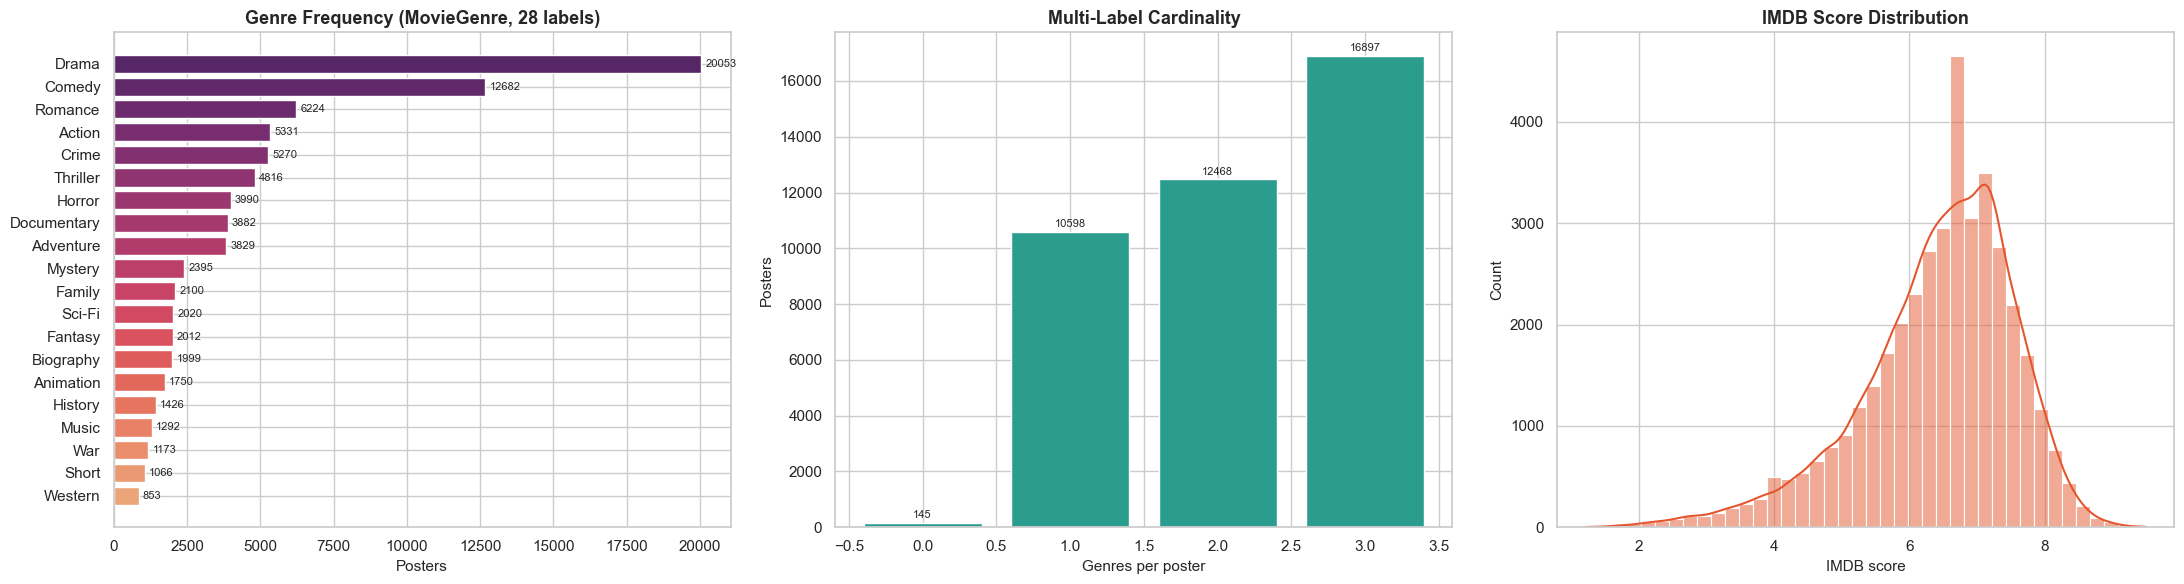

Rows: 40,108 | duplicate imdbId: 593 | null score: 0.1% | null genre: 0.4%
Joinable to MovieLens via imdbId: 93.3% | avg genres/poster: 2.15 | median year: 2000.0


In [59]:
mg = read_any(locate("moviegenre"))
lowc = {c.lower().strip(): c for c in mg.columns}
def pick(*keys):
    for k in keys:
        for lc, c in lowc.items():
            if k in lc: return c
    return None
c_id, c_title, c_score, c_genre, c_post = pick("imdbid"), pick("title"), pick("score", "rating"), pick("genre"), pick("poster")
print("Resolved:", dict(id=c_id, title=c_title, score=c_score, genre=c_genre, poster=c_post), "| shape:", mg.shape)

mg["_id"] = pd.to_numeric(mg[c_id], errors="coerce")
mg["_score"] = pd.to_numeric(mg[c_score], errors="coerce") if c_score else np.nan
mg["_genres"] = mg[c_genre].fillna("").astype(str).map(lambda s: [g.strip() for g in re.split(r"[|,]", s) if g.strip()])
mg["_ng"] = mg["_genres"].str.len()
gcount = mg["_genres"].explode().value_counts()
mg["_year"] = pd.to_numeric(mg[c_title].astype(str).str.extract(r"\((\d{4})\)")[0], errors="coerce") if c_title else np.nan

mg_in_links = mg["_id"].isin(cov.loc[cov.imdbId_i > 0, "imdbId_i"]).mean() * 100
cov["in_moviegenre"] = cov["imdbId_i"].isin(mg["_id"].dropna().astype("int64"))
dup_mg = int(mg["_id"].duplicated().sum())

fig, ax = plt.subplots(1, 3, figsize=(22, 6))
tg = gcount.head(20); b = ax[0].barh(tg.index[::-1], tg.values[::-1], color=sns.color_palette("flare", len(tg))); ax[0].bar_label(b, padding=3, fontsize=8)
ax[0].set_title(f"Genre Frequency (MovieGenre, {len(gcount)} labels)"); ax[0].set_xlabel("Posters")
nc = mg["_ng"].value_counts().sort_index(); b = ax[1].bar(nc.index.astype(int), nc.values, color="#2a9d8f"); ax[1].bar_label(b, padding=2, fontsize=8)
ax[1].set_xlabel("Genres per poster"); ax[1].set_ylabel("Posters"); ax[1].set_title("Multi-Label Cardinality")
sns.histplot(mg["_score"].dropna(), bins=40, kde=True, color="#e4572e", ax=ax[2]); ax[2].set_xlabel("IMDB score"); ax[2].set_title("IMDB Score Distribution")
plt.tight_layout(); plt.show()

print(f"Rows: {len(mg):,} | duplicate imdbId: {dup_mg} | null score: {mg['_score'].isna().mean():.1%} | null genre: {(mg['_ng']==0).mean():.1%}")
print(f"Joinable to MovieLens via imdbId: {mg_in_links:.1f}% | avg genres/poster: {mg['_ng'].mean():.2f} | median year: {mg['_year'].median() if mg['_year'].notna().any() else 'n/a'}")
KPI.update(moviegenre_rows=len(mg), moviegenre_join_pct=round(float(mg_in_links), 1), moviegenre_labels=int(len(gcount)))

### 📌 Observation
- **40,108 rows, 28 genre labels**; **593 duplicated `imdbId`s**, 0.1% null scores, 0.4% null genres, median release year 2000. **93.3% of rows join to MovieLens via `imdbId`**.
- Strong imbalance: **Drama 20,053 posters (50% of rows)**, Comedy 12,682, Romance 6,224, Action 5,331, Crime 5,270, Thriller 4,816, Horror 3,990, Documentary 3,882 … **Western only 853**.
- Cardinality is capped at 3 labels: **1 genre — 10,598, 2 — 12,468, 3 — 16,897**, 0 — 145; nothing has more than 3. Average = 2.15 genres per poster.
- The IMDB score is left-skewed with a sharp mode at **≈ 6.8** (≈ 4,600 rows) and range ≈ 1–9.5.

### 💡 Pipeline / Engineering Decision
- The poster-genre problem is **multi-label (sigmoid + `BCEWithLogitsLoss(pos_weight = neg/pos)`)**, evaluated with macro-F1 / mAP, never accuracy — a Drama-only predictor already covers half the rows.
- Rows are **de-duplicated on `imdbId`** (593 duplicates) and joined to MovieLens through `links.imdbId`; the `in_moviegenre` flag stays in `cov`.
- Labels are capped at 3 per title in the source, so evaluation uses per-label metrics rather than assuming complete label sets.

---
## 🔹 Step 28 — Poster Images — Key Alignment, Sample Grid & Image Quality

### ❓ Why
Before any image model, check that poster filenames map to real movies, view a sample, and measure image properties (size, aspect ratio, brightness, grayscale share). Mismatched IDs or inconsistent sizes silently break an image pipeline.

### 💼 Business Insight
Poster quality is a user-facing asset: dark, tiny or black-and-white posters reduce click-through. The same analysis doubles as an automated artwork QA report for the content-operations team.

Poster images: 997 | filename numeric: 100.0%
Filename matches links.imdbId: 99.1% | movies.movieId: 9.3% | MovieGenre.imdbId: 100.0%  →  KEY = imdbId


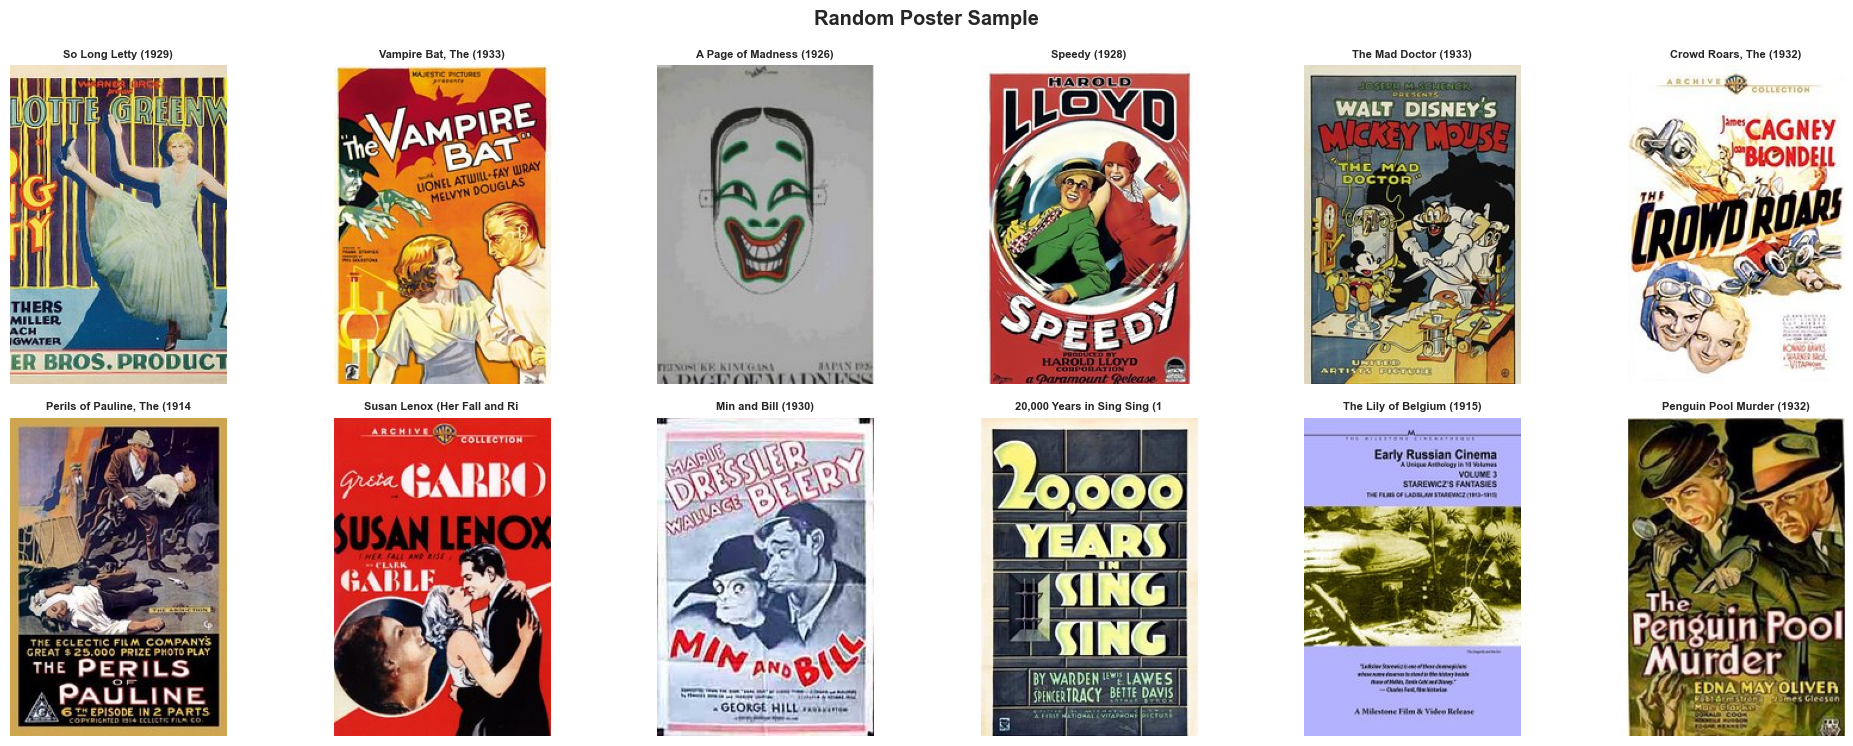

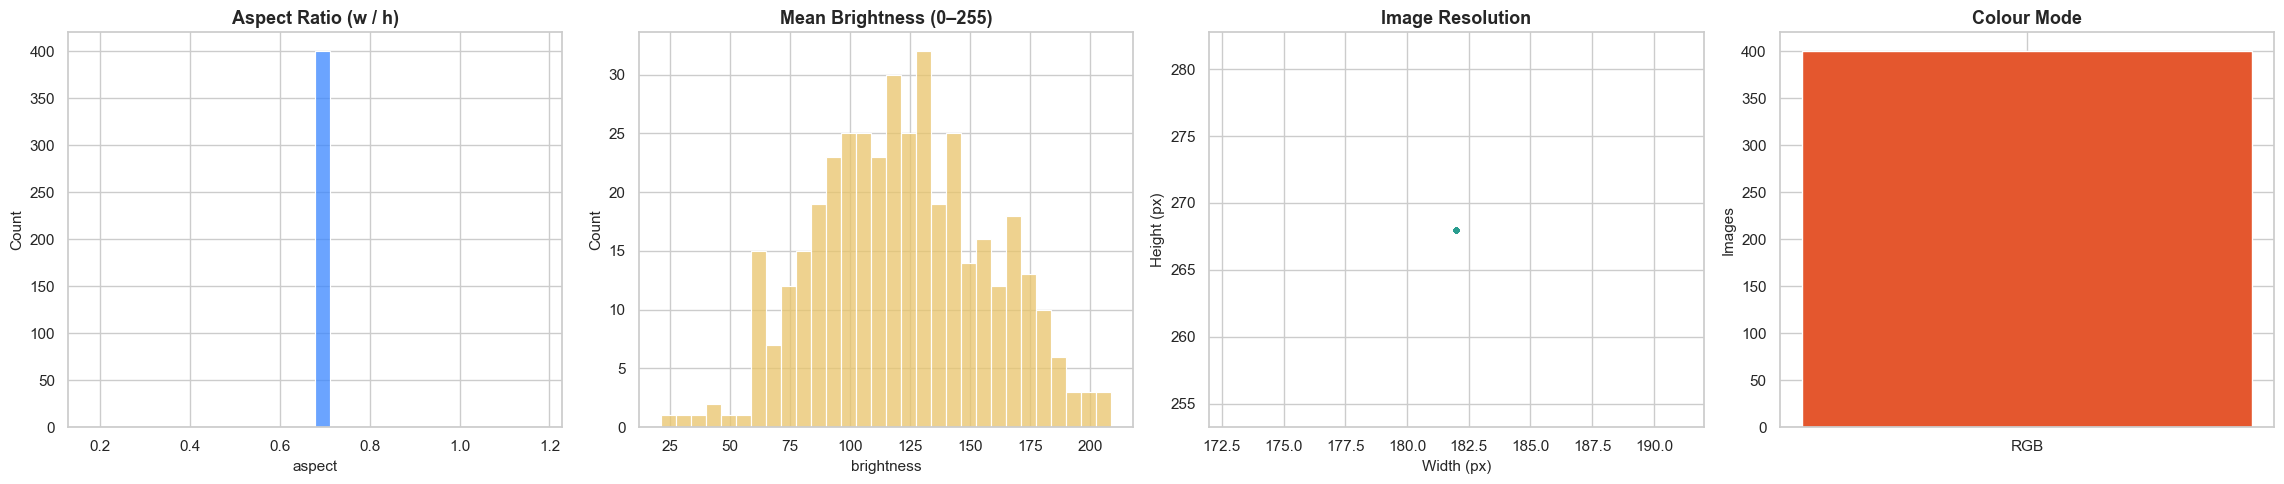

Sampled 400 images | unique sizes: 1 | median size: 182×268
Grayscale-looking posters: 7.5% | dark (< 60 brightness): 2.8% | median file size: 18 KB


In [60]:
from PIL import Image
img_files = sorted(p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)
pf = pd.DataFrame({"path": img_files, "stem": [p.stem for p in img_files]})
pf["id"] = pd.to_numeric(pf["stem"], errors="coerce")
m_imdb = pf["id"].isin(cov.loc[cov.imdbId_i > 0, "imdbId_i"]).mean() * 100
m_movie = pf["id"].isin(movies["movieId"]).mean() * 100
m_mg = pf["id"].isin(mg["_id"].dropna().astype("int64")).mean() * 100
KEY = "imdbId" if m_imdb >= m_movie else "movieId"
print(f"Poster images: {len(pf):,} | filename numeric: {pf['id'].notna().mean():.1%}")
print(f"Filename matches links.imdbId: {m_imdb:.1f}% | movies.movieId: {m_movie:.1f}% | MovieGenre.imdbId: {m_mg:.1f}%  →  KEY = {KEY}")

if KEY == "imdbId":
    cov["has_poster_file"] = cov["imdbId_i"].isin(pf["id"].dropna().astype("int64"))
    id2mid = cov.drop_duplicates("imdbId_i").set_index("imdbId_i")["movieId"]
    pf["movieId"] = pf["id"].map(id2mid)
else:
    cov["has_poster_file"] = cov["movieId"].isin(pf["id"].dropna().astype("int64")); pf["movieId"] = pf["id"]
tmap = movies.set_index("movieId")["title"]
pf["title"] = pf["movieId"].map(tmap)

# ---- sample grid
samp = pf.sample(min(12, len(pf)), random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(20, 7.6))
for a in axes.ravel(): a.axis("off")
for a, (_, r) in zip(axes.ravel(), samp.iterrows()):
    try: a.imshow(Image.open(r["path"]).convert("RGB")); a.set_title(str(r["title"])[:28], fontsize=8)
    except Exception: pass
plt.suptitle("Random Poster Sample", fontweight="bold"); plt.tight_layout(); plt.show()

# ---- image statistics on a sample
st = []
for p in pf["path"].sample(min(400, len(pf)), random_state=SEED):
    try:
        with Image.open(p) as im:
            w_, h_ = im.size; mode = im.mode
            a = np.asarray(im.convert("RGB").resize((64, 96)), dtype="float32")
        st.append({"w": w_, "h": h_, "aspect": w_ / h_, "mode": mode, "brightness": a.mean(), "gray": float(np.abs(a[..., 0] - a[..., 1]).mean() < 4 and np.abs(a[..., 1] - a[..., 2]).mean() < 4), "kb": p.stat().st_size / 1024})
    except Exception:
        pass
st = pd.DataFrame(st)
fig, ax = plt.subplots(1, 4, figsize=(23, 5))
sns.histplot(st["aspect"], bins=30, color="#3a86ff", ax=ax[0]); ax[0].set_title("Aspect Ratio (w / h)")
sns.histplot(st["brightness"], bins=30, color="#e9c46a", ax=ax[1]); ax[1].set_title("Mean Brightness (0–255)")
ax[2].scatter(st["w"], st["h"], s=10, alpha=.4, c="#2a9d8f"); ax[2].set_xlabel("Width (px)"); ax[2].set_ylabel("Height (px)"); ax[2].set_title("Image Resolution")
cm = st["mode"].value_counts(); ax[3].bar(cm.index, cm.values, color="#e4572e"); ax[3].set_title("Colour Mode"); ax[3].set_ylabel("Images")
plt.tight_layout(); plt.show()

print(f"Sampled {len(st)} images | unique sizes: {st[['w','h']].drop_duplicates().shape[0]} | median size: {int(st.w.median())}×{int(st.h.median())}")
print(f"Grayscale-looking posters: {st['gray'].mean():.1%} | dark (< 60 brightness): {(st.brightness<60).mean():.1%} | median file size: {st.kb.median():.0f} KB")
KPI.update(poster_key=KEY, poster_key_match_pct=round(max(m_imdb, m_movie), 1), poster_grayscale_pct=round(float(st["gray"].mean() * 100), 1))

### 📌 Observation
- All **997** filenames are numeric and match **`links.imdbId` for 99.1%** of files (vs only 9.3% against `movieId`, a coincidence of number ranges) and 100% of the MovieGenre ids — the poster key is `imdbId`.
- The sample grid shows exclusively **silent-era / early-sound films (≈ 1914–1933)**: text-heavy lithographs, some black-and-white, and at least one DVD box cover (*The Lily of Belgium*) instead of an original poster.
- The statistics from 400 sampled images are strikingly uniform: **every image is exactly 182 × 268 px (aspect ≈ 0.68), RGB**, median file size 18 KB. Brightness is roughly bell-shaped around ≈ 120 (range ≈ 20–210); **7.5% look grayscale and 2.8% are dark (< 60)**.

### 💡 Pipeline / Engineering Decision
- Posters are keyed on **`imdbId`** with a validation assertion (match rate ≥ 99%) before training.
- The images are already standardised low-resolution thumbnails, so the pipeline needs no aspect-ratio handling: **upscale 182×268 → 224×224 (resize or centre-crop), keep RGB, ImageNet normalisation**, no vertical flip (the posters contain text).
- A frozen **pre-trained encoder (CLIP / ResNet50 / EfficientNet)** produces poster embeddings; training from scratch is rejected because 997 low-res images from one era (1914–1933) cannot represent modern artwork.
- For catalogue-wide coverage the poster branch would have to download images from TMDB `poster_path` (available for 97.7% of matched titles) or the MovieGenre URLs; until then it is a research branch only.

---
## 🔹 Step 29 — Modality Coverage Funnel — Which Movies Have Which Signals?

### ❓ Why
This step integrates all previous coverage flags into one view: for each title, which of {ratings, tags, genome, external metadata, poster-genre record, poster image} exist. It defines the exact scope of each branch in the hybrid recommender.

### 💼 Business Insight
Product, content and engineering teams can use this single chart to see where personalisation is rich (full-stack titles), where it relies on content only, and where the catalogue is effectively "dark" with no usable signal at all.

,% of catalogue,% of rating mass
Ratings (CF signal),94.5917,100.0000
User tags,72.4909,99.6663
Tag genome,22.1329,98.6961
TMDB/IMDB metadata,99.2391,99.8990
MovieGenre record,59.0568,98.2245
Poster image file,1.5827,0.3970


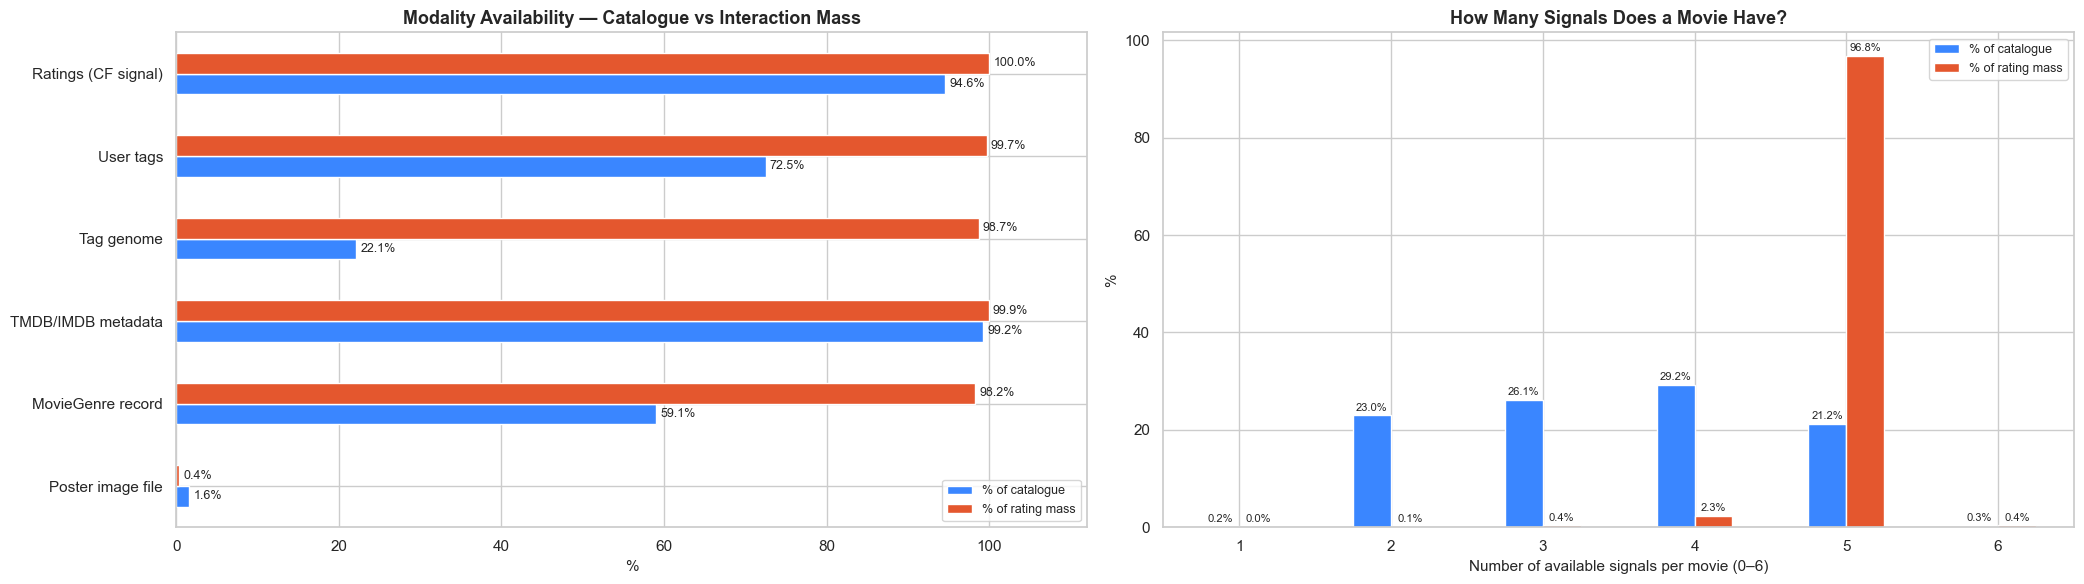

Full-stack titles (all 6 signals): 165 (0.26% of catalogue, 0.37% of ratings)
Titles with ratings but no content signal beyond genres: 381


In [61]:
mods = {"Ratings (CF signal)": "has_ratings", "User tags": "has_tags", "Tag genome": "has_genome",
        "TMDB/IMDB metadata": "in_meta_any", "MovieGenre record": "in_moviegenre", "Poster image file": "has_poster_file"}
w = cov["n_ratings"]
tab = pd.DataFrame({"% of catalogue": {k: cov[v].mean() * 100 for k, v in mods.items()},
                    "% of rating mass": {k: w[cov[v]].sum() / w.sum() * 100 for k, v in mods.items()}})
cov["n_modalities"] = cov[list(mods.values())].sum(axis=1)
nm = pd.DataFrame({"% of catalogue": cov["n_modalities"].value_counts(normalize=True).sort_index() * 100,
                   "% of rating mass": w.groupby(cov["n_modalities"]).sum() / w.sum() * 100}).fillna(0)
display(tab)

fig, ax = plt.subplots(1, 2, figsize=(21, 6))
tab.iloc[::-1].plot(kind="barh", ax=ax[0], color=["#3a86ff", "#e4572e"]); ax[0].set_xlim(0, 112)
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.1f%%", padding=3, fontsize=9)
ax[0].set_xlabel("%"); ax[0].set_title("Modality Availability — Catalogue vs Interaction Mass")
nm.plot(kind="bar", ax=ax[1], color=["#3a86ff", "#e4572e"], rot=0)
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.1f%%", padding=2, fontsize=8)
ax[1].set_xlabel("Number of available signals per movie (0–6)"); ax[1].set_ylabel("%"); ax[1].set_title("How Many Signals Does a Movie Have?")
plt.tight_layout(); plt.show()

full = cov["n_modalities"] == len(mods)
print(f"Full-stack titles (all {len(mods)} signals): {int(full.sum()):,} ({full.mean():.2%} of catalogue, {w[full].sum()/w.sum():.2%} of ratings)")
print(f"Titles with ratings but no content signal beyond genres: {int(((cov.has_ratings) & (~cov.has_genome) & (~cov.in_meta_any)).sum()):,}")
KPI.update(full_stack_titles=int(full.sum()), full_stack_rating_mass_pct=round(float(w[full].sum() / w.sum() * 100), 1))

### 📌 Observation
- Coverage by catalogue / by rating mass: **ratings 94.6% / 100%, metadata 99.2% / 99.9%, user tags 72.5% / 99.7%, MovieGenre record 59.1% / 98.2%, tag genome 22.1% / 98.7%, poster image file only 1.6% / 0.4%**.
- Right chart: movies with **5 of 6 signals are only 21.2% of the catalogue but carry 96.8% of all ratings**; titles with 2–4 signals are 78% of the catalogue but carry only ≈ 2.8% of the ratings.
- Just **165 titles (0.3% of the catalogue, 0.4% of ratings)** have all six signals — the poster images are the limiting modality. A further 381 rated titles have neither genome nor external metadata.

### 💡 Pipeline / Engineering Decision
- The model is a **modality-masked hybrid**: collaborative embedding (rated titles) + genome vector (13.8K popular titles) + text/metadata embedding (99% of titles) + optional poster embedding, each with an availability mask so a missing modality never breaks inference.
- Serving tiers: (1) **rich/warm titles (≈ 21% of titles, ≈ 97% of traffic)** → full hybrid, (2) **content-only titles** → metadata + genre similarity, (3) **dark titles** (no ratings, no genome) → genre + popularity prior.
- Because the poster branch covers 0.4% of rating mass, it must not be on the critical path; its value is measured separately by an ablation.

---
## 🔹 Step 30 — Movie-Level Feature Correlations (Spearman)

### ❓ Why
Correlations between engagement (ratings count), quality (mean rating), age and external metadata reveal redundancy and leakage before feature selection. Spearman (rank-based) is used because most variables are heavy-tailed.

### 💼 Business Insight
Highly correlated features inflate model complexity without adding information; and a feature that is just a proxy for the target (e.g. an external score copied from the same audience) can create over-optimistic results.

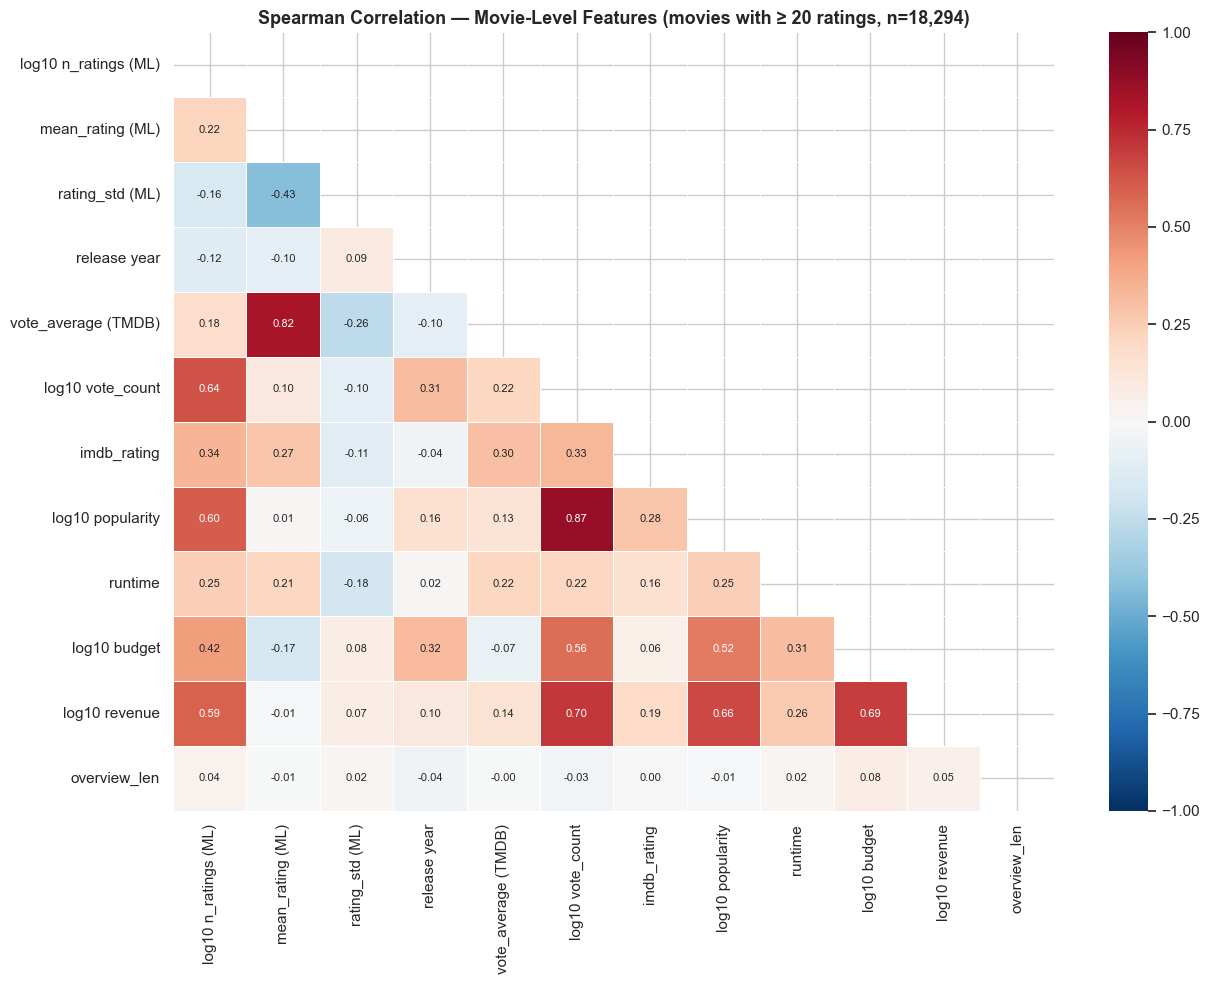

Strongest relationships:


,feature_A,feature_B,rho
0,log10 popularity,log10 vote_count,0.8721
1,vote_average (TMDB),mean_rating (ML),0.8229
2,log10 revenue,log10 vote_count,0.7041
3,log10 revenue,log10 budget,0.6894
4,log10 revenue,log10 popularity,0.6636
5,log10 vote_count,log10 n_ratings (ML),0.6397
6,log10 popularity,log10 n_ratings (ML),0.6042
7,log10 revenue,log10 n_ratings (ML),0.5909


In [62]:
f = pd.DataFrame({
  "log10 n_ratings (ML)": np.log10(joined["n_ratings"].clip(lower=1)),
  "mean_rating (ML)": joined["mean_rating"], "rating_std (ML)": joined["rating_std"], "release year": joined["year"],
  "vote_average (TMDB)": joined["vote_average"].where(joined["vote_count"] >= 10) if "vote_count" in joined else joined["vote_average"],
  "log10 vote_count": np.log10(joined["vote_count"].where(joined["vote_count"] > 0)),
  "imdb_rating": joined["imdb_rating"].where(joined["imdb_rating"] > 0),
  "log10 popularity": np.log10(joined["popularity"].where(joined["popularity"] > 0)),
  "runtime": joined["runtime"].where(joined["runtime"].between(1, 400)),
  "log10 budget": np.log10(joined["budget"].where(joined["budget"] > 0)),
  "log10 revenue": np.log10(joined["revenue"].where(joined["revenue"] > 0)),
  "overview_len": joined["overview_len"].where(joined["overview_len"] > 0)})
f = f.loc[:, f.notna().sum() >= 100]
f = f[joined["n_ratings"] >= 20]
corr = f.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, linewidths=.4)
plt.title(f"Spearman Correlation — Movie-Level Features (movies with ≥ 20 ratings, n={len(f):,})")
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack().rename("rho").reset_index(); pairs.columns = ["feature_A", "feature_B", "rho"]
pairs["abs"] = pairs.rho.abs(); print("Strongest relationships:"); display(pairs.sort_values("abs", ascending=False).head(8).drop(columns="abs").reset_index(drop=True))

### 📌 Observation
- On the 18,294 movies with ≥ 20 ratings the strongest relationships are **log popularity ↔ log vote_count 0.87**, **MovieLens mean ↔ TMDB vote_average 0.82**, revenue ↔ vote_count 0.70, revenue ↔ budget 0.69, revenue ↔ popularity 0.66, vote_count ↔ MovieLens n_ratings 0.64.
- **MovieLens popularity is essentially unrelated to quality**: `log n_ratings` ↔ `mean_rating` is only 0.22 and `popularity` ↔ `mean_rating` ≈ 0.01. `rating_std` ↔ `mean_rating` is **−0.43** (better-rated movies have more agreement).
- `imdb_rating` correlates only **0.27** with the MovieLens mean (vs 0.82 for TMDB) — again showing the column's poor quality; `overview_len` and `release year` are close to uncorrelated with everything.

### 💡 Pipeline / Engineering Decision
- The popularity/commercial cluster (`vote_count`, `popularity`, `revenue`, `budget`, `n_ratings`) is collapsed into **two features (`log vote_count`, `log n_ratings`)**; the rest only add multicollinearity.
- `vote_average` (shrunk) is the only external quality feature; `imdb_rating` is removed.
- `rating_std` is kept as a separate **controversy** feature, since it is only moderately (−0.43) related to the mean.
- Features derived from MovieLens means are computed **only on the training window** (leakage guard), because `mean_rating (ML)` is target-derived.

---
## 🔹 Step 31 — Baseline Benchmarks on the Temporal Split (RMSE & Popularity Hit-Rate)

### ❓ Why
Before building any complex model we need the numbers it must beat. Simple baselines (global mean, item mean, user + item bias, popularity ranking) on the chronological split define the minimum acceptable performance and show how much room exists for personalisation.

### 💼 Business Insight
Stakeholders judge a recommender by lift over "the simple thing". If a deep model improves RMSE by 0.002 over a bias baseline, the extra infrastructure cost is hard to justify; if a popularity list already achieves a high hit-rate, the incremental value of personalisation is smaller than assumed.

,RMSE,MAE,RMSE (cold items only)
Global mean,1.0649,0.8312,1.1053
Item mean (raw),0.9955,0.7601,1.1053
Item bias (damped),0.9908,0.7573,1.1053
User + Item bias (damped),0.9769,0.7440,1.0692


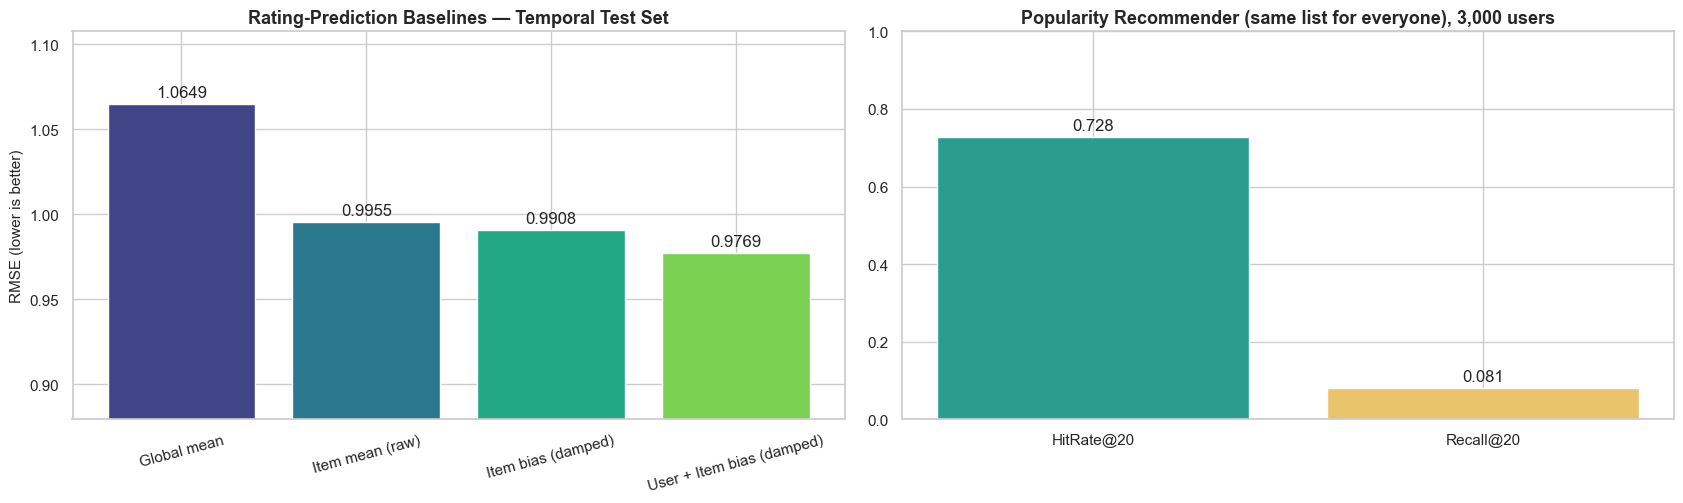

Test rows: 2,500,010 | cold-item test rows: 5.76% | global train mean μ = 3.5298
Improvement User+Item bias vs global mean: 8.3%


In [63]:
tr, te = temporal_train, ~temporal_train
u_tr, m_tr, r_tr = u_arr[tr], m_arr[tr], ratings["rating"].values[tr].astype("float64")
u_te, m_te, r_te = u_arr[te], m_arr[te], ratings["rating"].values[te].astype("float64")
nU, nM = int(u_arr.max()) + 1, int(m_arr.max()) + 1

mu = r_tr.mean()
cnt_i = np.bincount(m_tr, minlength=nM); sum_i = np.bincount(m_tr, weights=r_tr - mu, minlength=nM)
b_i = sum_i / (cnt_i + 10)                                                    # damped item bias (λ = 10)
resid = r_tr - mu - b_i[m_tr]
cnt_u = np.bincount(u_tr, minlength=nU); sum_u = np.bincount(u_tr, weights=resid, minlength=nU)
b_u = sum_u / (cnt_u + 15)                                                    # damped user bias (λ = 15)
item_only_mean = np.where(cnt_i > 0, mu + sum_i / np.maximum(cnt_i, 1), mu)

def rmse(p): return float(np.sqrt(np.mean((r_te - np.clip(p, 0.5, 5)) ** 2)))
def mae(p):  return float(np.mean(np.abs(r_te - np.clip(p, 0.5, 5))))
preds = {"Global mean": np.full(len(r_te), mu),
         "Item mean (raw)": item_only_mean[m_te],
         "Item bias (damped)": mu + b_i[m_te],
         "User + Item bias (damped)": mu + b_i[m_te] + b_u[u_te]}
base = pd.DataFrame({k: {"RMSE": rmse(v), "MAE": mae(v)} for k, v in preds.items()}).T
cold_item = cnt_i[m_te] == 0
base["RMSE (cold items only)"] = [float(np.sqrt(np.mean((r_te[cold_item] - np.clip(v[cold_item], .5, 5)) ** 2))) if cold_item.any() else np.nan for v in preds.values()]
display(base)

# ---- Popularity top-N baseline (leave-future-out)
rng2 = np.random.default_rng(SEED)
pos_te = r_te >= POSITIVE_THRESHOLD
cand_users = np.unique(u_te[pos_te]); sel_users = rng2.choice(cand_users, size=min(3000, len(cand_users)), replace=False)
pop_order = np.argsort(-cnt_i)[:2000]
seen = pd.DataFrame({"u": u_tr[np.isin(u_tr, sel_users)], "m": m_tr[np.isin(u_tr, sel_users)]}).groupby("u")["m"].apply(set)
tpos = pd.DataFrame({"u": u_te[pos_te & np.isin(u_te, sel_users)], "m": m_te[pos_te & np.isin(u_te, sel_users)]}).groupby("u")["m"].apply(set)
K = 20; hits, recalls = [], []
for u_ in sel_users:
    s, t = seen.get(u_, set()), tpos.get(u_, set())
    if not t: continue
    recs = [m for m in pop_order if m not in s][:K]
    h = len(t & set(recs)); hits.append(h > 0); recalls.append(h / len(t))
hit_rate, recall_k = float(np.mean(hits)), float(np.mean(recalls))

fig, ax = plt.subplots(1, 2, figsize=(17, 5.2))
b = ax[0].bar(base.index, base["RMSE"], color=sns.color_palette("viridis", len(base))); ax[0].bar_label(b, fmt="%.4f", padding=3)
ax[0].set_ylim(base["RMSE"].min() * 0.9, base["RMSE"].max() * 1.04); ax[0].set_ylabel("RMSE (lower is better)")
ax[0].set_title("Rating-Prediction Baselines — Temporal Test Set"); ax[0].tick_params(axis="x", rotation=15)
b = ax[1].bar([f"HitRate@{K}", f"Recall@{K}"], [hit_rate, recall_k], color=["#2a9d8f", "#e9c46a"]); ax[1].bar_label(b, fmt="%.3f", padding=3)
ax[1].set_ylim(0, 1); ax[1].set_title(f"Popularity Recommender (same list for everyone), {len(hits):,} users")
plt.tight_layout(); plt.show()

print(f"Test rows: {te.sum():,} | cold-item test rows: {cold_item.mean():.2%} | global train mean μ = {mu:.4f}")
print(f"Improvement User+Item bias vs global mean: {(1 - base.loc['User + Item bias (damped)','RMSE']/base.loc['Global mean','RMSE']):.1%}")
KPI.update(rmse_global=round(base.loc["Global mean", "RMSE"], 4), rmse_bias_baseline=round(base.loc["User + Item bias (damped)", "RMSE"], 4),
           pop_hitrate_at20=round(hit_rate, 3), pop_recall_at20=round(recall_k, 3))

### 📌 Observation
- RMSE on the 2,500,010 test rows: **global mean 1.0649 → raw item mean 0.9955 → damped item bias 0.9908 → user + item bias 0.9769 (−8.3% vs global)**; MAE falls from 0.831 to 0.744. Damped item bias beats raw item mean, confirming the small-sample effect of Step 15.
- The user-bias gain is small (0.9908 → 0.9769) because **78.99% of the test rows come from users who have no history** (Step 16), so their user bias is zero.
- **5.76% of test rows are cold items**; they fall back to the global mean (RMSE 1.1053) and still improve to 1.0692 once the user bias is added.
- Popularity ranking (same top-20 for everybody, 3,000 sampled users with a positive test rating): **HitRate@20 = 0.728, Recall@20 = 0.081** — a strong head-of-catalogue baseline (inflated because most sampled users are new and have no history to exclude).

### 💡 Pipeline / Engineering Decision
- Benchmark targets for CineMatch-Pro on the global temporal split: **beat RMSE 0.9769 (user + item bias) and beat popularity HitRate@20 = 0.728 / Recall@20 = 0.081**; every MLflow experiment logs these two baselines.
- Because the global split is mostly new users, a **second benchmark on the per-user chronological split** (Step 16 decision) is mandatory before judging personalisation.
- Models to build next: (1) ALS / implicit MF for the warm head, (2) two-tower / NCF with genome + metadata towers for cold items, (3) a hybrid blender with modality masks, (4) a calibrated / MMR re-ranker. Evaluation uses NDCG@10, Recall@20, coverage and novelty per serving tier.

---
## 🔹 Step 32 — EDA Scorecard & Executive Summary

### ❓ Why
Close the EDA with one consolidated scorecard of every computed KPI plus a decision register. This is the hand-off artefact between data analysis and the model-building team.

### 💼 Business Insight
Decision-makers read one page. A scorecard that maps each finding to a concrete engineering decision shows that the analysis changes how the system is built — not just what the data looks like.

In [64]:
score = pd.Series(KPI, dtype="object").rename("value").to_frame()
score.index.name = "KPI"
display(score)

summary = pd.DataFrame([
  ['Data size & types', '25,000,095 ratings, 62,423 movies, 2.23 GB tabular', 'int32/float32 dtypes (ratings = 400 MB), chunked metadata loader, sparse CSR matrices'],
  ['Rating profile', 'Left-skewed, mode 4.0 (26.6%), mean 3.53; 49.8% of ratings are positive', 'Implicit label = rating ≥ 4.0; bias-aware regression baseline'],
  ['Activity concentration', 'Median user 71 ratings; top 10% of users = 46.8% of ratings (Gini 0.589)', 'Per-user sampling cap; metrics by activity segment'],
  ['Long tail', 'Top 1% of movies = 47.6% of ratings; 47.6% of titles have < 5 ratings (Gini 0.942)', 'Hybrid model; popularity debiasing; coverage / novelty metrics'],
  ['Sparsity', '99.74% sparse; dense 38.4 GB vs CSR 0.20 GB', 'Sparse CSR; min-10-ratings filter for the CF branch only (keeps 99.56% of ratings)'],
  ['Temporal drift', 'Yearly mean rating 3.43–3.67; half-stars 0% before 2003, ≈ 40% after', 'Temporal evaluation; recency & age features; drift monitoring'],
  ['Cold start', 'Temporal split: 79.0% of test rows from unseen users, 5.8% unseen movies; random split ≈ 0%', 'Global + per-user temporal splits; warm/cold reporting; content fallback'],
  ['Small-sample means', 'Raw top-rated list = titles with only 2–3 ratings', 'Bayesian-shrunk ratings (m = 50) + confidence feature'],
  ['Content signals', 'Genome covers 22.1% of titles (98.7% of ratings); 100 PCs explain only ≈ 77%', 'Mean-centred genome PCA (≈ 128 d); SBERT on overview; modality masks'],
  ['Metadata quality', 'Budget 94.9%, revenue 98.1%, votes 67.5% zero/missing; IMDB_Rating 97.2% missing', '0/negative → NaN + known-flags; use TMDB vote_average only'],
  ['Join coverage', '99.24% of titles / 99.90% of ratings matched; MovieLens vs TMDB r = 0.86', 'tmdbId → imdbId fallback; year-agreement validation'],
  ['Reviews dataset', 'Balanced 25K / 25K, 418 duplicates, 58.4% with HTML, no movie key', 'Independent sentiment model; clean + de-duplicate before split'],
  ['Poster modality', '997 images, all 182×268 RGB, 1914–1933 era; 0.4% of rating mass', 'Frozen CLIP/ResNet embeddings; optional modality branch'],
  ['Baselines', 'RMSE 1.0649 (global) → 0.9769 (user+item bias); popularity HitRate@20 = 0.728', 'Targets for the hybrid model; add per-user split benchmark']
], columns=["Area", "Key finding", "Pipeline / engineering decision"])
with pd.option_context("display.max_colwidth", None):
    display(summary)

del genome_scores; gc.collect()
print("\n✅ EDA complete — all plots were rendered inline only; no plot files were written to disk.")

,value
KPI,
total_data_GB,2.2300
poster_images,997
n_ratings,25000095
n_users,162541
n_rated_movies,59047
n_catalog_movies,62423
dup_rating_pairs,0
mean_rating,3.5340
positive_share_pct,49.8000


,Area,Key finding,Pipeline / engineering decision
0,Data size & types,"25,000,095 ratings, 62,423 movies, 2.23 GB tabular","int32/float32 dtypes (ratings = 400 MB), chunked metadata loader, sparse CSR matrices"
1,Rating profile,"Left-skewed, mode 4.0 (26.6%), mean 3.53; 49.8% of ratings are positive",Implicit label = rating ≥ 4.0; bias-aware regression baseline
2,Activity concentration,Median user 71 ratings; top 10% of users = 46.8% of ratings (Gini 0.589),Per-user sampling cap; metrics by activity segment
3,Long tail,Top 1% of movies = 47.6% of ratings; 47.6% of titles have < 5 ratings (Gini 0.942),Hybrid model; popularity debiasing; coverage / novelty metrics
4,Sparsity,99.74% sparse; dense 38.4 GB vs CSR 0.20 GB,Sparse CSR; min-10-ratings filter for the CF branch only (keeps 99.56% of ratings)
5,Temporal drift,"Yearly mean rating 3.43–3.67; half-stars 0% before 2003, ≈ 40% after",Temporal evaluation; recency & age features; drift monitoring
6,Cold start,"Temporal split: 79.0% of test rows from unseen users, 5.8% unseen movies; random split ≈ 0%",Global + per-user temporal splits; warm/cold reporting; content fallback
7,Small-sample means,Raw top-rated list = titles with only 2–3 ratings,Bayesian-shrunk ratings (m = 50) + confidence feature
8,Content signals,Genome covers 22.1% of titles (98.7% of ratings); 100 PCs explain only ≈ 77%,Mean-centred genome PCA (≈ 128 d); SBERT on overview; modality masks
9,Metadata quality,"Budget 94.9%, revenue 98.1%, votes 67.5% zero/missing; IMDB_Rating 97.2% missing",0/negative → NaN + known-flags; use TMDB vote_average only



✅ EDA complete — all plots were rendered inline only; no plot files were written to disk.


### 📌 Observation
- The KPI table consolidates the run: **25,000,095 ratings, 162,541 users, 59,047 rated movies, sparsity 99.74%, user Gini 0.589, item Gini 0.942, temporal cut-off 2018-01-04 with 79% unseen test users, metadata join 99.2% / 99.9%, baseline RMSE 1.0649 → 0.9769, popularity HitRate@20 0.728**.
- The decision register shows that each finding changed a concrete engineering choice (dtypes, split, shrinkage, thresholds, modality masks).
- Findings that went against the initial expectations: item concentration is far stronger than user concentration (top 1% of movies = 47.6% of ratings), the genome is not very compressible (≈ 77% variance at 100 PCs, 80% only at 131 PCs), the global temporal split is dominated by new users (79%), and `IMDB_Rating` / `keywords` / `director` in the 1M file are unreliable.

### 💡 Pipeline / Engineering Decision
- Pipeline order: `src/data_loader.py` (dtype map + chunked metadata) → `src/split.py` (global temporal + per-user split) → `src/features.py` (shrunk ratings, genome PCA, SBERT, optional poster embeddings) → `src/train_cf.py`, `src/train_hybrid.py` → Champion-Challenger gates → FastAPI serving + Streamlit monitoring.
- The KPI table is frozen as the **data-validation baseline**: a refreshed dataset whose join coverage, sparsity, rating mean or null rates deviate materially (PSI) triggers review before retraining.
- Open items to close before modelling: placeholder check for `keywords` / `director`, a source for Indian-language titles, and a poster source beyond the 997-image sample.

---
## ✅ End of EDA — CineMatch-Pro
**32 analysis steps · 4 datasets · 6 modalities.** Every step follows the *Why → Business Insight → Code & Plot → Observation → Pipeline / Engineering Decision* structure, and all visualisations are inline-only (no files saved).